# Apoio à decisão na interrupção da ventilação mecânica
### Duas redes Naive Bayes e um sistema de inferência fuzzy Mamdani

**Disciplina:** Sistemas Probabilísticos e Difusos — IFSC  
**Autor:** Luiz Eduardo do Nascimento Ciarallo<br>
**Professor:** Cesar Alberto Penz  
**Base de dados:** Ashutosh *et al.*, *Critical Care Medicine*, 1992 (21 casos de treino + 9 de teste)  
**Data:** outubro de 2026

---

Este notebook reproduz integralmente o projeto: análise exploratória, discretização clínica e automática, redes Naive Bayes, sistema Mamdani com 81 regras, avaliação nos 30 casos e os três estudos de caso exigidos. Todo o código de apoio está em `src/weaning_lib.py`; as tabelas e figuras são gravadas em `tables/` e `figures/`.

> **Convenção:** a classe positiva é **Sucesso** (o paciente pode ser liberado). Assim, a sensibilidade mede a capacidade de reconhecer quem realmente pode sair do ventilador; a especificidade mede a capacidade de reter quem fracassaria. Falso positivo = liberação prematura; falso negativo = atraso na liberação.

## Como este notebook está organizado

O notebook segue exatamente os itens do trabalho e exibe **as 19 figuras uma a uma**. Cada seção indica o passo correspondente:

| Seção | Passo do trabalho | O que será mostrado |
|---|---|---|
| 1 | Descrição do processo e base | Dados, análise exploratória, correlações e protocolo antileakage |
| 2 | Item 2(a–c) — Naive Bayes | Topologia, as duas discretizações, CPTs, tabelas caso a caso, um cálculo posterior passo a passo, matrizes de confusão, métricas, limiares e divergências |
| 3 | Item 3(a) — Fuzzy | Operadores Mamdani, universos, funções de pertinência, 81 regras, completude, avaliação nos 30 casos, limiares e superfícies |
| 4 | Item 3(b) — Exemplos | TE5 (sucesso), TR10 (fracasso) e TE3 (crítico): fuzzificação, regras ativadas, agregação e centroide |
| 5 | Item 4 — Fechamento | Comparação final, conclusão e limitações |
| 6 | Reprodutibilidade | Validações, arquivos e checklist de conformidade |

**Mapa das figuras:** 1 distribuições; 2 topologia; 3 matrizes NB; 4 métricas NB; 5 divergência entre redes; 6 cortes de discretização; 7 funções de pertinência; 8 regras; 9 superfície NIF×RR; 10 superfície VT×RSBI; 11 saída fuzzy nos 30 casos; 12 matrizes fuzzy; 13–18 casos TE5/TR10/TE3 (entrada e saída); 19 comparação final.

> **Execução nativa comprovada:** os cortes da Rede 2 foram gerados pelo Netica Application 7.01, com dois estados, 20% de arredondamento e apenas os 21 casos de treino. A rede foi aprendida pelo Netica C API 5.04; ambas as redes foram avaliadas pelo motor nativo e confrontadas com o Python. Capturas reais, rede, casos, log e hashes estão em `netica/evidencias/`.

## 0. Preparação do ambiente

O notebook pressupõe Python 3.11+ com `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-fuzzy`, `scikit-learn` e `statsmodels`. O caminho do projeto é detectado automaticamente a partir do diretório do notebook.

In [1]:
from pathlib import Path
import sys, json, itertools, warnings, math

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

import weaning_lib as w
import plotting

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

FIG = ROOT / "figures"
TAB = ROOT / "tables"
print("Projeto:", ROOT)
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)

Projeto: /home/lciarallo/Documentos/Git_projects/weaning-ifsc
Python: 3.14.8
pandas: 3.0.3


## 1. Dados e análise exploratória

A base contém 21 tentativas de interrupção para treinamento (9 sucessos e 12 fracassos) e 9 para teste (3 fracassos e 6 sucessos). As variáveis são:

- **NIF/PImax** — pico negativo da pressão inspiratória (cm.H₂O); valores mais negativos indicam maior força.
- **RR** — frequência respiratória (resp/min).
- **VT** — volume tidal (mL).
- **RSBI** — *Rapid Shallow Breathing Index* = RR / VT(L) (resp/min/L).

O RSBI é uma variável derivada: `RSBI = RR / (VT/1000)`. Essa dependência será discutida na seção de Naive Bayes.

In [2]:
train, test, full = w.load_data()
print(f"Treino: {train.shape[0]} casos | Teste: {test.shape[0]} casos | Completa: {full.shape[0]} casos")
display(train["Resultado"].value_counts().rename("Treino").to_frame().T)
display(test["Resultado"].value_counts().rename("Teste").to_frame().T)
display(full[["ID","NIF","RR","VT","RSBI","Resultado"]].head(10))

Treino: 21 casos | Teste: 9 casos | Completa: 30 casos


Resultado,Fracasso,Sucesso
Treino,12,9


Resultado,Sucesso,Fracasso
Teste,6,3


,ID,NIF,RR,VT,RSBI,Resultado
0,TR1,-30,17,500,34,Fracasso
1,TR2,-26,44,265,166,Fracasso
2,TR3,-18,32,370,86,Fracasso
3,TR4,-22,30,350,86,Fracasso
4,TR5,-10,29,320,91,Fracasso
5,TR6,-20,46,225,204,Fracasso
6,TR7,-24,38,276,138,Fracasso
7,TR8,-15,40,270,148,Fracasso
8,TR9,-12,32,220,145,Fracasso
9,TR10,-20,33,124,266,Fracasso


In [3]:
desc = w.descriptive_table(full)
display(desc[["Variável","Desfecho","n","Média ± DP","Mínimo","Máximo"]])

,Variável,Desfecho,n,Média ± DP,Mínimo,Máximo
0,NIF,Fracasso,15,-21.0 ± 6.1,-30,-10
1,NIF,Sucesso,15,-38.8 ± 10.4,-60,-23
2,RR,Fracasso,15,33.3 ± 8.0,17,46
3,RR,Sucesso,15,22.5 ± 4.8,13,30
4,VT,Fracasso,15,326.1 ± 99.4,124,500
5,VT,Sucesso,15,552.7 ± 213.7,250,950
6,RSBI,Fracasso,15,117.9 ± 60.8,34,266
7,RSBI,Sucesso,15,50.0 ± 29.3,14,120


**Figura 1 — distribuição das variáveis por desfecho.**

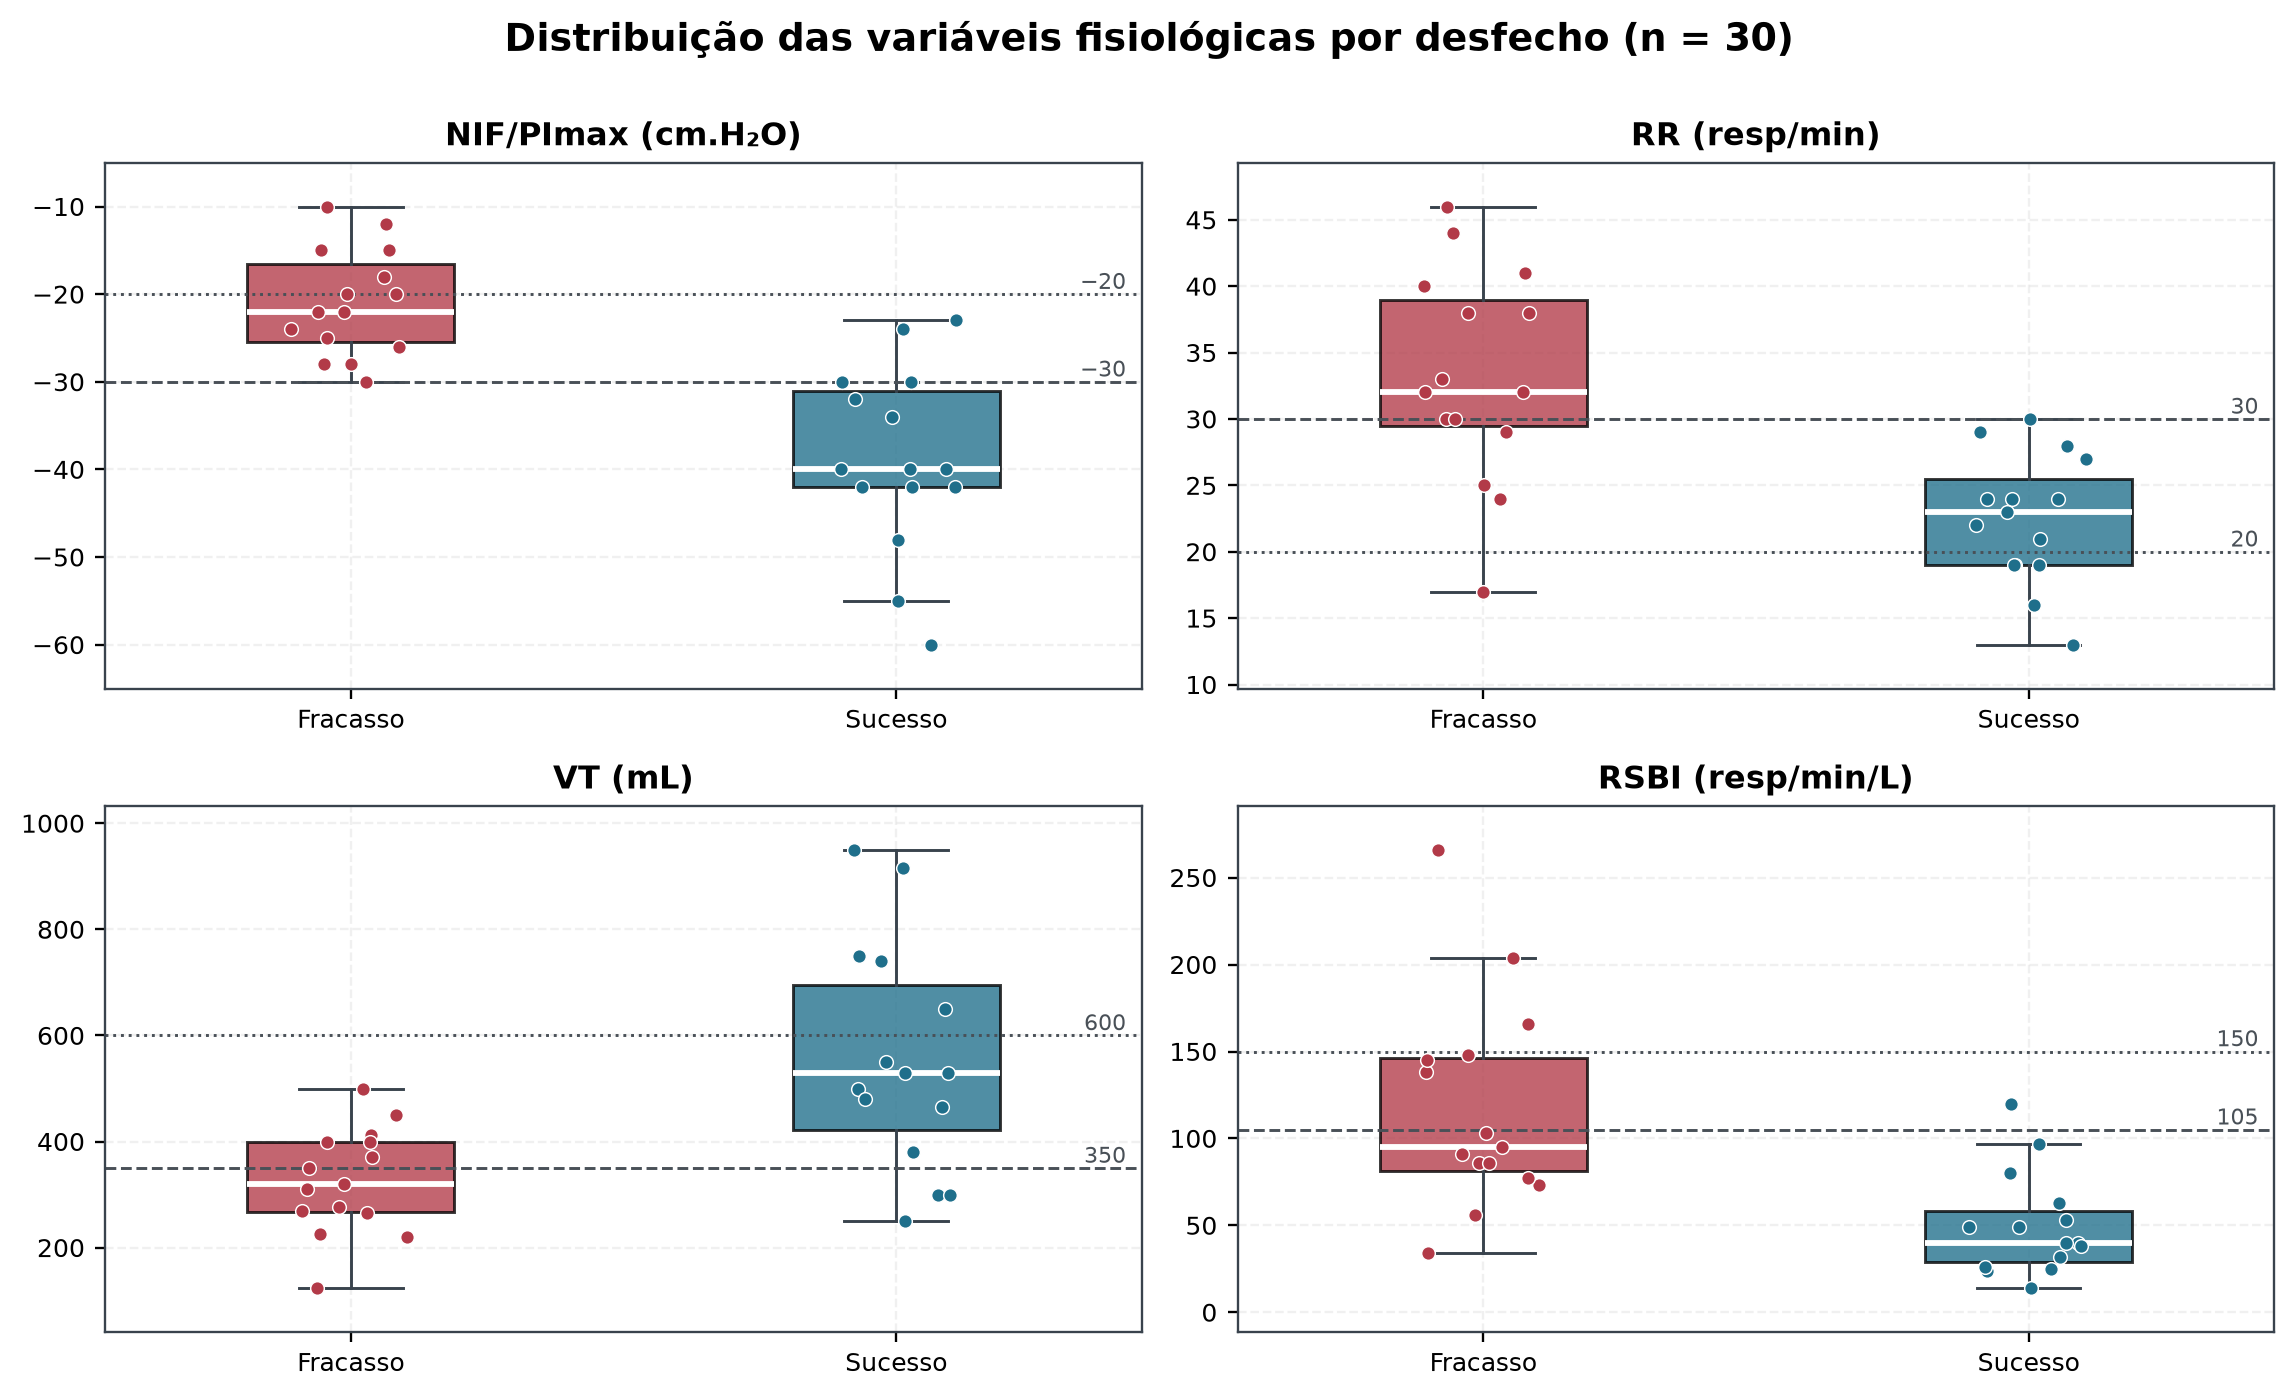

In [4]:
display(Markdown("**Figura 1 — distribuição das variáveis por desfecho.**"))
display(Image(filename=str(FIG / "fig01_distribuicoes.png"), width=1050))

**Leitura clínica.** Há separação parcial entre os grupos: pacientes com sucesso tendem a apresentar NIF mais negativo, menor RR e maior VT. Há, porém, sobreposição importante — em especial VT, RSBI e RR —, o que justifica modelos que representem incerteza e não apenas cortes rígidos. O caso TR1 é um exemplo de sobreposição extrema: todos os indicadores parecem favoráveis, mas o desfecho real foi fracasso.

In [5]:
corr = full[["NIF","RR","VT","RSBI"]].corr(method="spearman").round(2)
display(corr)

calc = full["RR"] / (full["VT"] / 1000)
print("Máxima diferença absoluta entre RSBI informado e RR/(VT/1000):", round(float((calc - full["RSBI"]).abs().max()), 3))

,NIF,RR,VT,RSBI
NIF,1.000,0.700,-0.720,0.750
RR,0.700,1.000,-0.750,0.910
VT,-0.720,-0.750,1.000,-0.940
RSBI,0.750,0.910,-0.940,1.000


Máxima diferença absoluta entre RSBI informado e RR/(VT/1000): 0.5


A correlação de Spearman é muito alta entre RSBI e RR (0,91) e entre RSBI e VT (−0,94), como esperado pela definição. Isso antecipa o problema de dupla contagem no Naive Bayes: RR, VT e RSBI não são evidências condicionalmente independentes.

### 1.1 Protocolo antileakage

1. Os 9 casos de teste **não** participam da escolha de limiares, da estimação de CPTs, da escolha de funções de pertinência ou da calibração de regras.
2. A Rede 2 usa somente os 21 casos de treino para reproduzir os cortes automáticos.
3. As funções de pertinência fuzzy vêm da literatura clínica, não de ajuste aos dados.
4. O limiar operacional conservador do fuzzy (60) é uma decisão de política clínica, não um parâmetro ajustado ao teste.
5. A validação *leave-one-out* é feita exclusivamente no treino.

## 2. Redes Naive Bayes

### 2.1 Topologia e regra de decisão

A rede tem um nó pai `Desmame` (estados `Fracasso` e `Sucesso`) e quatro filhos: `NIF`, `RR`, `VT` e `RSBI`. A hipótese de independência condicional permite escrever

$$
P(C \\mid x_1,\\ldots,x_4) \\propto P(C)\\prod_{j=1}^{4}P(x_j \\mid C),
$$

e a decisão é a classe de maior probabilidade posterior. As probabilidades são estimadas por máxima verossimilhança com **suavização de Laplace** ($\\alpha=1$):

$$
P(x_j=s \\mid C=c)=\\frac{N_{cjs}+\\alpha}{N_c+\\alpha K_j}.
$$

A suavização evita probabilidades nulas em estados não observados no treino — situação provável com apenas 21 casos.

**Figura 2 — topologia das duas redes e suas grades de discretização.**

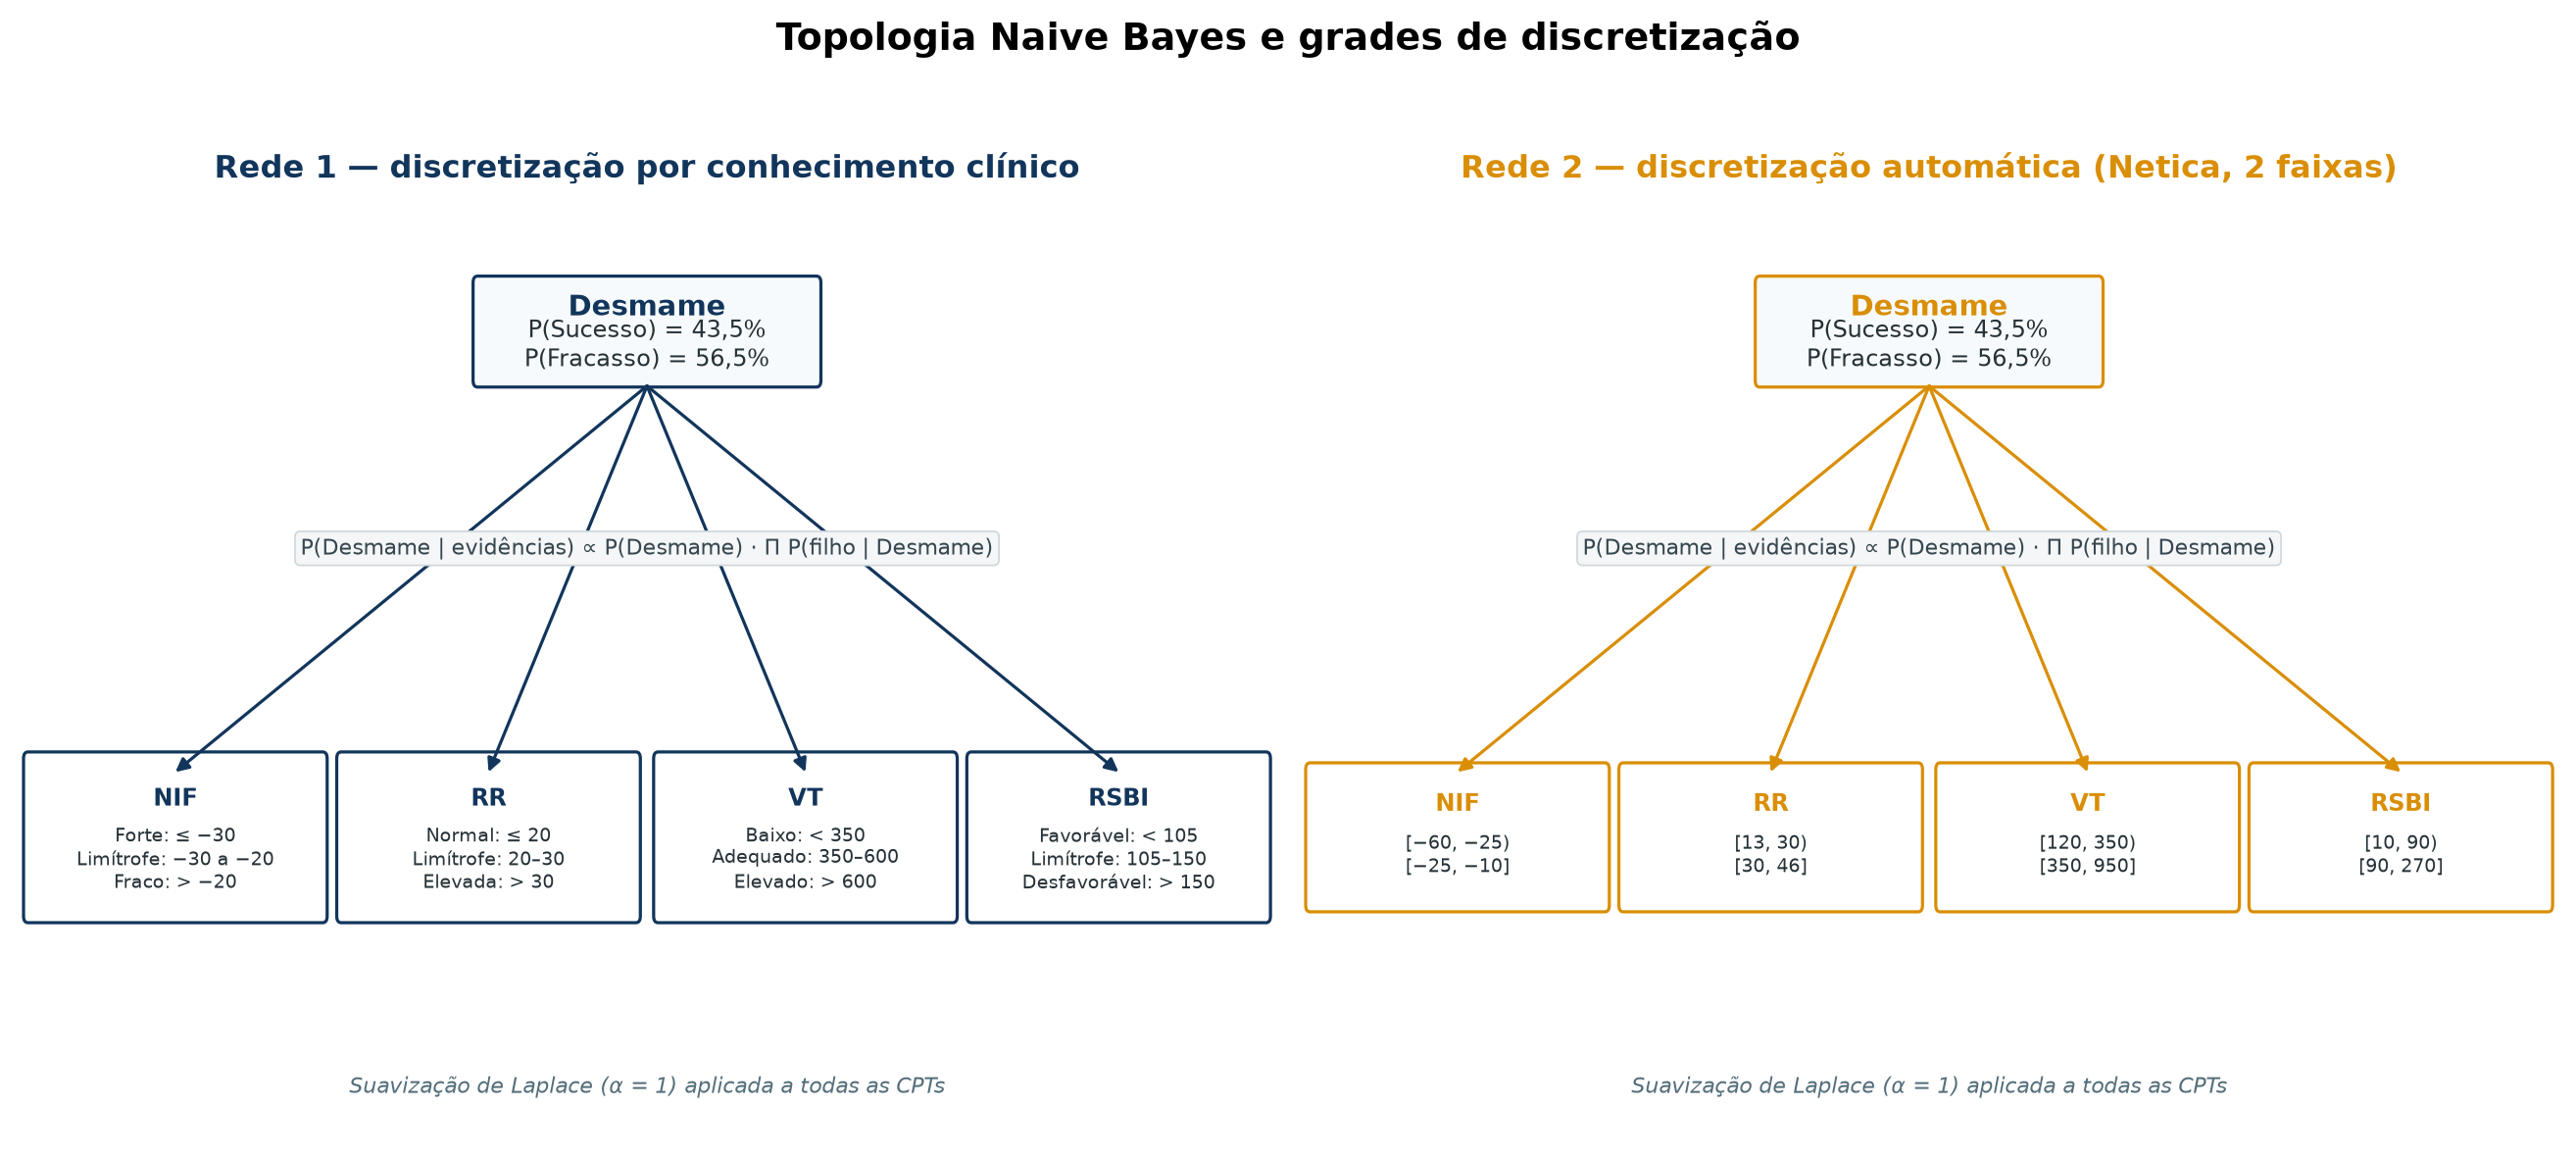

In [6]:
display(Markdown("**Figura 2 — topologia das duas redes e suas grades de discretização.**"))
display(Image(filename=str(FIG / "fig02_topologia_nb.png"), width=1100))

### 2.2 Nuance obrigatória: RR, VT e RSBI simultaneamente

O RSBI é uma função determinística de RR e VT. Incluir os três nós viola a hipótese de independência condicional: a mesma informação sobre o padrão respiratório é contada duas ou três vezes. Em termos práticos, o Naive Bayes pode produzir posteriores excessivamente extremos (perto de 0% ou 100%) e parecer mais confiável do que realmente é.

**Decisão adotada:** manter as quatro variáveis nas duas redes principais, para responder exatamente ao escopo do trabalho e permitir comparação direta entre as discretizações. Como análise de robustez, a validação *leave-one-out* no treino compara o conjunto completo com subconjuntos (Seção 2.10). A redundância é, portanto, explicitada e medida — não ignorada.

### 2.3 Rede 1 — discretização por conhecimento clínico

Os cortes foram definidos a partir da base de conhecimento da disciplina, do III Consenso Brasileiro de Ventilação Mecânica, de Yang & Tobin (1991), Silva *et al.* (2015), Hess & Kacmarek e do material da Dräger. A tabela completa está em `tables/02_discretizacao_clinica.csv`.

In [7]:
clinical = pd.read_csv(TAB / "02_discretizacao_clinica.csv")
display(clinical)

,Variável,Estado,Faixa,Justificativa clínica
0,NIF,Forte,≤ −30 cm.H₂O,PImax ≤ −30 cm.H₂O (pressão mais negativa) é c...
1,NIF,Limítrofe,−30 a −20 cm.H₂O,Faixa de transição entre o corte de sucesso (<...
2,NIF,Fraco,> −20 cm.H₂O,NIF > −20 cm.H₂O (pressão menos negativa) asso...
3,RR,Normal,≤ 20 resp/min,Frequência respiratória ≤ 20 resp/min situa-se...
4,RR,Limítrofe,20–30 resp/min,"RR entre 20 e 30 resp/min ainda é aceitável, m..."
5,RR,Elevada,> 30 resp/min,RR > 30 resp/min (sobretudo ≥ 35) sugere desco...
6,VT,Baixo,< 350 mL,VT < 350 mL aproxima-se de < 5 mL/kg (paciente...
7,VT,Adequado,350–600 mL,"VT entre 350 e 600 mL (≈ 5–8,5 mL/kg) situa-se..."
8,VT,Elevado,> 600 mL,VT > 600 mL é supra fisiológico em repouso; nã...
9,RSBI,Favorável,< 105 resp/min/L,RSBI < 105 resp/min/L é o limiar clássico (Yan...


**Justificativa dos cortes.** O limiar de NIF em −30 cm.H₂O é clássico para força muscular; a faixa −30 a −20 é explicitamente uma zona de incerteza, e valores acima de −20 (menos negativos) associam-se a falha. Para RR, 30 resp/min é o limite superir da faixa de sucesso em várias referências, enquanto 20 delimita a faixa de repouso. Para VT, 350 mL aproxima 5 mL/kg em um adulto de 70 kg e 315 mL é referência de sucesso. Para RSBI, 105 é o corte clássico; 150 delimita a faixa de alto risco. As transições entre estados não são “naturais”: são escolhas clínicas explícitas, e por isso a Rede 2 será comparada.

### 2.4 Rede 2 — discretização automática executada pelo Netica

A Rede 2 foi discretizada pelo comando **Modify > Auto-Discretize Nodes** do Netica Application 7.01, com **dois intervalos por variável e 20% de arredondamento**, usando somente `netica/treino_discretizacao.cas` (21 casos, quatro entradas, sem desfecho). A semântica é `[inferior, superior)`: o limite inferior pertence ao intervalo, o superior não (exceto a última faixa). Os níveis foram lidos do arquivo salvo pelo próprio Netica:

- NIF: `[−60, −25)` e `[−25, −10]`
- RR: `[13, 30)` e `[30, 46]`
- VT: `[120, 350)` e `[350, 950]`
- RSBI: `[10, 90)` e `[90, 270]`

O corte de RSBI 90 foi uma saída do Netica, cuja opção de arredondamento foi fixada em 20% antes da avaliação. A mediana do treino (86) aparece apenas como estatística descritiva. O Python lê os níveis da rede nativa, sem conter cortes alternativos. Os hashes e a comparação das entradas com o treino são verificados antes de gerar os artefatos.

,Variável,Corte adotado,Mediana treino,n faixa inferior,n faixa superior,Diferença,Intervalos
0,NIF,-25.000,-25.000,10,11,1,"[−60, −25) | [−25, −10]"
1,RR,30.000,30.000,10,11,1,"[13, 30) | [30, 46]"
2,VT,350.000,350.000,10,11,1,"[120, 350) | [350, 950]"
3,RSBI,90.000,86.000,11,10,1,"[10, 90) | [90, 270]"


,Variável,Rede 1 (clínica),Rede 2 (Netica),Efeito
0,NIF,−30 e −20 cm.H₂O (3 faixas),−25 cm.H₂O (2 faixas),O corte automático cai no meio da zona de ince...
1,RR,20 e 30 resp/min (3 faixas),30 resp/min (2 faixas),"A Rede 2 preserva o limiar superior, mas não d..."
2,VT,350 e 600 mL (3 faixas),350 mL (2 faixas),A Rede 2 separa apenas baixo volume; perde a f...
3,RSBI,105 e 150 resp/min/L (3 faixas),90 resp/min/L (2 faixas),O corte automático é mais baixo que o clássico...


**Execução real no Netica 7.01 — rede aprendida e compilada.**

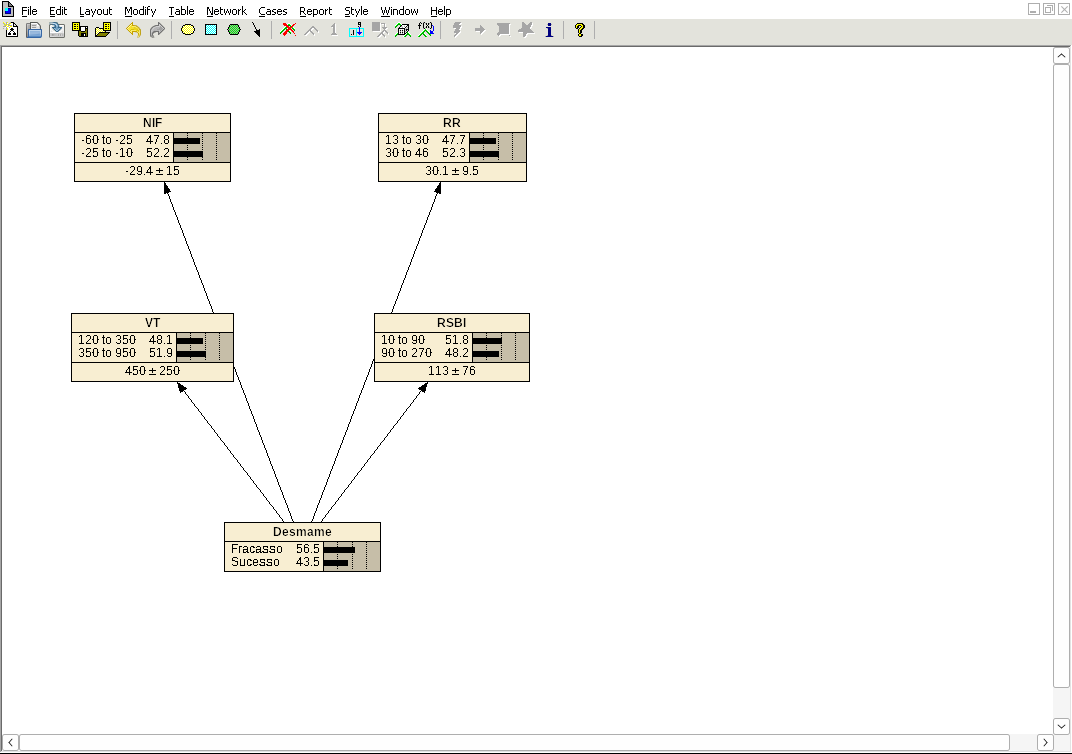

In [8]:
audit = pd.read_csv(TAB / "04_auditoria_netica.csv")
display(audit)
compare = pd.read_csv(TAB / "03_comparacao_limiares.csv")
display(compare)
display(Markdown("**Execução real no Netica 7.01 — rede aprendida e compilada.**"))
display(Image(filename=str(ROOT / "netica/evidencias/05_rede_aprendida.png"), width=1000))

**Figura 6 — onde os cortes caem na distribuição.** A linha tracejada representa os cortes clínicos da Rede 1; a linha cheia representa o corte automático da Rede 2. Os pontos pretos são os 21 casos de treino e os triângulos cinza são os 9 casos de teste. Note que o corte de NIF em −25 cai no meio da faixa clínica de incerteza (−30 a −20), o corte de RR coincide com 30, o de VT coincide com 350 e o de RSBI (90) fica abaixo do clássico 105.

**Figura 6 — cortes de discretização: conhecimento clínico versus Netica.**

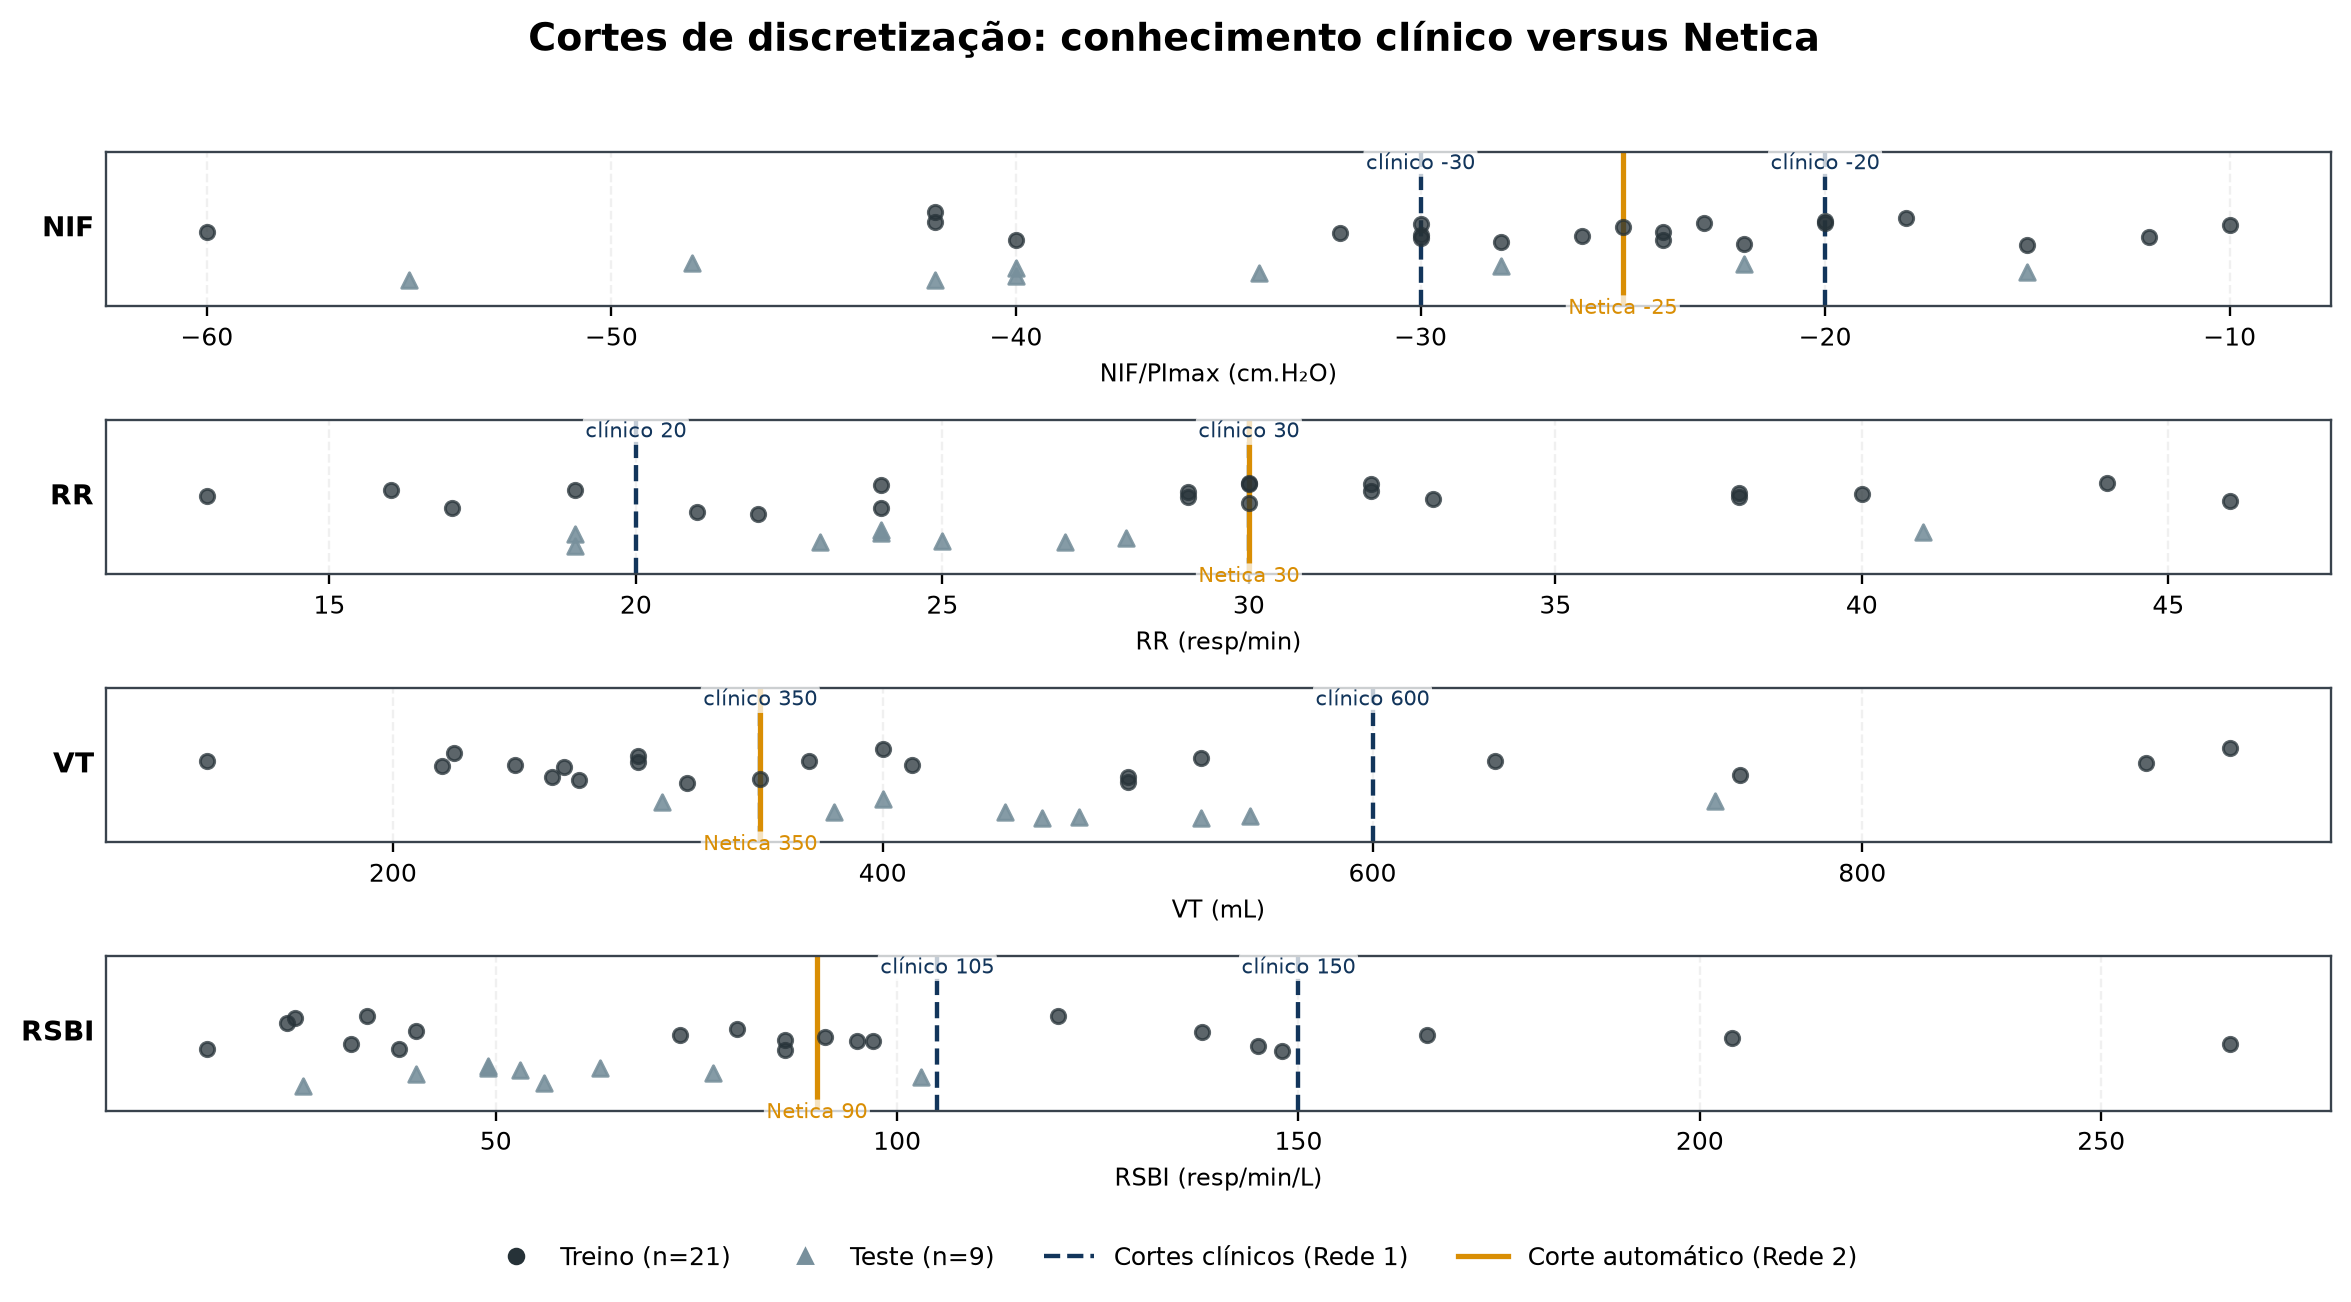

In [9]:
display(Markdown("**Figura 6 — cortes de discretização: conhecimento clínico versus Netica.**"))
display(Image(filename=str(FIG / "fig06_limiares.png"), width=1050))

A execução nativa agora obtém `Desmame` com 56,5% de fracasso e 43,5% de sucesso, também observado na captura original do professor. Para aprender com Laplace $\\alpha=1$, o Netica inicia cada linha com duas probabilidades de 0,5 e experiência 2, acrescentando as contagens dos 21 casos pelo método `ReviseCPTsByCaseFile_bn`. Os nove casos de teste só são usados depois dessa aprendizagem, sem inserir o desfecho como evidência.

### 2.5 Probabilidades condicionais aprendidas

A tabela completa de CPTs está em `tables/08_nb_cpt.csv`. Abaixo, as priors e as verossimilhanças das variáveis mais discriminativas.

In [10]:
models = {
    "Rede 1 (clínica)": w.fit_naive_bayes(train, "clinical"),
    "Rede 2 (Netica)": w.fit_naive_bayes(train, "netica"),
}
prior = pd.DataFrame([{"Rede": k, "P(Fracasso)": v.priors["Fracasso"], "P(Sucesso)": v.priors["Sucesso"]} for k, v in models.items()])
display(prior)

cpt = pd.read_csv(TAB / "08_nb_cpt.csv")
for var in ["NIF", "RSBI"]:
    piv = cpt[cpt["Variável"] == var].pivot_table(index=["Rede","Estado"], columns="Classe", values="P(estado | classe)").reset_index()
    display(Markdown(f"**{var}**"))
    display(piv)

,Rede,P(Fracasso),P(Sucesso)
0,Rede 1 (clínica),0.565,0.435
1,Rede 2 (Netica),0.565,0.435


**NIF**

Classe,Rede,Estado,Fracasso,Sucesso
0,Rede 1 (clínica),Forte,0.133,0.667
1,Rede 1 (clínica),Fraco,0.333,0.083
2,Rede 1 (clínica),Limítrofe,0.533,0.250
3,Rede 2 (Netica),< −25,0.286,0.727
4,Rede 2 (Netica),≥ −25,0.714,0.273


**RSBI**

Classe,Rede,Estado,Fracasso,Sucesso
0,Rede 1 (clínica),Desfavorável,0.267,0.083
1,Rede 1 (clínica),Favorável,0.467,0.750
2,Rede 1 (clínica),Limítrofe,0.267,0.167
3,Rede 2 (Netica),< 90,0.357,0.727
4,Rede 2 (Netica),≥ 90,0.643,0.273


### 2.6 Resultados caso a caso

As tabelas abaixo trazem os valores originais, o desfecho real, as probabilidades posteriores de cada rede e a classe predita com limiar de 50%. As probabilidades estão em porcentagem. **F** = Fracasso; **S** = Sucesso.

In [11]:
def nb_case_view(df, p1, p2):
    out = df[["ID","NIF","RR","VT","RSBI","Resultado"]].copy().reset_index(drop=True)
    out["Real"] = out["Resultado"].map({"Fracasso":"F", "Sucesso":"S"})
    out["R1 P(S)%"] = (p1["p_sucesso"].to_numpy() * 100).round(1)
    out["R1 P(F)%"] = (p1["p_fracasso"].to_numpy() * 100).round(1)
    out["R1 pred."] = p1["predito"].map({"Fracasso":"F", "Sucesso":"S"}).to_numpy()
    out["R2 P(S)%"] = (p2["p_sucesso"].to_numpy() * 100).round(1)
    out["R2 P(F)%"] = (p2["p_fracasso"].to_numpy() * 100).round(1)
    out["R2 pred."] = p2["predito"].map({"Fracasso":"F", "Sucesso":"S"}).to_numpy()
    out["R1"] = p1["predito"].eq(out["Resultado"]).map({True:"✓", False:"✗"}).to_numpy()
    out["R2"] = p2["predito"].eq(out["Resultado"]).map({True:"✓", False:"✗"}).to_numpy()
    return out.drop(columns=["Resultado"])

p1_train = models["Rede 1 (clínica)"].predict(train)
p2_train = models["Rede 2 (Netica)"].predict(train)
p1_test = models["Rede 1 (clínica)"].predict(test)
p2_test = models["Rede 2 (Netica)"].predict(test)
p1_full = models["Rede 1 (clínica)"].predict(full)
p2_full = models["Rede 2 (Netica)"].predict(full)

display(Markdown("**Treinamento (21 casos)**"))
display(nb_case_view(train, p1_train, p2_train))

**Treinamento (21 casos)**

,ID,NIF,RR,VT,RSBI,Real,R1 P(S)%,R1 P(F)%,R1 pred.,R2 P(S)%,R2 P(F)%,R2 pred.,R1,R2
0,TR1,-30,17,500,34,F,90.600,9.400,S,95.800,4.200,S,✗,✗
1,TR2,-26,44,265,166,F,1.000,99.000,F,10.900,89.100,F,✓,✓
2,TR3,-18,32,370,86,F,2.600,97.400,F,17.000,83.000,F,✓,✓
3,TR4,-22,30,350,86,F,44.200,55.800,F,17.000,83.000,F,✓,✓
4,TR5,-10,29,320,91,F,29.700,70.300,F,23.200,76.800,F,✓,✓
5,TR6,-20,46,225,204,F,1.000,99.000,F,1.800,98.200,F,✓,✓
6,TR7,-24,38,276,138,F,1.900,98.100,F,1.800,98.200,F,✓,✓
7,TR8,-15,40,270,148,F,1.000,99.000,F,1.800,98.200,F,✓,✓
8,TR9,-12,32,220,145,F,1.000,99.000,F,1.800,98.200,F,✓,✓
9,TR10,-20,33,124,266,F,1.000,99.000,F,1.800,98.200,F,✓,✓


In [12]:
display(Markdown("**Teste (9 casos)**"))
display(nb_case_view(test, p1_test, p2_test))

**Teste (9 casos)**

,ID,NIF,RR,VT,RSBI,Real,R1 P(S)%,R1 P(F)%,R1 pred.,R2 P(S)%,R2 P(F)%,R2 pred.,R1,R2
0,TE1,-15,25,450,56,F,29.700,70.300,F,77.200,22.800,S,✓,✗
1,TE2,-22,41,400,103,F,4.800,95.200,F,4.100,95.900,F,✓,✓
2,TE3,-28,24,310,77,F,44.200,55.800,F,90.600,9.400,S,✓,✗
3,TE4,-40,23,465,49,S,89.400,10.600,S,95.800,4.200,S,✓,✓
4,TE5,-48,24,380,63,S,89.400,10.600,S,95.800,4.200,S,✓,✓
5,TE6,-34,28,530,53,S,89.400,10.600,S,95.800,4.200,S,✓,✓
6,TE7,-40,19,740,26,S,99.000,1.000,S,95.800,4.200,S,✓,✓
7,TE8,-42,27,550,49,S,89.400,10.600,S,95.800,4.200,S,✓,✓
8,TE9,-55,19,480,40,S,90.600,9.400,S,95.800,4.200,S,✓,✓


### 2.6.1 Passo a passo de uma inferência Naive Bayes — TE3 na Rede 1

Para tornar o cálculo auditável, vamos abrir a inferência do caso **TE3** na Rede 1. O TE3 tem NIF −28, RR 24, VT 310 e RSBI 77. A rotina abaixo mostra, para cada classe, a prior, o estado observado de cada variável, a verossimilhança P(estado | classe) e o logaritmo correspondente. Depois soma os logaritmos, normaliza e compara com a saída da rede.

In [13]:
def explain_nb(case_id, model, df):
    row = df.loc[df.ID == case_id].iloc[0]
    rec = w.discretize(pd.DataFrame([row]), model.method).iloc[0]
    rows = []
    for cls in w.CLASSES:
        rows.append({
            "Classe": cls, "Componente": "prior", "Variável": "—", "Estado": "—",
            "Probabilidade": model.priors[cls], "log": math.log(model.priors[cls]),
        })
        for var in w.VARIABLES:
            state = rec[var]
            prob = model.likelihoods[var][cls][state]
            rows.append({
                "Classe": cls, "Componente": f"P({var} = {state} | classe)",
                "Variável": var, "Estado": state,
                "Probabilidade": prob, "log": math.log(prob),
            })
    tab = pd.DataFrame(rows)
    display(tab.round(6))

    logp = {}
    for cls in w.CLASSES:
        logp[cls] = math.log(model.priors[cls]) + sum(
            math.log(model.likelihoods[var][cls][rec[var]]) for var in w.VARIABLES
        )
    m = max(logp.values())
    p = {c: math.exp(logp[c] - m) for c in w.CLASSES}
    z = sum(p.values())
    p = {c: p[c] / z for c in w.CLASSES}
    resumo = pd.DataFrame([
        {"Classe": c, "log P(classe) + Σ log P(x|classe)": logp[c], "P(classe | evidências)": p[c]}
        for c in w.CLASSES
    ])
    display(resumo.round(6))
    display(Markdown(
        f"**Decisão:** P(Sucesso | evidências) = {p['Sucesso']:.3f} e "
        f"P(Fracasso | evidências) = {p['Fracasso']:.3f}. "
        f"Como o limiar é 50%, a rede prediz **{'Sucesso' if p['Sucesso'] >= .5 else 'Fracasso'}**."
    ))

explain_nb("TE3", models["Rede 1 (clínica)"], full)

,Classe,Componente,Variável,Estado,Probabilidade,log
0,Fracasso,prior,—,—,0.565,-0.571
1,Fracasso,P(NIF = Limítrofe | classe),NIF,Limítrofe,0.533,-0.629
2,Fracasso,P(RR = Limítrofe | classe),RR,Limítrofe,0.267,-1.322
3,Fracasso,P(VT = Baixo | classe),VT,Baixo,0.533,-0.629
4,Fracasso,P(RSBI = Favorável | classe),RSBI,Favorável,0.467,-0.762
5,Sucesso,prior,—,—,0.435,-0.833
6,Sucesso,P(NIF = Limítrofe | classe),NIF,Limítrofe,0.250,-1.386
7,Sucesso,P(RR = Limítrofe | classe),RR,Limítrofe,0.583,-0.539
8,Sucesso,P(VT = Baixo | classe),VT,Baixo,0.333,-1.099
9,Sucesso,P(RSBI = Favorável | classe),RSBI,Favorável,0.750,-0.288


,Classe,log P(classe) + Σ log P(x|classe),P(classe | evidências)
0,Fracasso,-3.912,0.558
1,Sucesso,-4.144,0.442


**Decisão:** P(Sucesso | evidências) = 0.442 e P(Fracasso | evidências) = 0.558. Como o limiar é 50%, a rede prediz **Fracasso**.

### 2.7 Matrizes de confusão e métricas

A classe positiva é **Sucesso**. As matrizes têm linhas (real: Fracasso, Sucesso) e colunas (predito: Fracasso, Sucesso).

**Figura 3 — matrizes de confusão das redes Naive Bayes (treino e teste).**

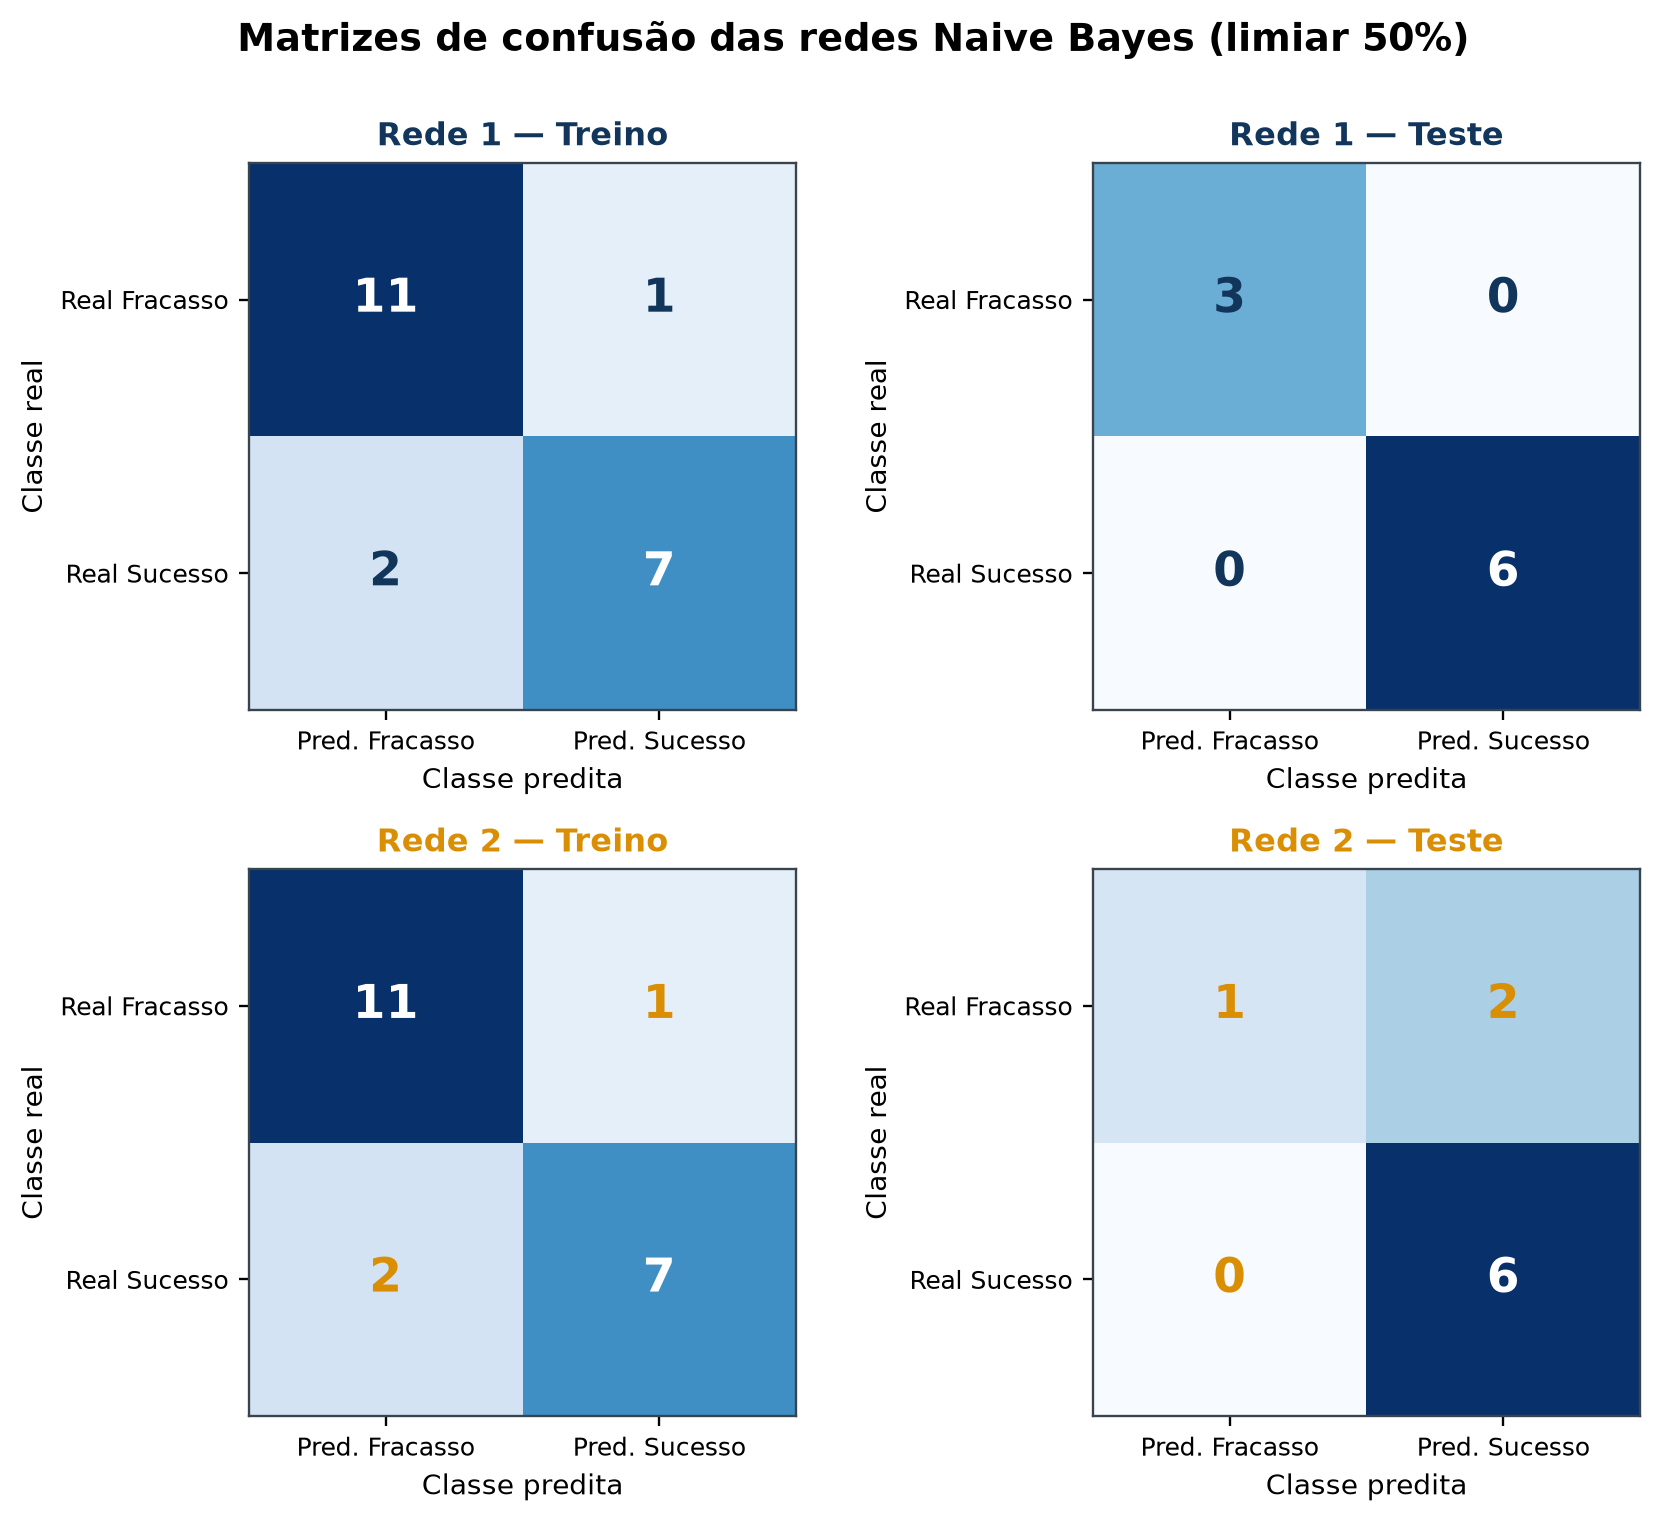

In [14]:
display(Markdown("**Figura 3 — matrizes de confusão das redes Naive Bayes (treino e teste).**"))
display(Image(filename=str(FIG / "fig03_matrizes_confusao_nb.png"), width=760))

In [15]:
metrics = pd.read_csv(TAB / "07_nb_metricas.csv")
show = metrics.copy()
for c in ["Acurácia","Sensibilidade","Especificidade","PPV","NPV","F1","Brier","Certeza média"]:
    show[c] = (show[c] * 100).round(1).astype(str) + "%"
show = show.rename(columns={"Certeza média":"Certeza média (max P)"})
display(show[["Modelo","Conjunto","Acurácia","Sensibilidade","Especificidade","PPV","NPV","F1","Brier","Certeza média (max P)","TN","FP","FN","TP"]])

,Modelo,Conjunto,Acurácia,Sensibilidade,Especificidade,PPV,NPV,F1,Brier,Certeza média (max P),TN,FP,FN,TP
0,Rede 1 (clínica),Treino,85.7%,77.8%,91.7%,87.5%,84.6%,82.4%,9.5%,86.8%,11,1,2,7
1,Rede 1 (clínica),Teste,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,3.8%,85.4%,3,0,0,6
2,Rede 1 (clínica),Completa,90.0%,86.7%,93.3%,92.9%,87.5%,89.7%,7.8%,86.4%,14,1,2,13
3,Rede 2 (Netica),Treino,85.7%,77.8%,91.7%,87.5%,84.6%,82.4%,12.8%,89.5%,11,1,2,7
4,Rede 2 (Netica),Teste,77.8%,100.0%,33.3%,75.0%,100.0%,85.7%,15.9%,93.1%,1,2,0,6
5,Rede 2 (Netica),Completa,83.3%,86.7%,80.0%,81.2%,85.7%,83.9%,13.7%,90.6%,12,3,2,13


**Leitura.** A Rede 1 tem 85,7% de acerto no treino e 100% no teste; na base completa, 90,0%. A Rede 2 tem o mesmo desempenho no treino (85,7%), mas cai para 77,8% no teste, com especificidade de apenas 33,3%: ela libera dois dos três pacientes que fracassariam. A certeza média da Rede 2 é maior (89,5% no treino; 93,1% no teste) — ou seja, ela é mais confiante e mais errada. Esse é um exemplo claro de má calibração.

**Figura 4 — métricas e calibração das redes Naive Bayes.**

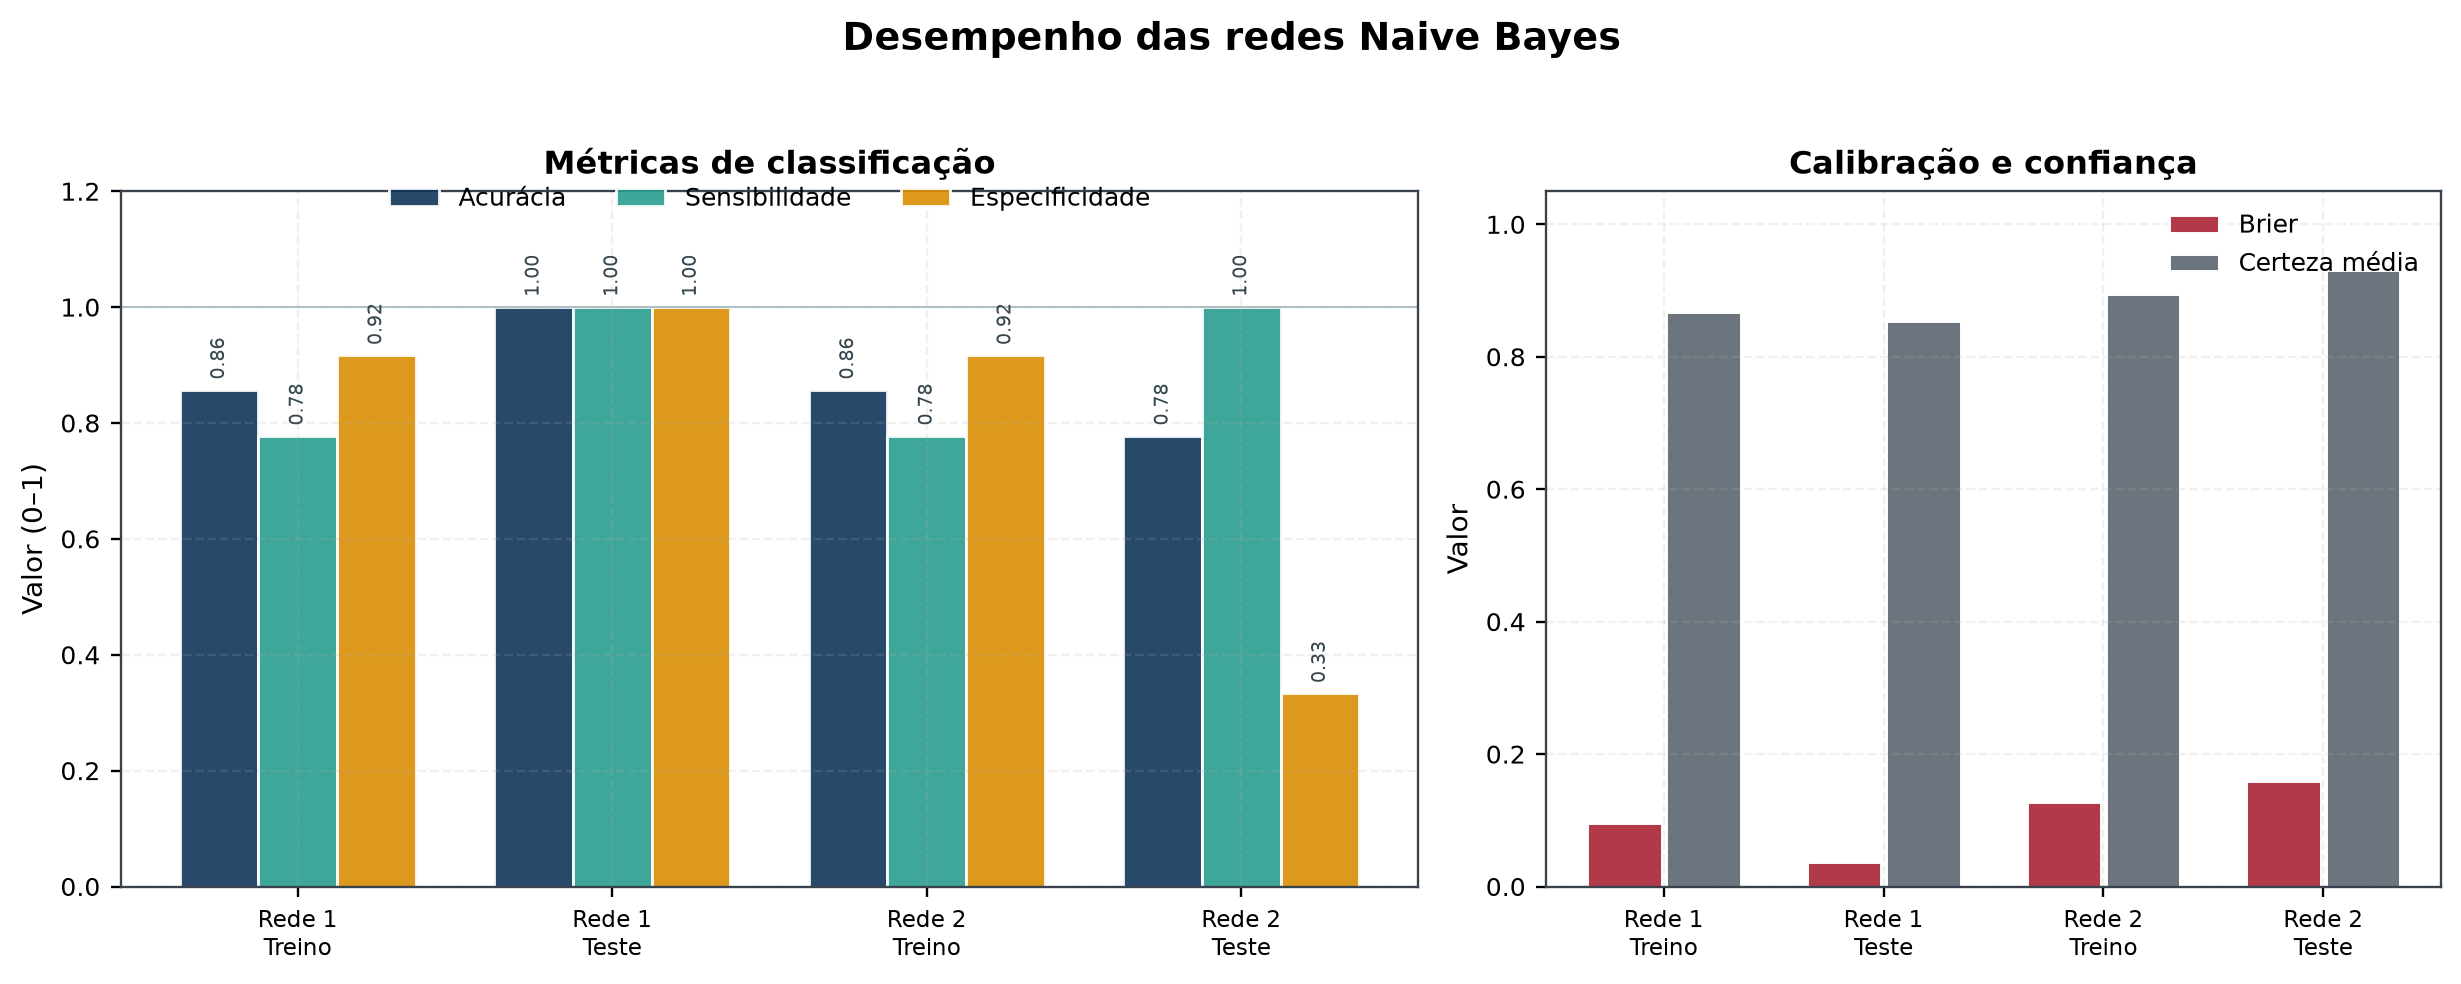

In [16]:
display(Markdown("**Figura 4 — métricas e calibração das redes Naive Bayes.**"))
display(Image(filename=str(FIG / "fig04_metricas_nb.png"), width=1050))

### 2.8 Limiar de decisão e assimetria de riscos

O limiar padrão de 50% maximiza a acurácia balanceada, mas não incorpora o custo assimétrico do erro. Liberar um paciente que fracassará (falso positivo) pode causar sofrimento, reintubação e aumento de mortalidade; atrasar a liberação (falso negativo) consome leito e aumenta exposição a infecções, mas é potencialmente reversível. Em uma política conservadora, pode-se exigir $P(\\text{Sucesso}) \\geq 60\\%$ ou $75\\%$ para liberar. A tabela de sensibilidade mostra o efeito no teste e na base completa.

In [17]:
th = pd.read_csv(TAB / "09_nb_limiares.csv")
th_show = th[th["Conjunto"] == "Completa"].copy()
for c in ["acuracia","sensibilidade","especificidade"]:
    th_show[c] = (th_show[c] * 100).round(1)
display(th_show[["Rede","Limiar","acuracia","sensibilidade","especificidade","fp","fn"]].rename(columns={"acuracia":"Acurácia (%)","sensibilidade":"Sensibilidade (%)","especificidade":"Especificidade (%)","fp":"FP","fn":"FN"}))

,Rede,Limiar,Acurácia (%),Sensibilidade (%),Especificidade (%),FP,FN
9,Rede 1 (clínica),0.500,90.000,86.700,93.300,1,2
10,Rede 1 (clínica),0.550,90.000,86.700,93.300,1,2
11,Rede 1 (clínica),0.600,90.000,86.700,93.300,1,2
12,Rede 1 (clínica),0.650,90.000,86.700,93.300,1,2
13,Rede 1 (clínica),0.700,90.000,86.700,93.300,1,2
14,Rede 1 (clínica),0.750,90.000,86.700,93.300,1,2
15,Rede 1 (clínica),0.800,86.700,80.000,93.300,1,3
16,Rede 1 (clínica),0.850,86.700,80.000,93.300,1,3
17,Rede 1 (clínica),0.900,70.000,46.700,93.300,1,8
27,Rede 2 (Netica),0.500,83.300,86.700,80.000,3,2


Para a Rede 1, o limiar conservador quase não altera os resultados, porque as posteriores são extremas (a maioria fica abaixo de 45% ou acima de 75%). Para a Rede 2, subir o limiar para 75% melhora a especificidade no teste, mas ao custo de falsos negativos. A escolha do limiar é, portanto, uma decisão de política clínica e não deve ser feita olhando apenas a acurácia.

### 2.9 Por que as redes convergem ou divergem?

- **Convergem** quando o paciente é inequívoco: NIF muito negativo, RR baixo, VT alto e RSBI baixo geram evidência forte em ambas as redes. Exemplos: TR15, TR17, TR20, TE7, TE9.
- **Divergem** nos casos de fronteira, em que a perda de resolução da Rede 2 muda a contagem de verossimilhança. TR4 (NIF −22, RR 30, VT 350, RSBI 86) recebe 44,2% na Rede 1 e 17,0% na Rede 2: ambas retêm, mas com confiança distinta. TR16 (NIF −30, RR 30, VT 250, RSBI 120) é mais dramático: 76,7% na Rede 1 (sucesso) contra 10,9% na Rede 2 (fracasso), com desfecho real de sucesso. TE1 (NIF −15, RR 25, VT 450, RSBI 56) vai de 29,7% (fracasso) na Rede 1 para 77,2% (sucesso) na Rede 2, e o desfecho real é fracasso.
- **TE3** é o caso mais didático: NIF −28 e RR 24 são limitrofes, VT 310 é baixo e RSBI 77 é favorável. A Rede 1 fica em 44,2% (fracasso), a Rede 2 em 90,6% (sucesso) e o sistema fuzzy em 52,3 (cautela). O desfecho real é fracasso. A Rede 2 erra por comprimir NIF, RR e VT em apenas duas faixas e multiplicar evidências favoráveis.

In [18]:
d = p1_full[["ID","Resultado","p_sucesso"]].rename(columns={"p_sucesso":"Rede 1"}).merge(
    p2_full[["ID","p_sucesso"]].rename(columns={"p_sucesso":"Rede 2"}), on="ID")
d["Δ"] = (d["Rede 1"] - d["Rede 2"]).abs()
display(d.sort_values("Δ", ascending=False).head(12).round(3))

,ID,Resultado,Rede 1,Rede 2,Δ
15,TR16,Sucesso,0.767,0.109,0.658
21,TE1,Fracasso,0.297,0.772,0.475
23,TE3,Fracasso,0.442,0.906,0.464
3,TR4,Fracasso,0.442,0.170,0.272
10,TR11,Fracasso,0.442,0.170,0.272
13,TR14,Sucesso,0.442,0.232,0.210
11,TR12,Fracasso,0.048,0.222,0.174
12,TR13,Sucesso,0.442,0.592,0.150
2,TR3,Fracasso,0.026,0.170,0.144
1,TR2,Fracasso,0.010,0.109,0.099


**Figura 5 — casos em que as redes mais divergem.**

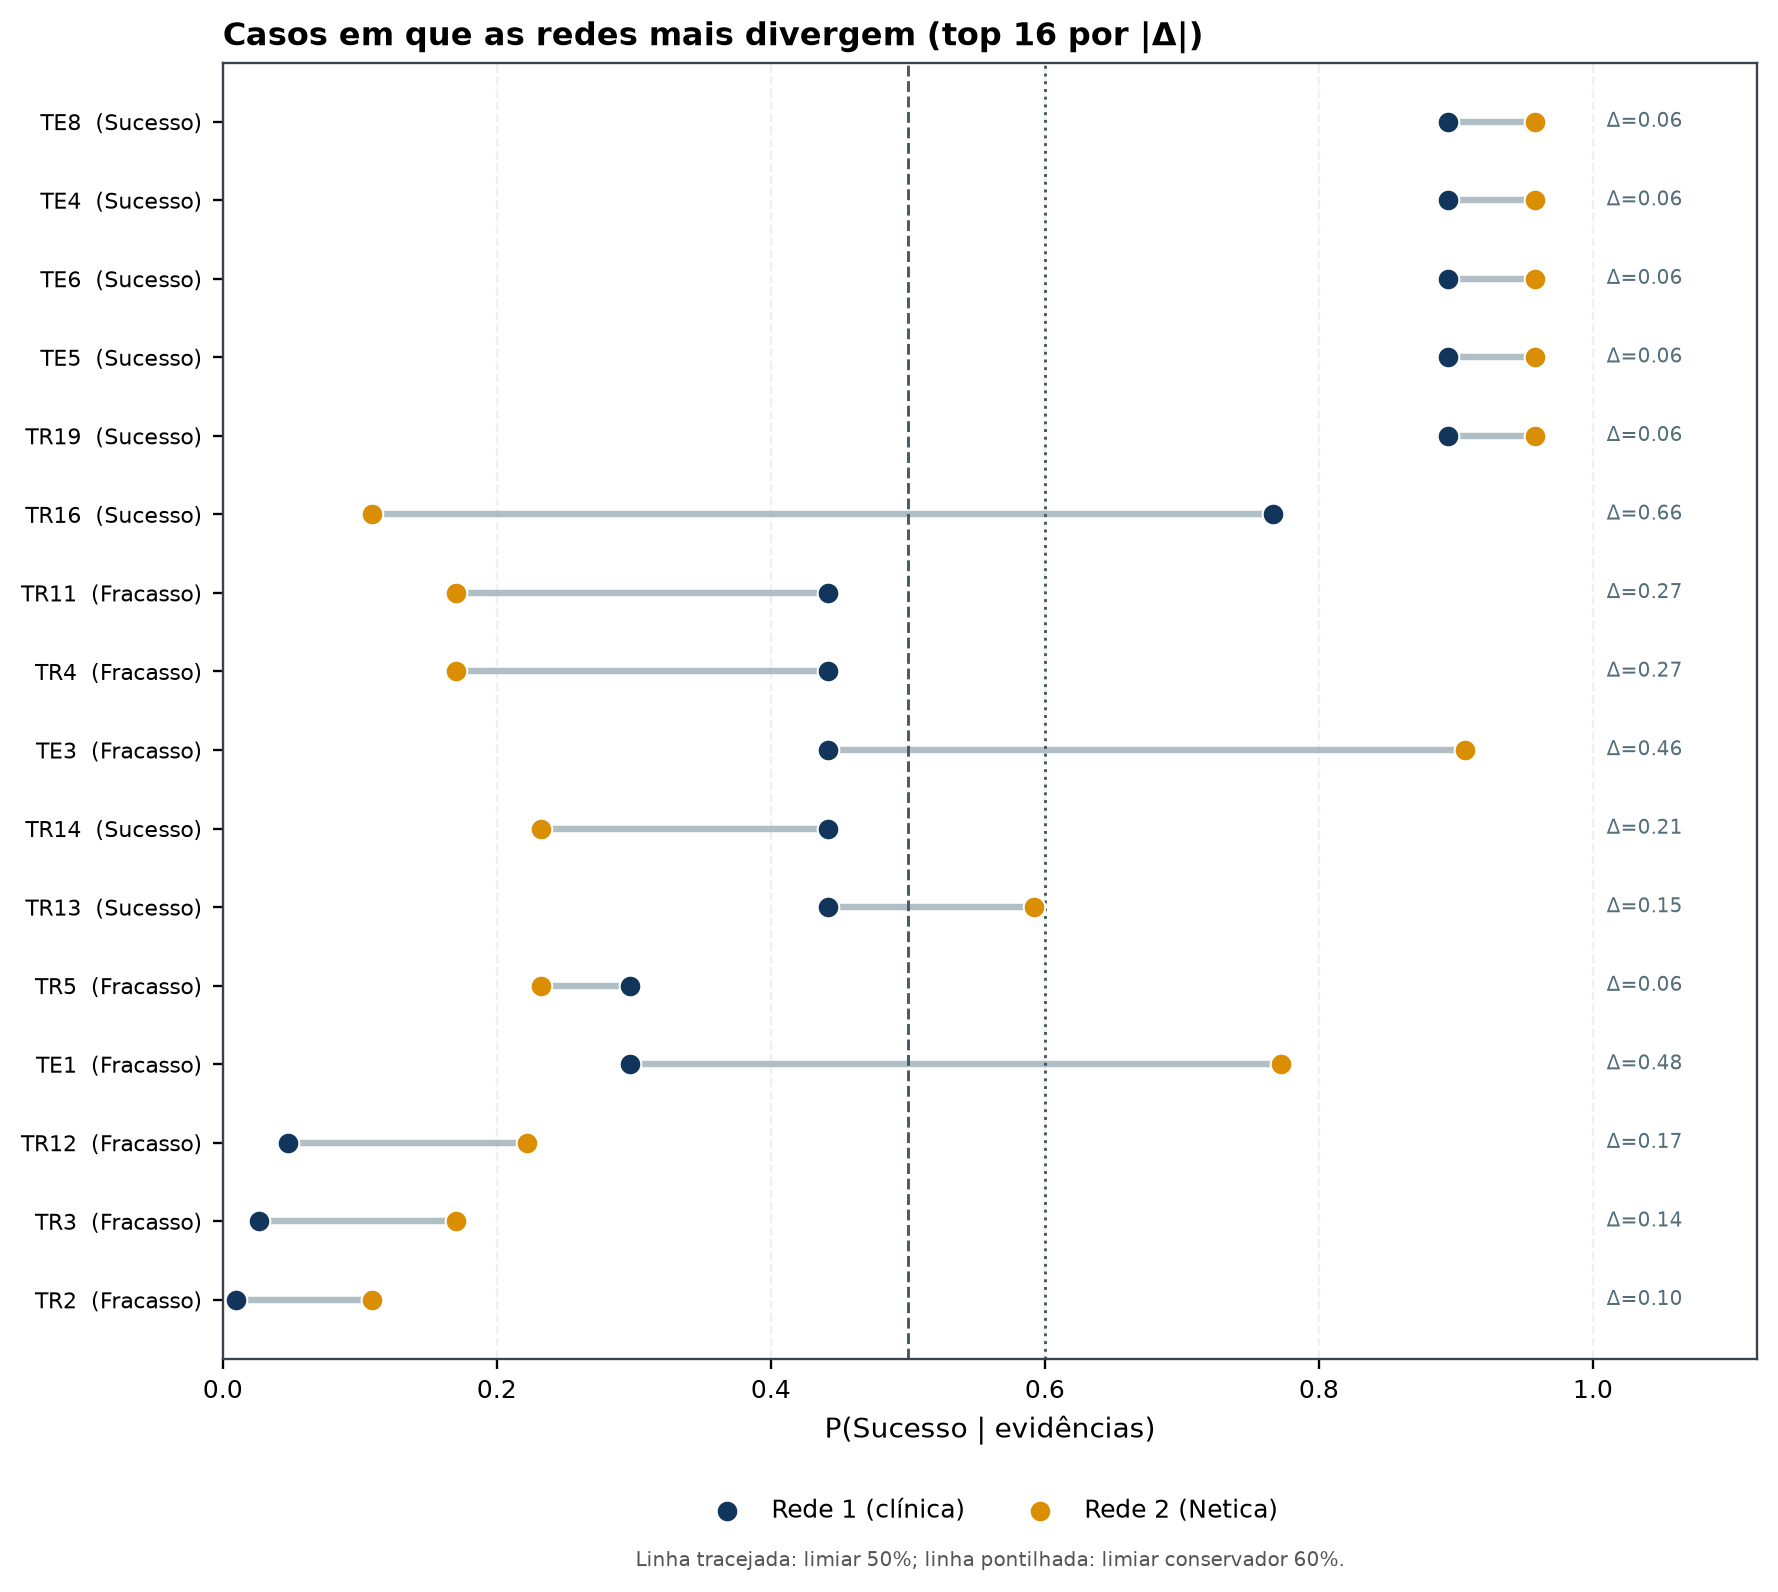

In [19]:
display(Markdown("**Figura 5 — casos em que as redes mais divergem.**"))
display(Image(filename=str(FIG / "fig05_divergencia_probabilidades.png"), width=760))

### 2.10 Robustez e redundância: validação leave-one-out no treino

A validação leave-one-out refaz priors e CPTs em cada dobra, mantendo a discretização fixa. Ela não substitui o teste externo, mas mostra a estabilidade interna.

In [20]:
loo = pd.read_csv(TAB / "10_loo_variaveis.csv")
for c in ["Acurácia LOO","Sensibilidade LOO","Especificidade LOO"]:
    loo[c] = (loo[c] * 100).round(1)
display(loo.rename(columns={"Acurácia LOO":"Acurácia (%)","Sensibilidade LOO":"Sensibilidade (%)","Especificidade LOO":"Especificidade (%)"}))

,Rede,Variáveis,Acurácia (%),Sensibilidade (%),Especificidade (%)
0,Rede 1 (clínica),NIF + RR + VT + RSBI,76.200,77.800,75.000
1,Rede 1 (clínica),NIF + RR + VT,85.700,77.800,91.700
2,Rede 1 (clínica),NIF + RSBI,85.700,77.800,91.700
3,Rede 1 (clínica),NIF,85.700,77.800,91.700
4,Rede 2 (Netica),NIF + RR + VT + RSBI,81.000,66.700,91.700
5,Rede 2 (Netica),NIF + RR + VT,71.400,66.700,75.000
6,Rede 2 (Netica),NIF + RSBI,71.400,66.700,75.000
7,Rede 2 (Netica),NIF,76.200,77.800,75.000


O conjunto completo tem 76,2% de acurácia LOO na Rede 1, contra 85,7% para NIF+RR+VT e para NIF isolado. Isso não prova que “NIF sozinho é melhor”; prova que, com 21 casos, as quatro variáveis produzem muitas células de CPT e a redundância aumenta a variância. A Rede 1 mantém as quatro variáveis por fidelidade ao escopo e porque o desempenho no teste foi excelente, mas a análise é um alerta contra concluir que “mais variáveis sempre melhora”.

## 3. Sistema de inferência fuzzy Mamdani

### 3.1 Arquitetura e operadores

O FIS tem quatro entradas e uma saída `Potencial_Desmame` (0–100). O método é Mamdani, com:

| Etapa | Operador adotado | Implementação |
|---|---|---|
| Conectivo E | mínimo (`min`) | `μ_A(x) ∧ μ_B(x) = min(μ_A, μ_B)` |
| Conectivo OU | máximo (`max`) | não utilizado nas regras (todas conjuntivas) |
| Implicação | mínimo (`min`) | corte do consequente em α |
| Agregação | máximo (`max`) | união das regiões recortadas |
| Defuzzificação | centroide (COA) | $y^* = \\int y\\,\\mu_{agg}(y)dy / \\int \\mu_{agg}(y)dy$ |

A implementação manual foi validada contra `scikit-fuzzy` (diferença máxima inferior a 10⁻⁵ no centroide).

### 3.2 Universos, termos linguísticos e funções de pertinência

As funções trapezoidais nas extremidades representam saturação fisiológica; as triangulares no centro representam zonas de transição. Os parâmetros foram definidos a priori, com base na literatura, e não ajustados aos 30 casos.

,Variável,Termo,Tipo,"Parâmetros [a,b,c(,d)]",Universo
0,NIF,Fraco,Trapezoidal,"-25, -15, 0, 0","[-60, 0]"
1,NIF,Limítrofe,Triangular,"-35, -25, -15","[-60, 0]"
2,NIF,Forte,Trapezoidal,"-60, -60, -35, -25","[-60, 0]"
3,RR,Adequada,Trapezoidal,"5, 5, 22, 30","[5, 60]"
4,RR,Limítrofe,Triangular,"22, 30, 38","[5, 60]"
5,RR,Elevada,Trapezoidal,"30, 38, 60, 60","[5, 60]"
6,VT,Baixo,Trapezoidal,"100, 100, 300, 400","[100, 1000]"
7,VT,Adequado,Triangular,"300, 475, 650","[100, 1000]"
8,VT,Elevado,Trapezoidal,"600, 750, 1000, 1000","[100, 1000]"
9,RSBI,Favorável,Trapezoidal,"0, 0, 90, 120","[0, 300]"


**Figura 7 — funções de pertinência de entrada e saída.**

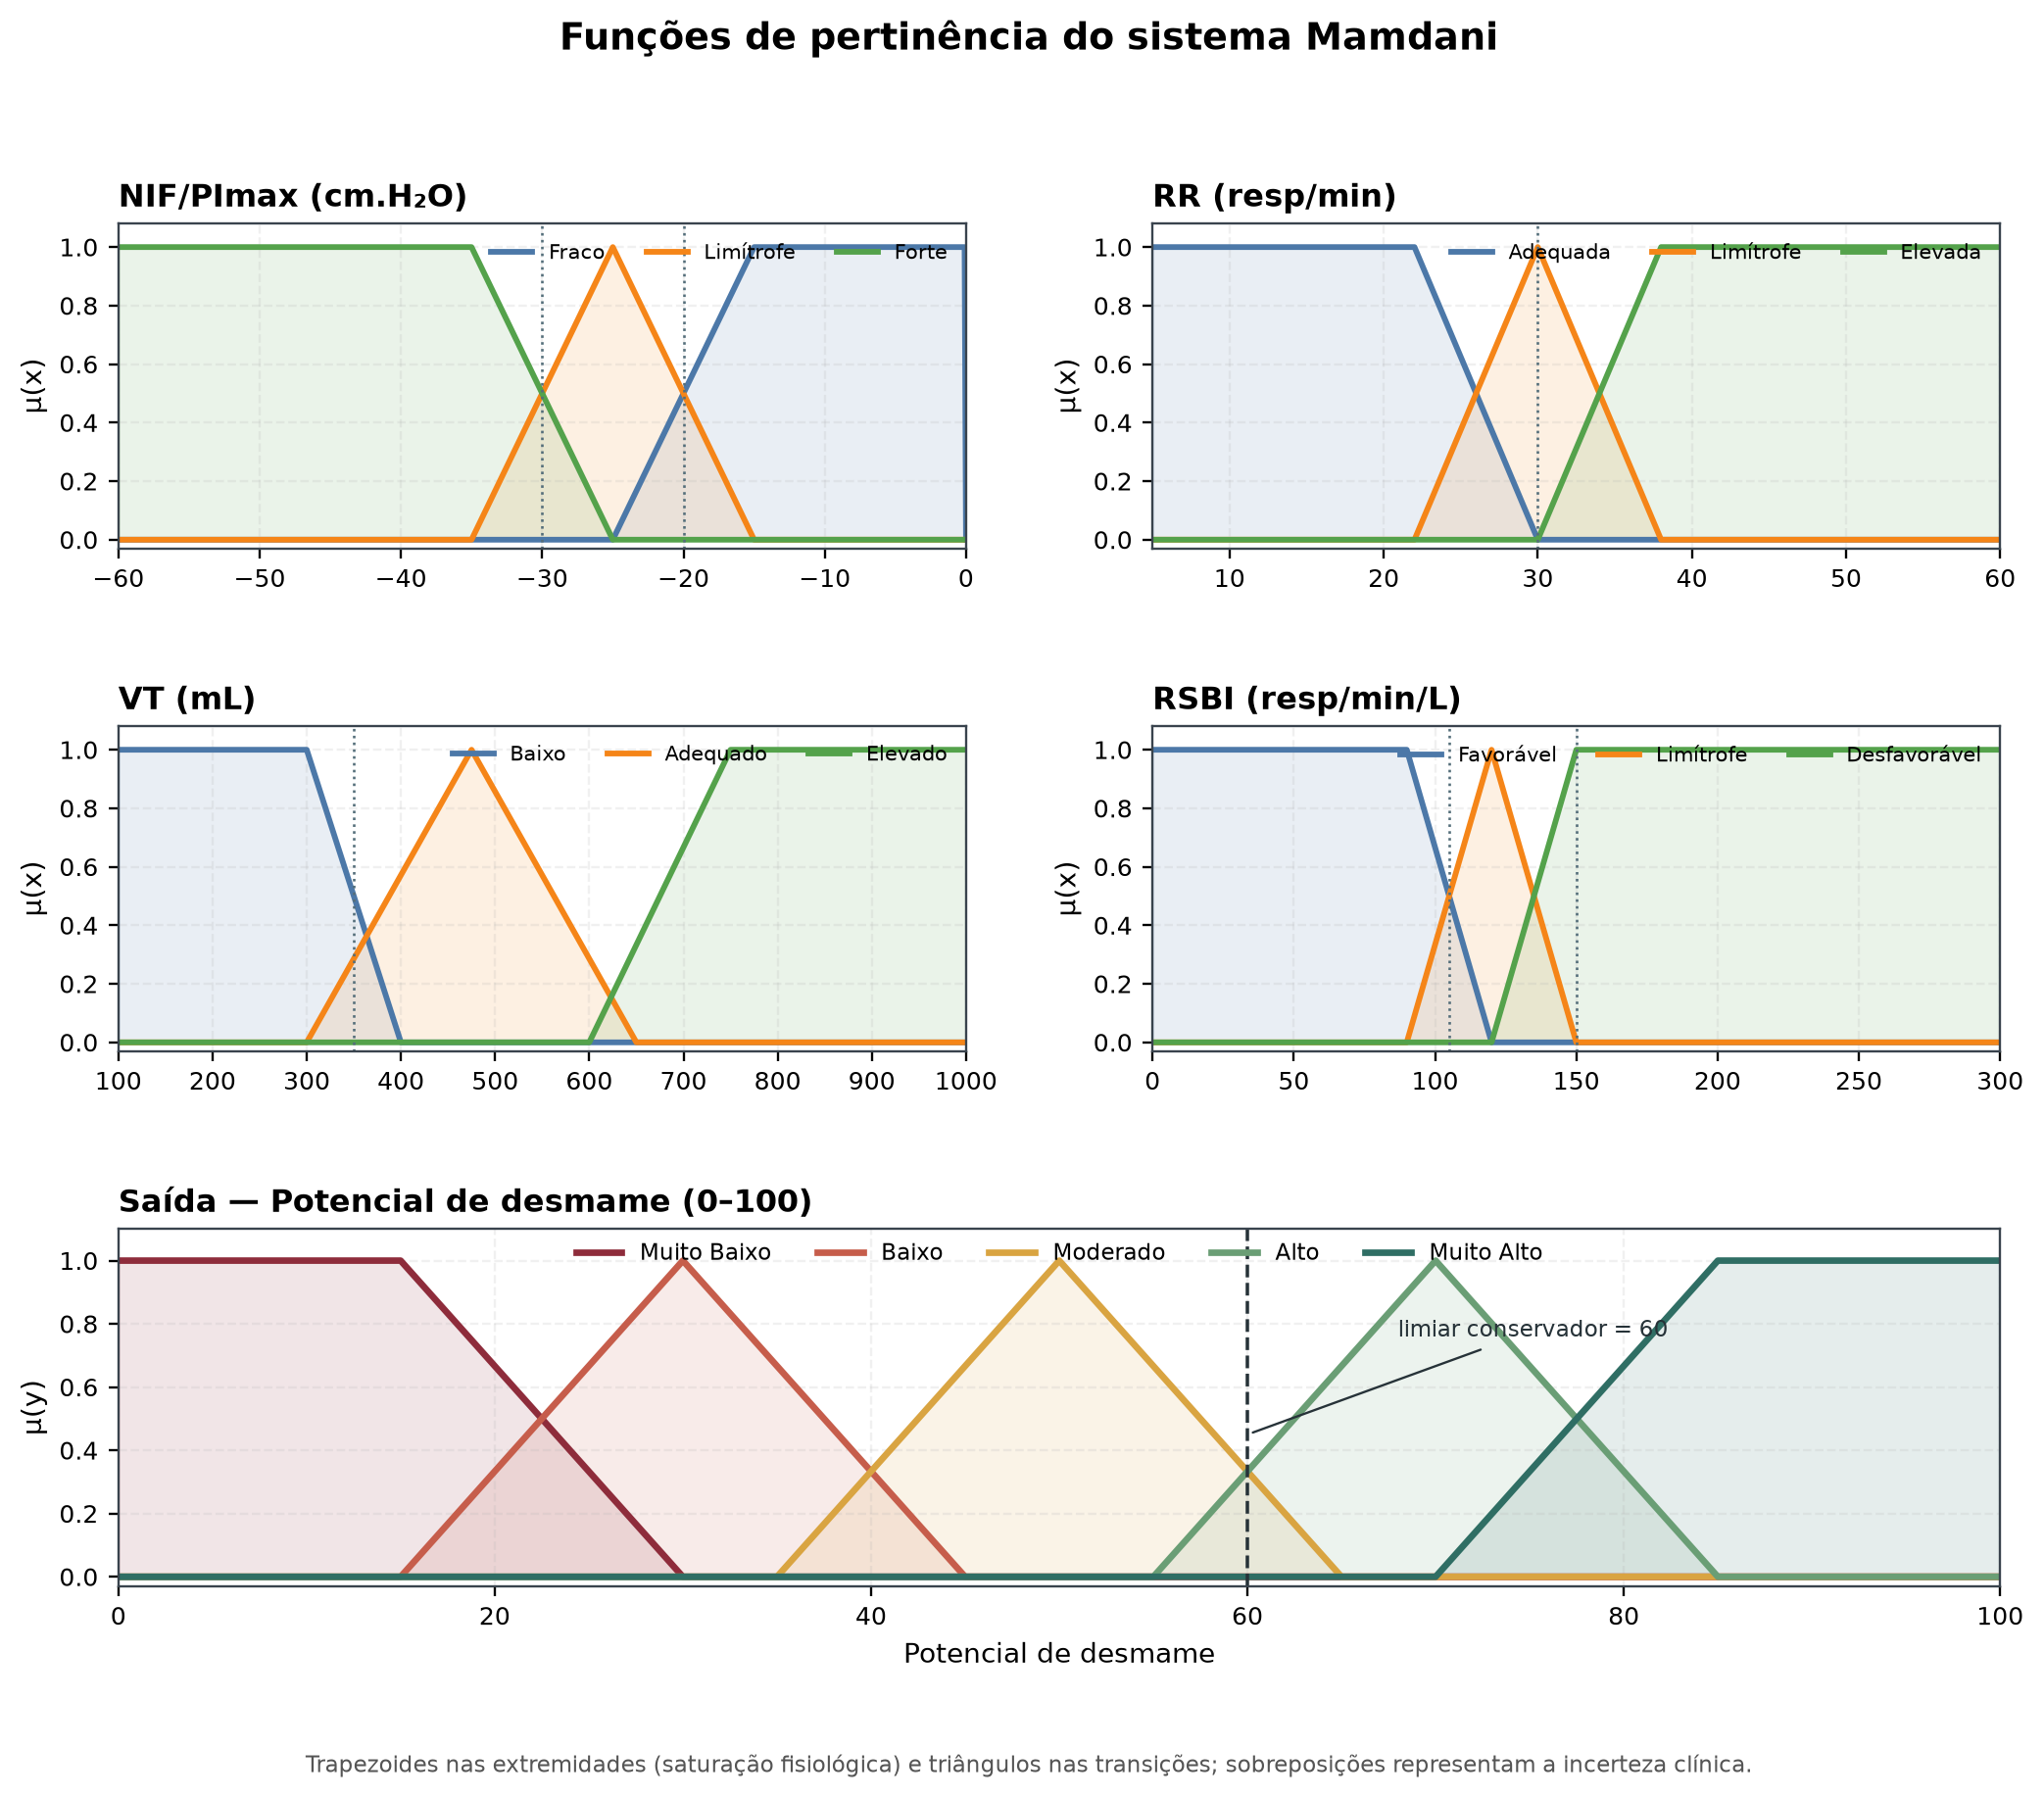

In [21]:
mfs = pd.read_csv(TAB / "11_fuzzy_mfs.csv")
display(mfs)
display(Markdown("**Figura 7 — funções de pertinência de entrada e saída.**"))
display(Image(filename=str(FIG / "fig07_funcoes_pertinencia.png"), width=1050))

**Como as sobreposições capturam a incerteza.** O NIF tem 50% de pertinência a “Forte” e 50% a “Limítrofe” em −30 cm.H₂O, exatamente o limiar clássico; em −25, é totalmente limítrofe. O RSBI tem 50% em 105 (favorável vs. limítrofe) e 50% em 135 (limítrofe vs. desfavorável), criando uma faixa de cautela entre 105 e 150. A RR tem 50% em 26 (adequada vs. limítrofe) e 34 (limítrofe vs. elevada), em vez de um salto em 30. O VT tem transição entre 300 e 400 mL, capturando a diferença entre “baixo” e “adequado” na região de 5 mL/kg.

### 3.3 Base de regras

A base é completa: todas as $3^4=81$ combinações de termos antecedentes têm exatamente uma regra. A pontuação soma pesos clínicos:

- NIF: Forte +2, Limítrofe 0, Fraco −2
- RR: Adequada +2, Limítrofe 0, Elevada −2
- VT: Adequado +1, Baixo −1, Elevado 0
- RSBI: Favorável +2, Limítrofe 0, Desfavorável −2

A pontuação é convertida em: ≥6 Muito Alto; 4–5 Alto; 2–3 Moderado; −2 a 1 Baixo; ≤−3 Muito Baixo. A Tabela abaixo lista as 81 regras no formato SE…ENTÃO. A base é consistente porque cada combinação de antecedentes tem um único consequente.

In [22]:
rules = pd.read_csv(TAB / "12_fuzzy_regras.csv")
print(f"Total de regras: {len(rules)}")
display(rules[["Regra","NIF","RR","VT","RSBI","Consequente"]])
display(Markdown("**Base completa no formato SE…ENTÃO:**"))
display(rules[["Regra","SE...ENTÃO"]])

Total de regras: 81


,Regra,NIF,RR,VT,RSBI,Consequente
0,1,Fraco,Adequada,Baixo,Favorável,Baixo
1,2,Fraco,Adequada,Baixo,Limítrofe,Baixo
2,3,Fraco,Adequada,Baixo,Desfavorável,Muito Baixo
3,4,Fraco,Adequada,Adequado,Favorável,Moderado
4,5,Fraco,Adequada,Adequado,Limítrofe,Baixo
...,...,...,...,...,...,...
76,77,Forte,Elevada,Adequado,Limítrofe,Baixo
77,78,Forte,Elevada,Adequado,Desfavorável,Baixo
78,79,Forte,Elevada,Elevado,Favorável,Moderado
79,80,Forte,Elevada,Elevado,Limítrofe,Baixo


**Base completa no formato SE…ENTÃO:**

,Regra,SE...ENTÃO
0,1,SE NIF é Fraco E RR é Adequada E VT é Baixo E ...
1,2,SE NIF é Fraco E RR é Adequada E VT é Baixo E ...
2,3,SE NIF é Fraco E RR é Adequada E VT é Baixo E ...
3,4,SE NIF é Fraco E RR é Adequada E VT é Adequado...
4,5,SE NIF é Fraco E RR é Adequada E VT é Adequado...
...,...,...
76,77,SE NIF é Forte E RR é Elevada E VT é Adequado ...
77,78,SE NIF é Forte E RR é Elevada E VT é Adequado ...
78,79,SE NIF é Forte E RR é Elevada E VT é Elevado E...
79,80,SE NIF é Forte E RR é Elevada E VT é Elevado E...


**Figura 8 — distribuição dos consequentes e geometria da base de regras.** O painel esquerdo mostra que a base é deliberadamente conservadora: 39 regras concluem “Baixo”, 18 “Muito Baixo”, 15 “Moderado”, 7 “Alto” e apenas 2 “Muito Alto”. O painel direito fixa VT adequado e RSBI favorável e mostra que a pontuação cresce de forma monótona quando o NIF passa de fraco para forte e a RR de elevada para adequada. Essa monotonicidade é uma checagem visual de consistência clínica.

**Figura 8 — consequentes das 81 regras e pontuação NIF × RR.**

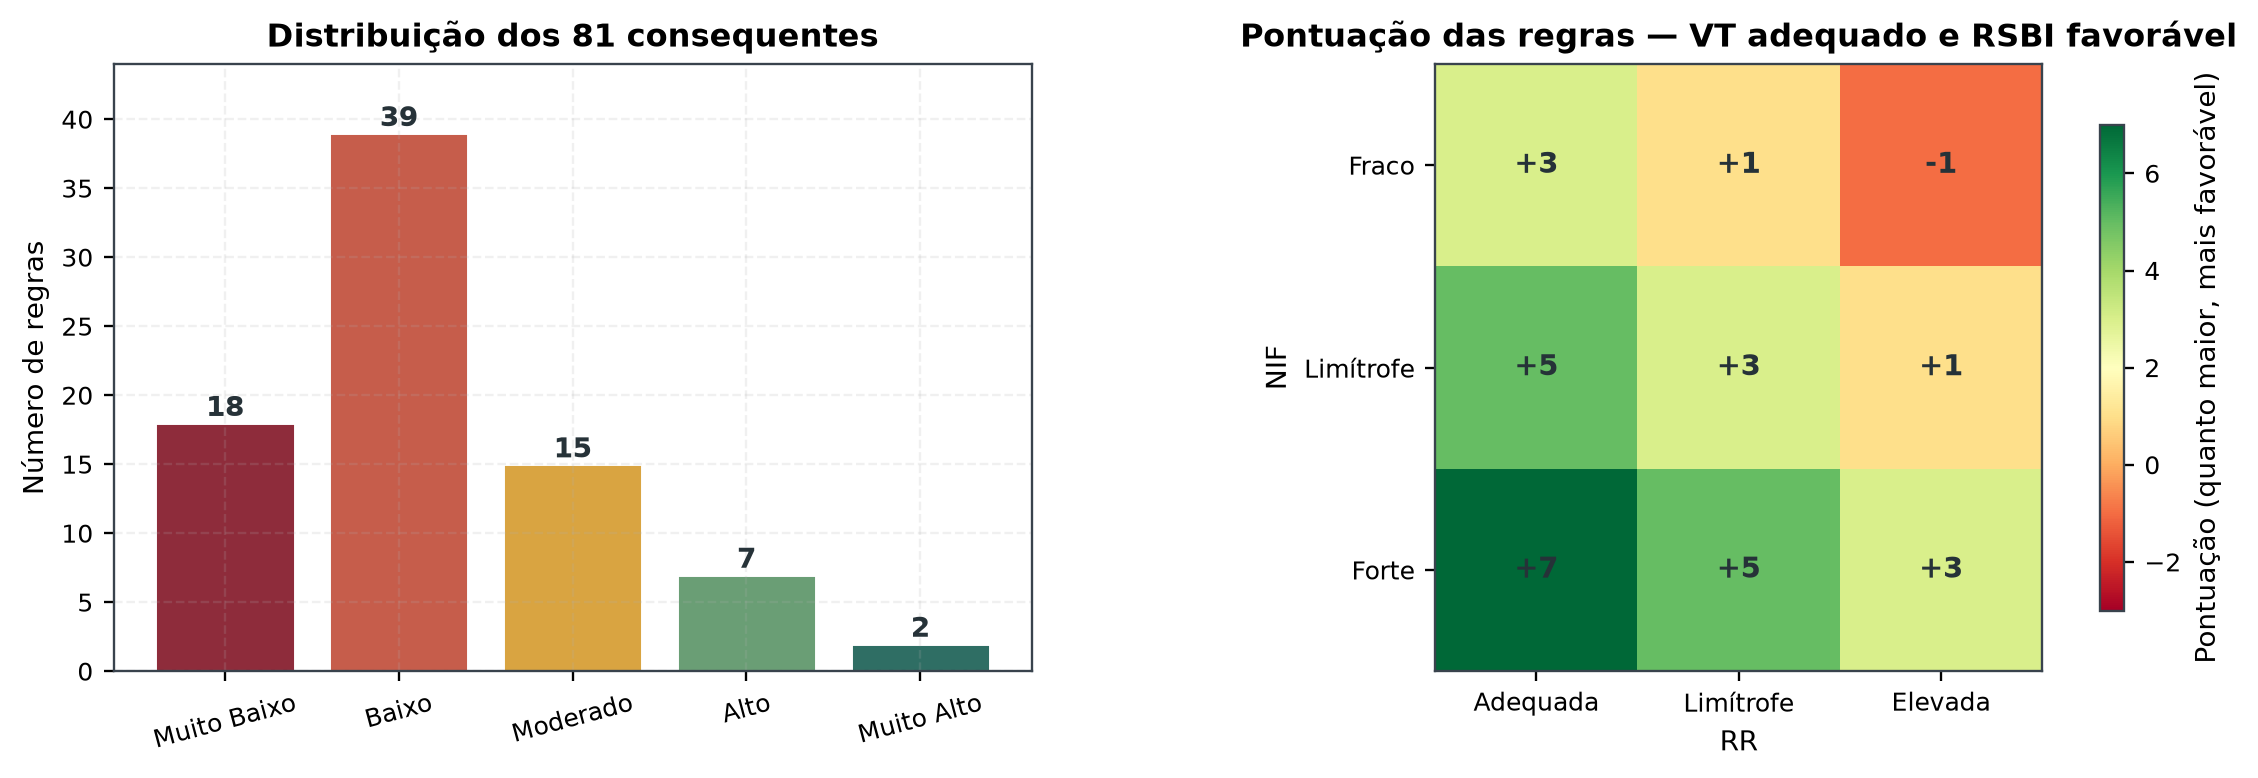

In [23]:
display(Markdown("**Figura 8 — consequentes das 81 regras e pontuação NIF × RR.**"))
display(Image(filename=str(FIG / "fig08_regras_consequentes.png"), width=1050))

### 3.4 Completude e consistência

A verificação abaixo percorre uma malha densa de cada universo e confirma que existe pelo menos um termo com pertinência positiva em cada ponto. Como todas as 81 combinações estão presentes na base, qualquer ponto do espaço de entrada ativa ao menos uma regra.

In [24]:
# Cobertura dos universos: para cada variável, max_t mu_t(x) > 0 em toda a malha
for var in w.VARIABLES:
    # Usa a biblioteca de plotting para obter as MFs na malha do universo.
    mus = np.vstack([plotting._mf_array(var, t) for t in w.FUZZY_TERMS[var]])
    mx = mus.max(axis=0)
    print(f"{var}: mínimo da cobertura máxima = {mx.min():.3f}; pontos sem cobertura = {(mx <= 1e-12).sum()}")

# Amostra de 2.000 pontos: nenhuma saída ausente/NaN
rng = np.random.default_rng(42)
for _ in range(2000):
    x = {
        "NIF": rng.uniform(-60, -0.1),
        "RR": rng.uniform(5, 60),
        "VT": rng.uniform(100, 1000),
        "RSBI": rng.uniform(0, 300),
    }
    val = w.mamdani_evaluate(x).centroid
    assert np.isfinite(val)
print("2.000 avaliações aleatórias: todas com regra ativada e saída finita.")

NIF: mínimo da cobertura máxima = 0.000; pontos sem cobertura = 1
RR: mínimo da cobertura máxima = 0.500; pontos sem cobertura = 0
VT: mínimo da cobertura máxima = 0.154; pontos sem cobertura = 0
RSBI: mínimo da cobertura máxima = 0.500; pontos sem cobertura = 0


2.000 avaliações aleatórias: todas com regra ativada e saída finita.


### 3.5 Avaliação na base completa (30 casos)

O limiar operacional adotado é **60/100**: só há recomendação de liberação com potencial ≥ 60. A faixa 40–60 é explicitamente uma zona de cautela (não liberar, reavaliar). O limiar 50 é mantido como referência didática para comparação.

In [25]:
fuzzy = w.predict_fuzzy(full)
show = fuzzy[["ID","NIF","RR","VT","RSBI","Resultado","crisp","decisao","acerto_conservador"]].copy()
show["crisp"] = show["crisp"].round(2)
show["Resultado"] = show["Resultado"].map({"Fracasso":"F", "Sucesso":"S"})
show["decisao"] = show["decisao"].map({"Fracasso":"Fracasso", "Cautela":"Cautela", "Sucesso":"Sucesso"})
show["acerto_conservador"] = show["acerto_conservador"].map({True:"✓", False:"✗"})
display(show.rename(columns={"crisp":"Potencial (crisp)","decisao":"Decisão sugerida","acerto_conservador":"Acerto conservador"}))

,ID,NIF,RR,VT,RSBI,Resultado,Potencial (crisp),Decisão sugerida,Acerto conservador
0,TR1,-30,17,500,34,F,79.320,Sucesso,✗
1,TR2,-26,44,265,166,F,11.950,Fracasso,✓
2,TR3,-18,32,370,86,F,32.300,Fracasso,✓
3,TR4,-22,30,350,86,F,37.700,Fracasso,✓
4,TR5,-10,29,320,91,F,32.550,Fracasso,✓
5,TR6,-20,46,225,204,F,13.210,Fracasso,✓
6,TR7,-24,38,276,138,F,12.880,Fracasso,✓
7,TR8,-15,40,270,148,F,11.860,Fracasso,✓
8,TR9,-12,32,220,145,F,12.400,Fracasso,✓
9,TR10,-20,33,124,266,F,13.210,Fracasso,✓


**Figura 11 — potencial de desmame nos 30 casos.** O eixo vertical é o centroide defuzzificado; as cores indicam o desfecho real. A linha tracejada em 60 é o limiar conservador adotado e a pontilhada em 40 marca o início da faixa de cautela. O gráfico permite ver, de imediato, que a maioria dos sucessos fica acima de 70 e a maioria dos fracassos abaixo de 40; as exceções são os casos de fronteira discutidos no texto.

**Figura 11 — saída Fuzzy nos 30 casos, com os limiares 40 e 60.**

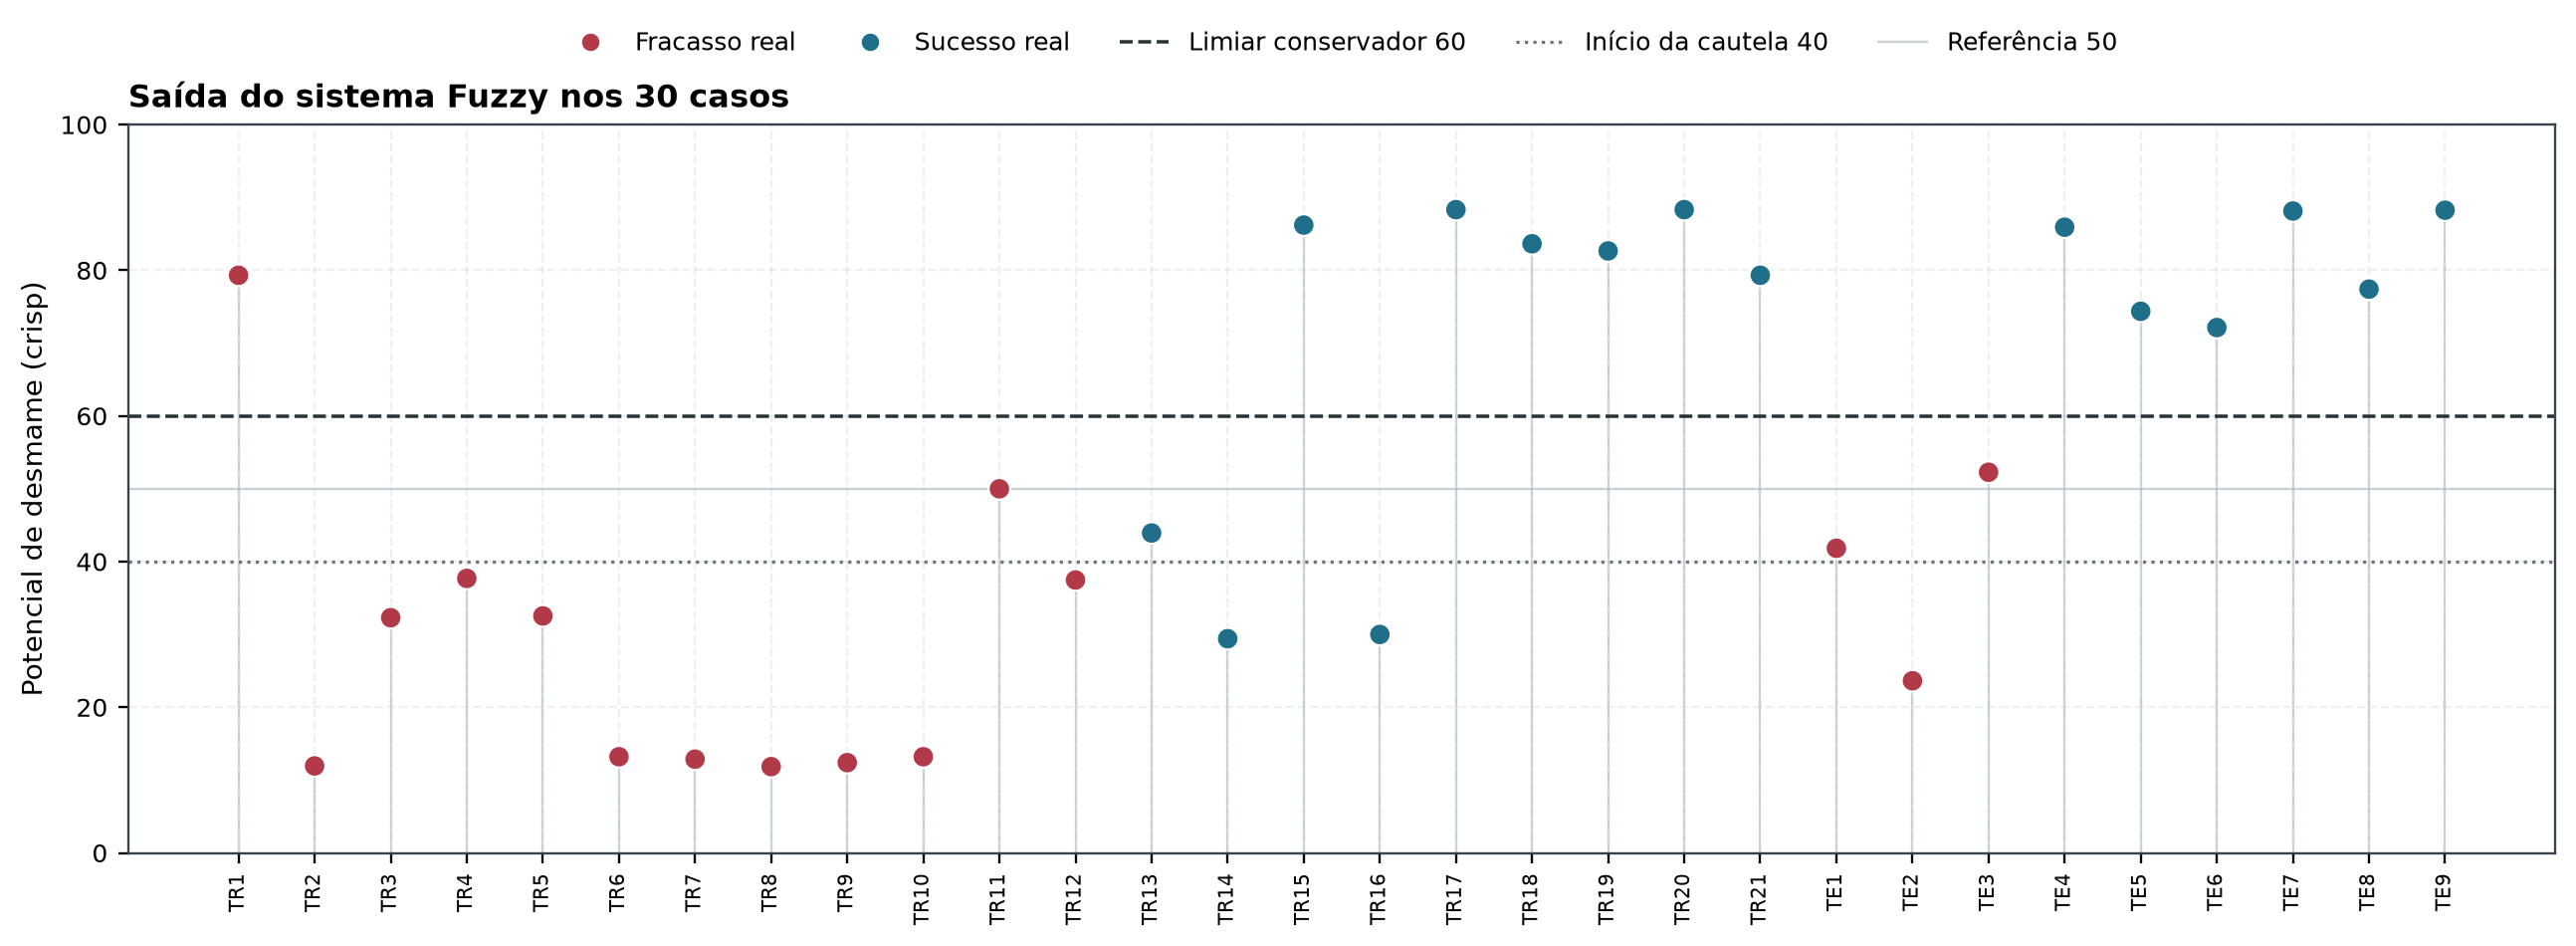

In [26]:
display(Markdown("**Figura 11 — saída Fuzzy nos 30 casos, com os limiares 40 e 60.**"))
display(Image(filename=str(FIG / "fig11_fuzzy_30casos.png"), width=1050))

**Figura 12 — matrizes de confusão do Fuzzy.** A matriz da esquerda usa o limiar 50 e a da direita o limiar conservador 60. A diferença entre elas é exatamente o caso TE3: com 50, ele seria liberado (falso positivo); com 60, permanece em cautela e é corretamente retido.

**Figura 12 — matrizes de confusão do sistema Fuzzy (limiares 50 e 60).**

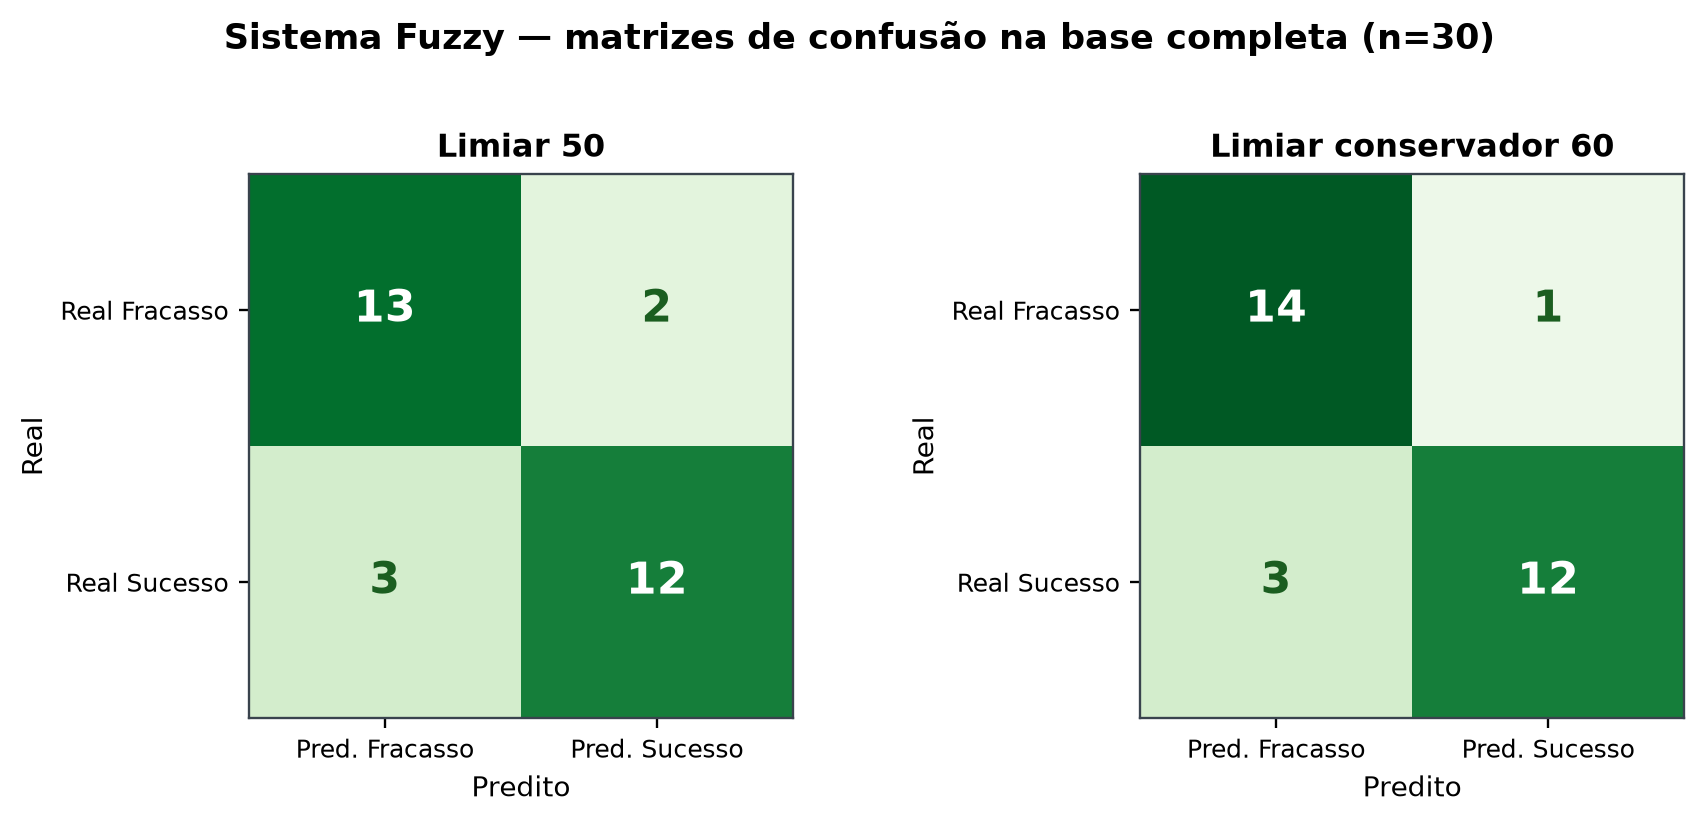

In [27]:
display(Markdown("**Figura 12 — matrizes de confusão do sistema Fuzzy (limiares 50 e 60).**"))
display(Image(filename=str(FIG / "fig12_fuzzy_confusao.png"), width=720))

In [28]:
fm = pd.read_csv(TAB / "14_fuzzy_metricas.csv")
show = fm.copy()
for c in ["acuracia","sensibilidade","especificidade","ppv","npv","f1"]:
    show[c] = (show[c] * 100).round(1)
display(show[["Conjunto","Limiar","acuracia","sensibilidade","especificidade","ppv","npv","f1","tn","fp","fn","tp"]].rename(columns={
    "acuracia":"Acurácia (%)","sensibilidade":"Sensibilidade (%)","especificidade":"Especificidade (%)",
    "ppv":"PPV (%)","npv":"NPV (%)","f1":"F1 (%)","tn":"TN","fp":"FP","fn":"FN","tp":"TP"}))

,Conjunto,Limiar,Acurácia (%),Sensibilidade (%),Especificidade (%),PPV (%),NPV (%),F1 (%),TN,FP,FN,TP
0,Treino,60,81.000,66.700,91.700,85.700,78.600,75.000,11,1,3,6
1,Treino,50,81.000,66.700,91.700,85.700,78.600,75.000,11,1,3,6
2,Teste,60,100.000,100.000,100.000,100.000,100.000,100.000,3,0,0,6
3,Teste,50,88.900,100.000,66.700,85.700,100.000,92.300,2,1,0,6
4,Completa,60,86.700,80.000,93.300,92.300,82.400,85.700,14,1,3,12
5,Completa,50,83.300,80.000,86.700,85.700,81.200,82.800,13,2,3,12


**Resultado.** Com limiar 60, o FIS acerta 17/21 no treino, 9/9 no teste e 26/30 na base completa. A sensibilidade é 80,0% e a especificidade 93,3%; há apenas um falso positivo (TR1) e três falsos negativos (TR13, TR14 e TR16). O falso positivo é o caso paradoxal em que todos os indicadores são favoráveis, mas o desfecho real foi fracasso. Os falsos negativos são pacientes com VT baixo e parâmetros limitrofes, mantidos em cautela — coerente com a política conservadora.

### 3.6 Superfícies de decisão

As superfícies mostram como o potencial varia com dois pares de variáveis, mantendo as demais fixas. As linhas escuras marcam 40 e 60.

**Figura 9 — superfície NIF × RR.** Com VT e RSBI fixos em valores adequados, o potencial cresce quando o NIF se torna mais negativo e a RR diminui. As linhas de nível 40 e 60 mostram que a fronteira de decisão não é uma reta: há uma região de transição em que os dois fatores se compensam.

**Figura 9 — superfície de decisão em função de NIF e RR.**

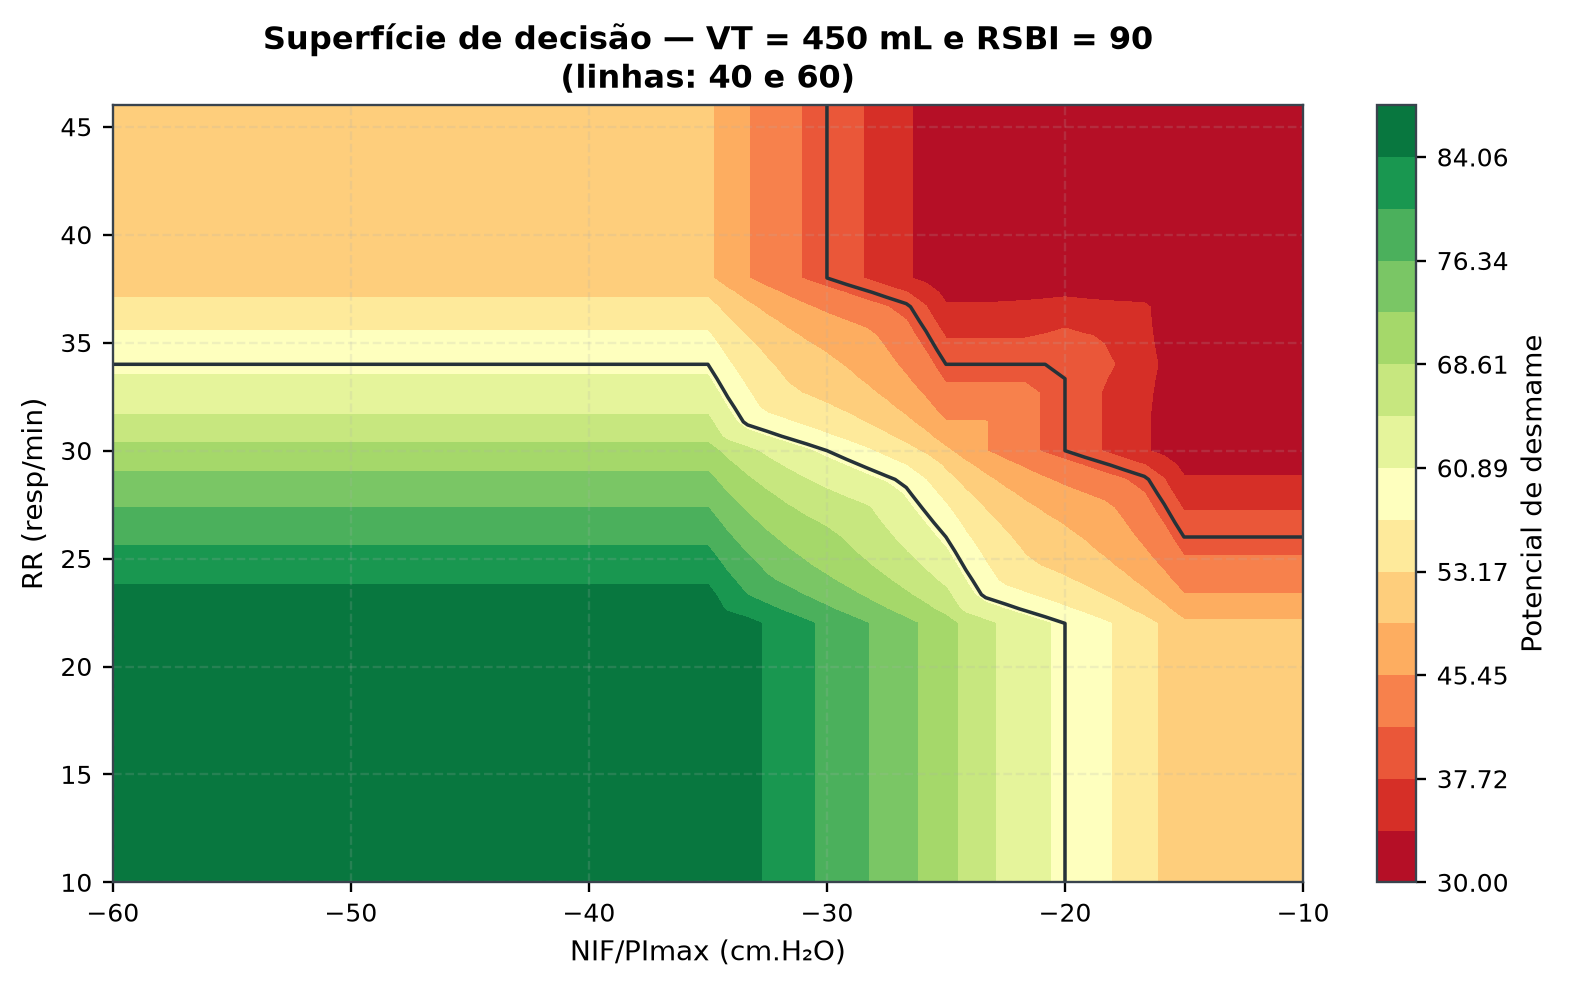

In [29]:
display(Markdown("**Figura 9 — superfície de decisão em função de NIF e RR.**"))
display(Image(filename=str(FIG / "fig09_superficie_nif_rr.png"), width=720))

**Figura 10 — superfície VT × RSBI.** Com NIF e RR fixos, volumes muito baixos derrubam o potencial mesmo quando o RSBI parece favorável; volumes altos e RSBI baixo se combinam na região de maior potencial. A interação visualiza por que o VT não é redundante com o RSBI na prática.

**Figura 10 — superfície de decisão em função de VT e RSBI.**

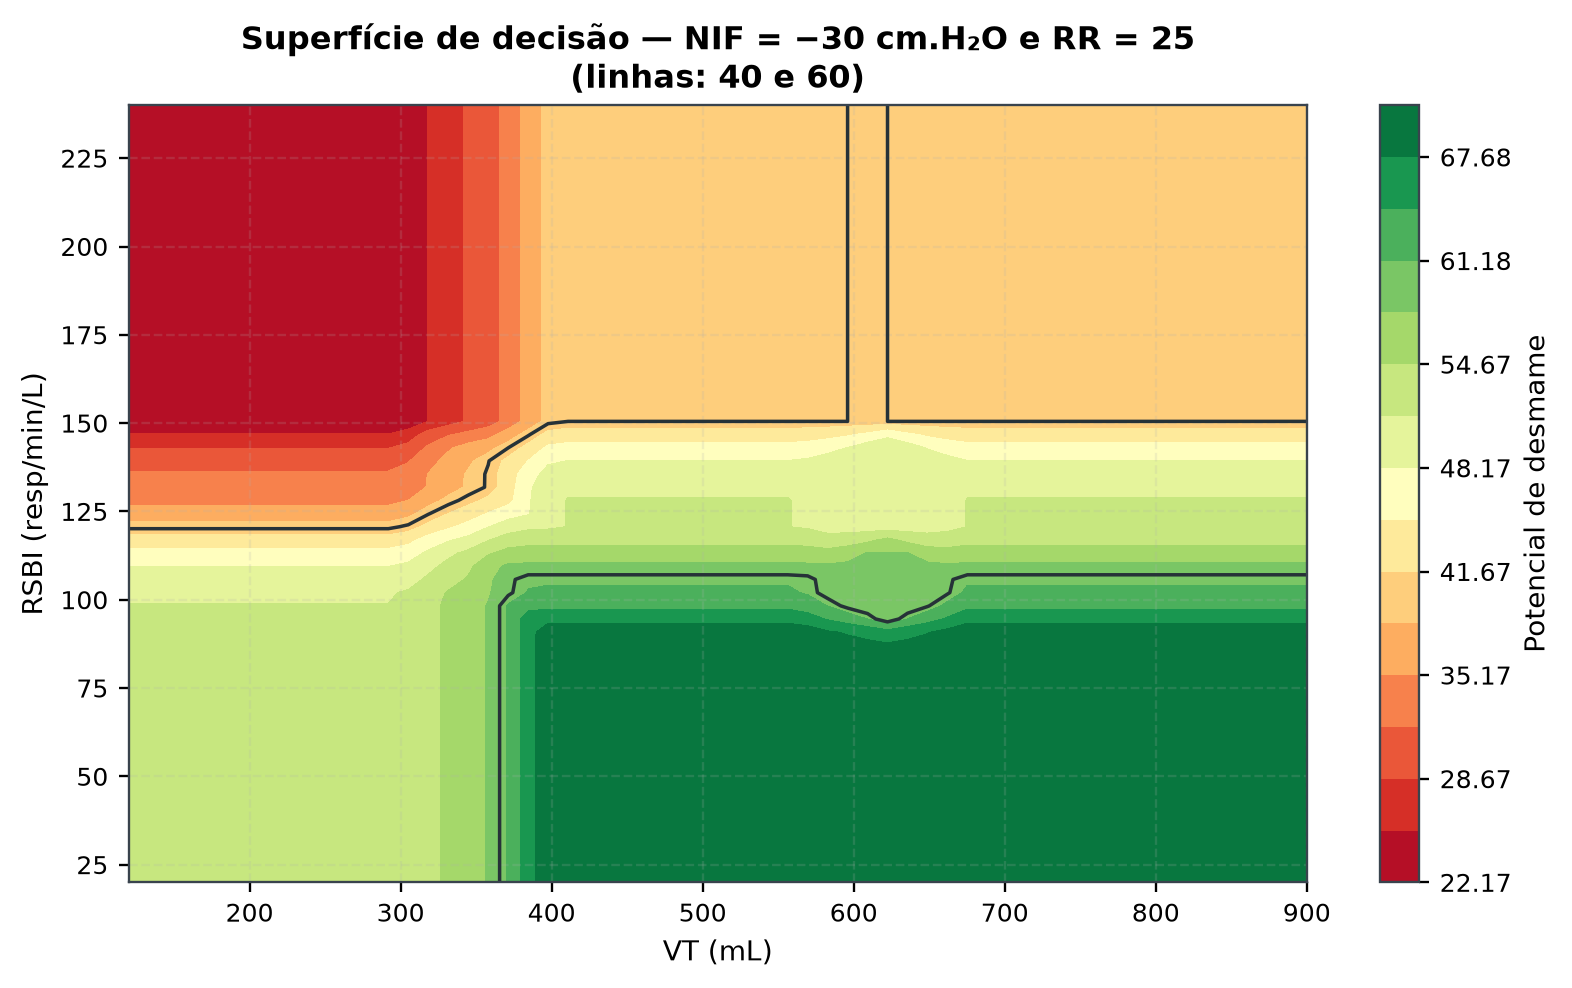

In [30]:
display(Markdown("**Figura 10 — superfície de decisão em função de VT e RSBI.**"))
display(Image(filename=str(FIG / "fig10_superficie_vt_rsbi.png"), width=720))

## 4. Estudos de caso

Os três casos foram escolhidos para cobrir: sucesso claro, fracasso claro e situação crítica/duvidosa. Para cada um, apresentamos fuzzificação, regras ativadas passo a passo, agregação, centroide e interpretação clínica.

In [31]:
case_specs = [
    ("TE5", "Caso 1 — Sucesso claro", "Paciente de teste, todos os indicadores favoráveis; o sistema confirma o desfecho."),
    ("TR10", "Caso 2 — Fracasso claro", "Paciente com padrão respiratório rápido e superficial extremo; todas as regras ativadas levam a Muito Baixo."),
    ("TE3", "Caso 3 — Crítico/duvidoso", "NIF e RR limitrofes, VT baixo e RSBI favorável; as redes divergem e o caso real é fracasso."),
]

### Caso 1 — TE5 (real: **Sucesso**) — {'NIF': -48.0, 'RR': 24.0, 'VT': 380.0, 'RSBI': 63.0}

,Variável,Valor,Termo,μ(x)
0,NIF,-48.000,Fraco,0.000
1,NIF,-48.000,Limítrofe,0.000
2,NIF,-48.000,Forte,1.000
3,RR,24.000,Adequada,0.750
4,RR,24.000,Limítrofe,0.250
5,RR,24.000,Elevada,0.000
6,VT,380.000,Baixo,0.200
7,VT,380.000,Adequado,0.457
8,VT,380.000,Elevado,0.000
9,RSBI,63.000,Favorável,1.000


,Regra,NIF,RR,VT,RSBI,mu_NIF,mu_RR,mu_VT,mu_RSBI,alpha,Consequente
0,55,NIF_Forte,RR_Adequada,VT_Baixo,RSBI_Favoravel,1.000,0.750,0.200,1.000,0.200,A
1,58,NIF_Forte,RR_Adequada,VT_Adequado,RSBI_Favoravel,1.000,0.750,0.457,1.000,0.457,MA
2,64,NIF_Forte,RR_Limitrofe,VT_Baixo,RSBI_Favoravel,1.000,0.250,0.200,1.000,0.200,M
3,67,NIF_Forte,RR_Limitrofe,VT_Adequado,RSBI_Favoravel,1.000,0.250,0.457,1.000,0.250,A


,Área agregada (∫μ dy),Momento (∫y·μ dy),Centroide y* = momento/área,Regras com α>0,Decisão conservadora
0,19.897,1479.824,74.374,4,Sucesso


**Figura 13 — TE5: fuzzificação das quatro entradas.**

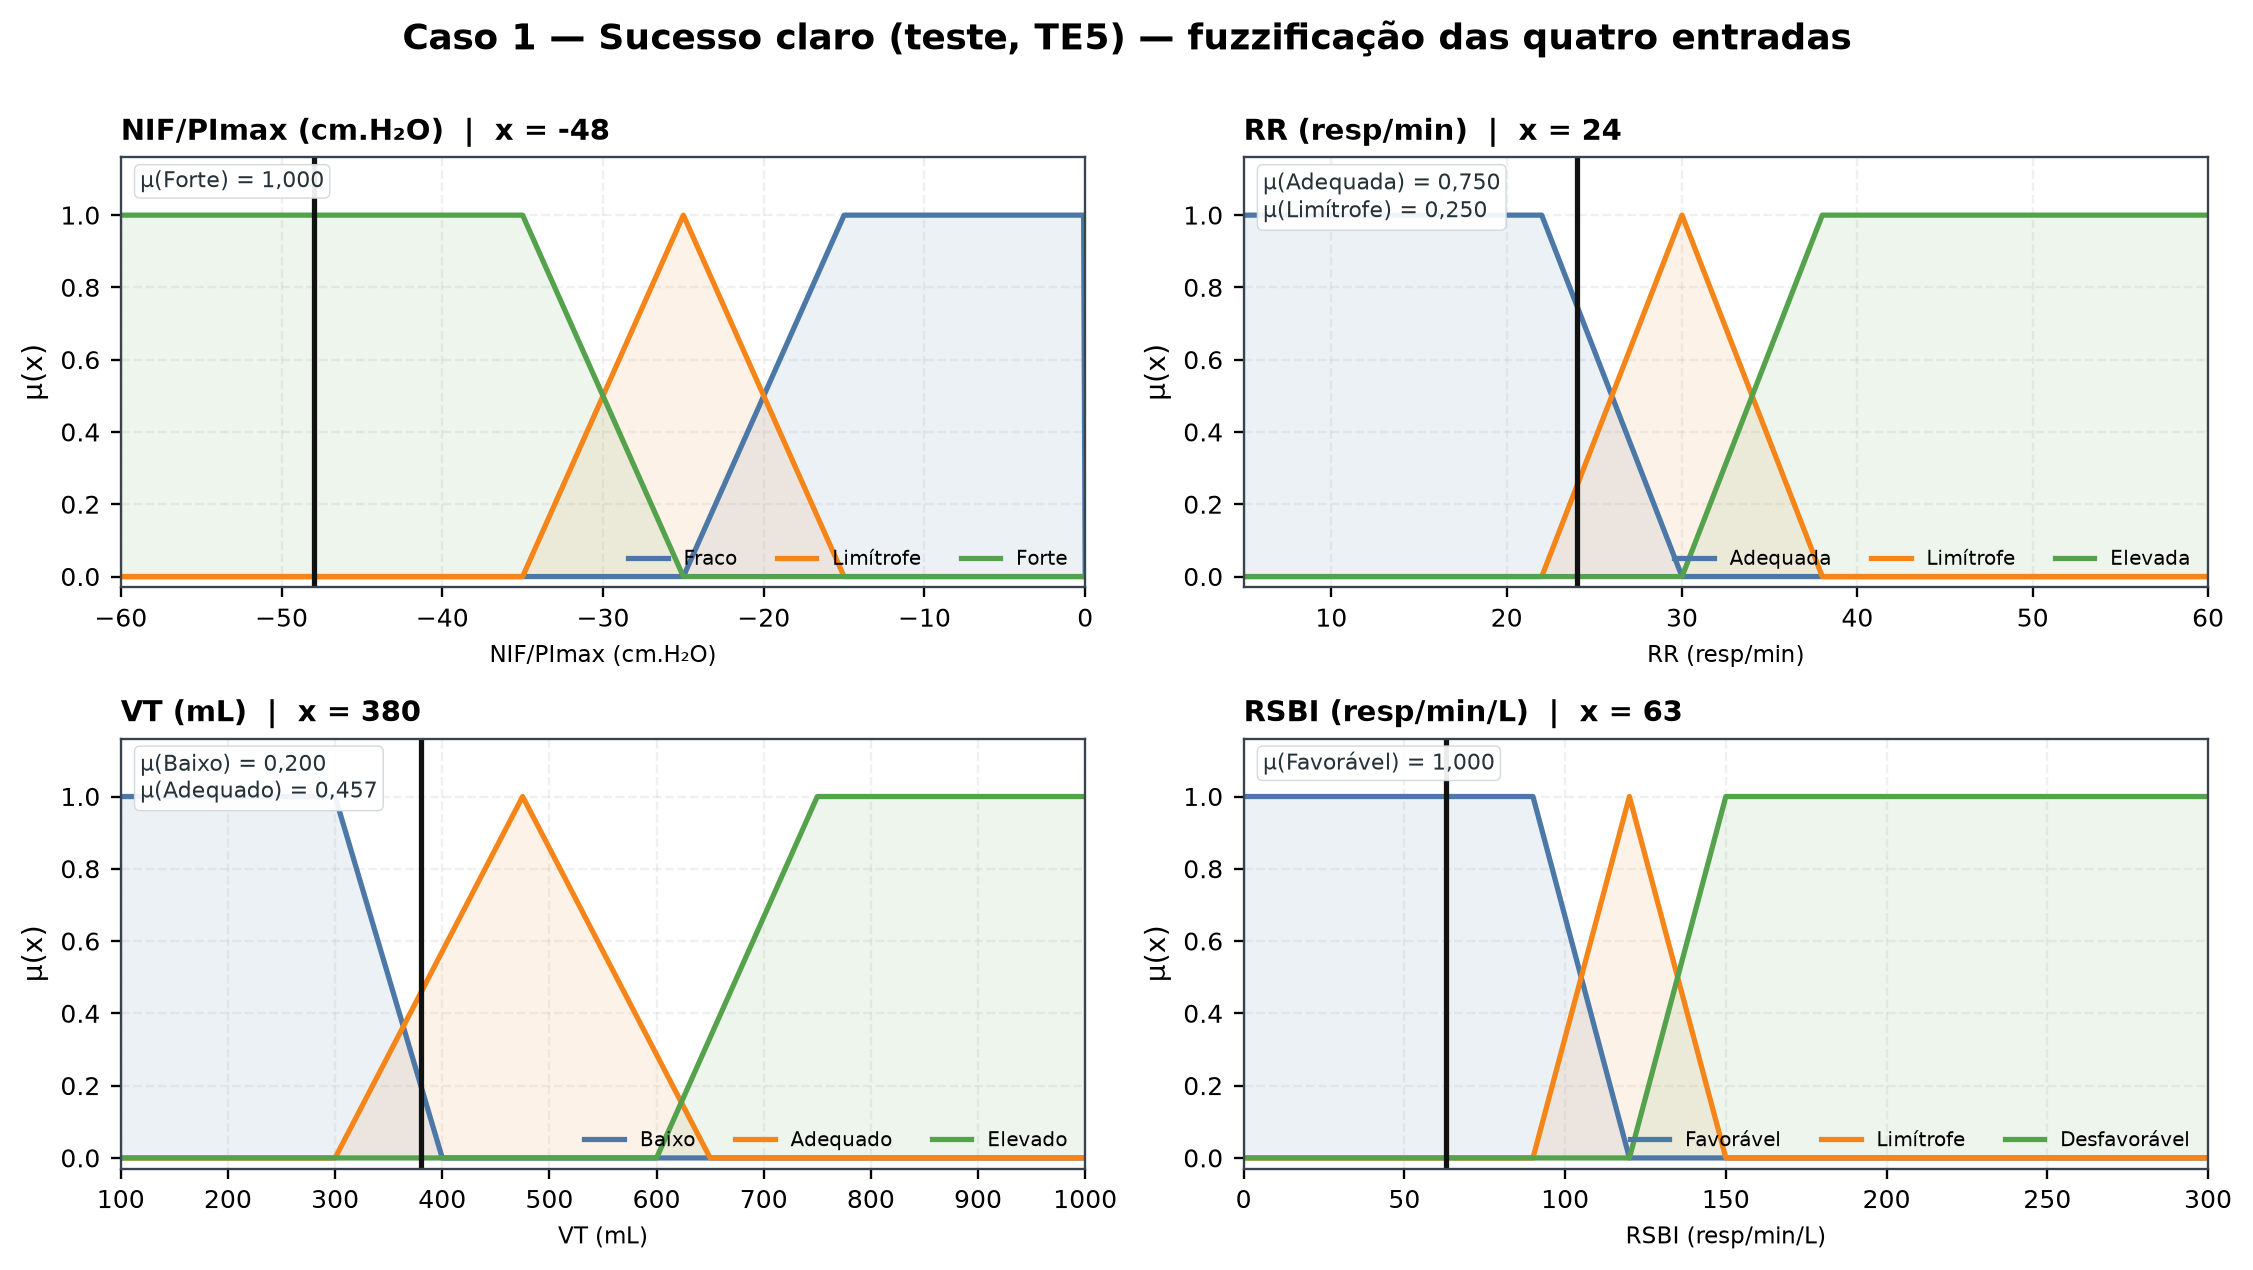

**Figura 14 — TE5: agregação Mamdani, região recortada e centroide.**

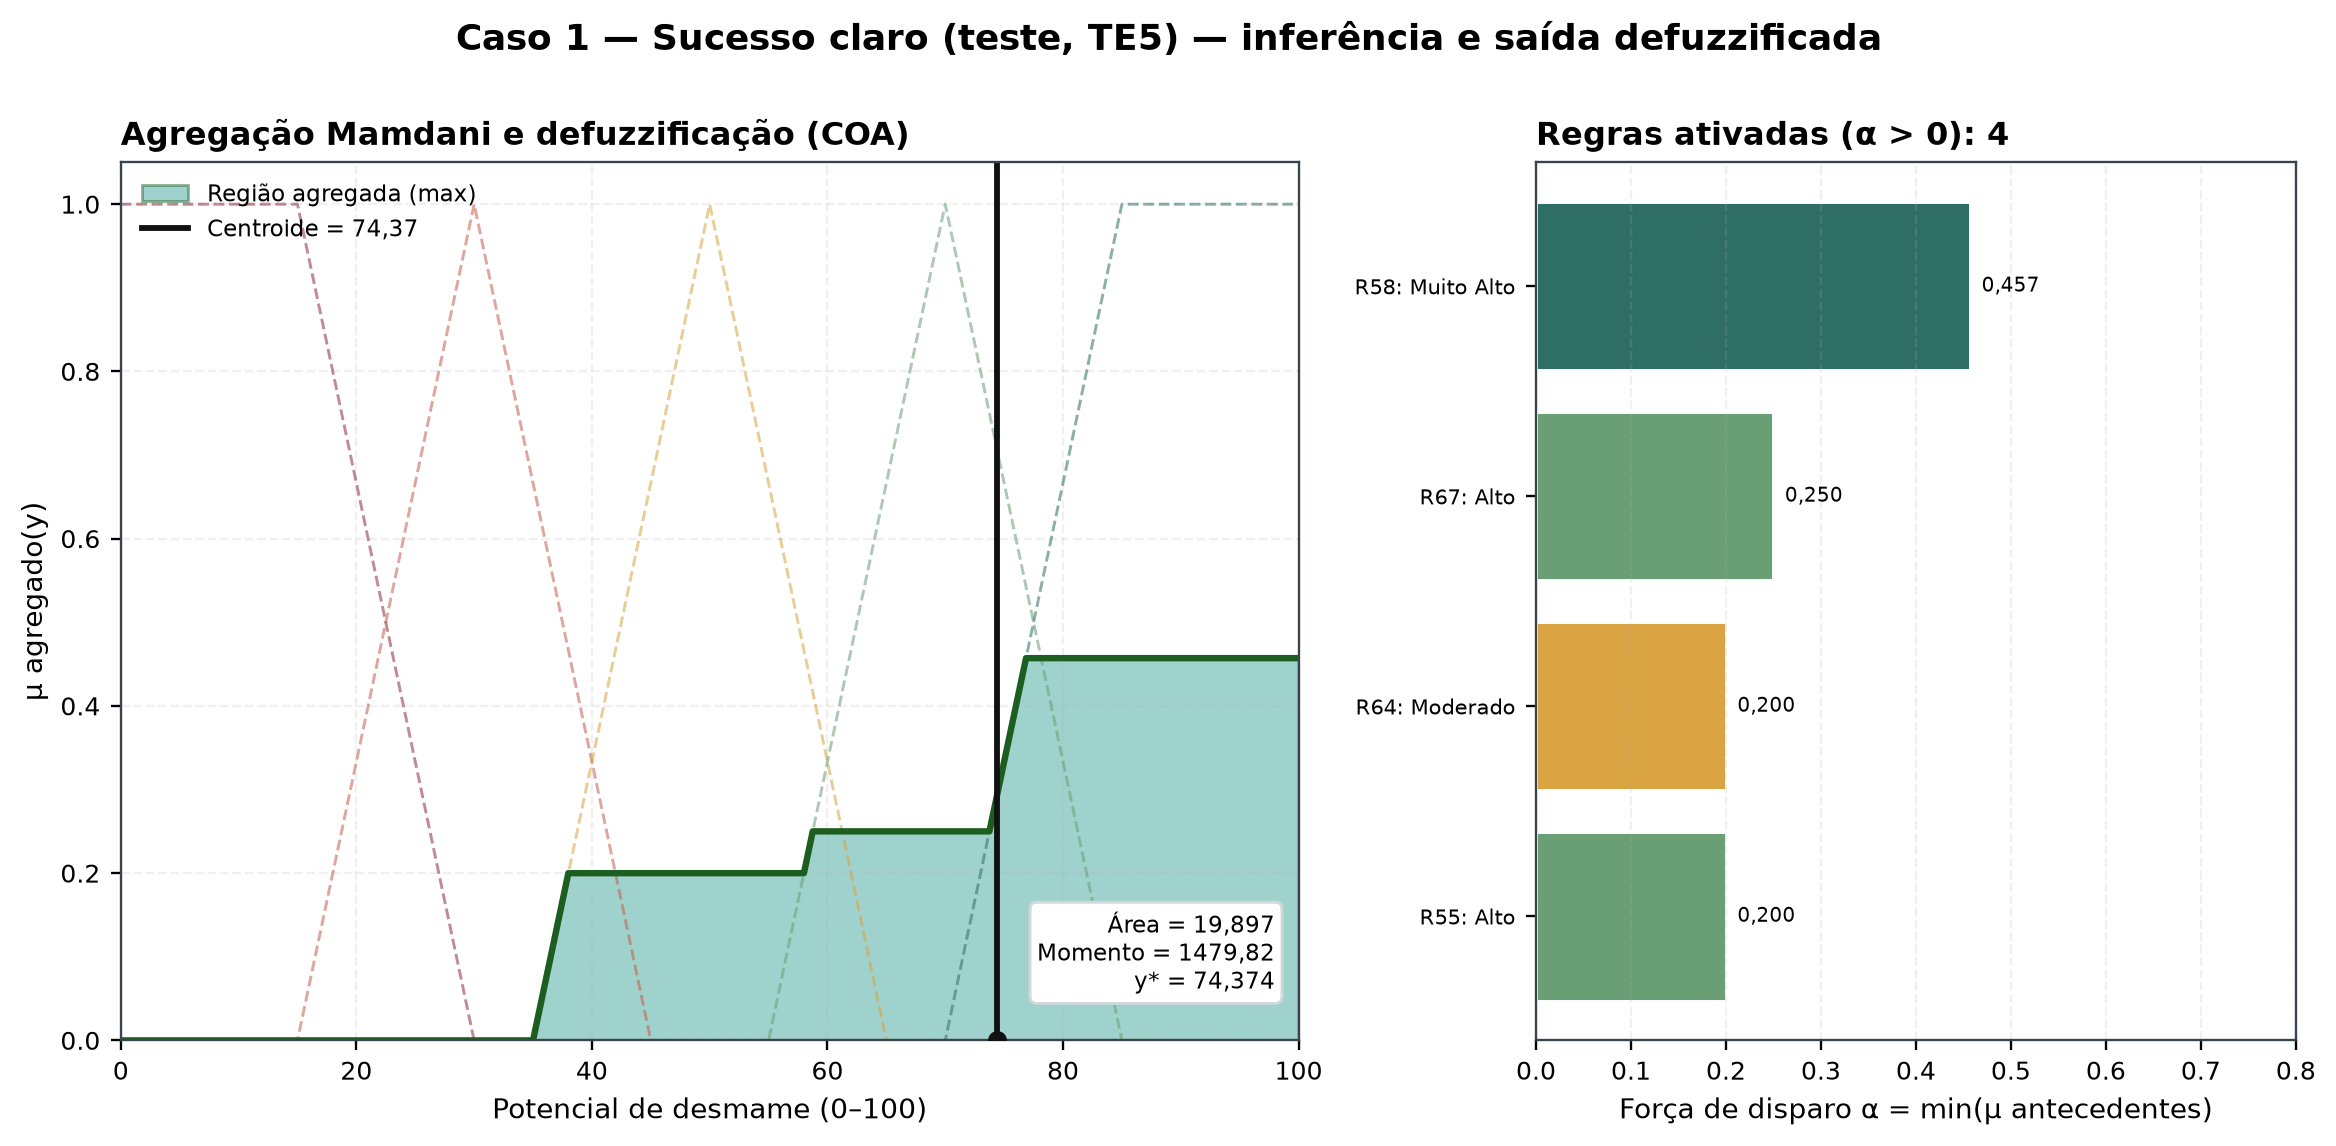

In [32]:
case = full.loc[full.ID == "TE5"].iloc[0]
x = {v: float(case[v]) for v in w.VARIABLES}
res = w.mamdani_evaluate(x)
display(Markdown(f"### Caso 1 — TE5 (real: **{case['Resultado']}**) — {x}"))
display(w.fuzzify_dataframe(res).round(4))
display(pd.DataFrame(res.activations)[["Regra","NIF","RR","VT","RSBI","mu_NIF","mu_RR","mu_VT","mu_RSBI","alpha","Consequente"]].round(4))
display(pd.DataFrame([w.defuzz_summary(res)]).round(4))
display(Markdown("**Figura 13 — TE5: fuzzificação das quatro entradas.**"))
display(Image(filename=str(FIG / "fig13_caso1_entradas.png"), width=1000))
display(Markdown("**Figura 14 — TE5: agregação Mamdani, região recortada e centroide.**"))
display(Image(filename=str(FIG / "fig14_caso1_saida.png"), width=1000))

**Caso 1 — interpretação.** NIF −48 é forte (μ=1,000); RR 24 é predominantemente adequada (0,750) com 0,250 de limitrofe; VT 380 é 0,200 baixo e 0,457 adequado; RSBI 63 é totalmente favorável. Quatro regras disparam. A regra 58 (Forte, Adequada, Adequado, Favorável → Muito Alto) tem α=0,457 e domina a agregação. O centroide é **74,37**, acima de 60: recomendação de sucesso. O desfecho real foi sucesso, e as duas redes Naive Bayes também acertaram (89,4% e 95,8%).

### Caso 2 — TR10 (real: **Fracasso**) — {'NIF': -20.0, 'RR': 33.0, 'VT': 124.0, 'RSBI': 266.0}

,Variável,Valor,Termo,μ(x)
0,NIF,-20.000,Fraco,0.500
1,NIF,-20.000,Limítrofe,0.500
2,NIF,-20.000,Forte,0.000
3,RR,33.000,Adequada,0.000
4,RR,33.000,Limítrofe,0.625
5,RR,33.000,Elevada,0.375
6,VT,124.000,Baixo,1.000
7,VT,124.000,Adequado,0.000
8,VT,124.000,Elevado,0.000
9,RSBI,266.000,Favorável,0.000


,Regra,NIF,RR,VT,RSBI,mu_NIF,mu_RR,mu_VT,mu_RSBI,alpha,Consequente
0,12,NIF_Fraco,RR_Limitrofe,VT_Baixo,RSBI_Desfavoravel,0.500,0.625,1.000,1.000,0.500,MB
1,21,NIF_Fraco,RR_Elevada,VT_Baixo,RSBI_Desfavoravel,0.500,0.375,1.000,1.000,0.375,MB
2,39,NIF_Limitrofe,RR_Limitrofe,VT_Baixo,RSBI_Desfavoravel,0.500,0.625,1.000,1.000,0.500,MB
3,48,NIF_Limitrofe,RR_Elevada,VT_Baixo,RSBI_Desfavoravel,0.500,0.375,1.000,1.000,0.375,MB


,Área agregada (∫μ dy),Momento (∫y·μ dy),Centroide y* = momento/área,Regras com α>0,Decisão conservadora
0,13.125,173.438,13.214,4,Fracasso


**Figura 15 — TR10: fuzzificação das quatro entradas.**

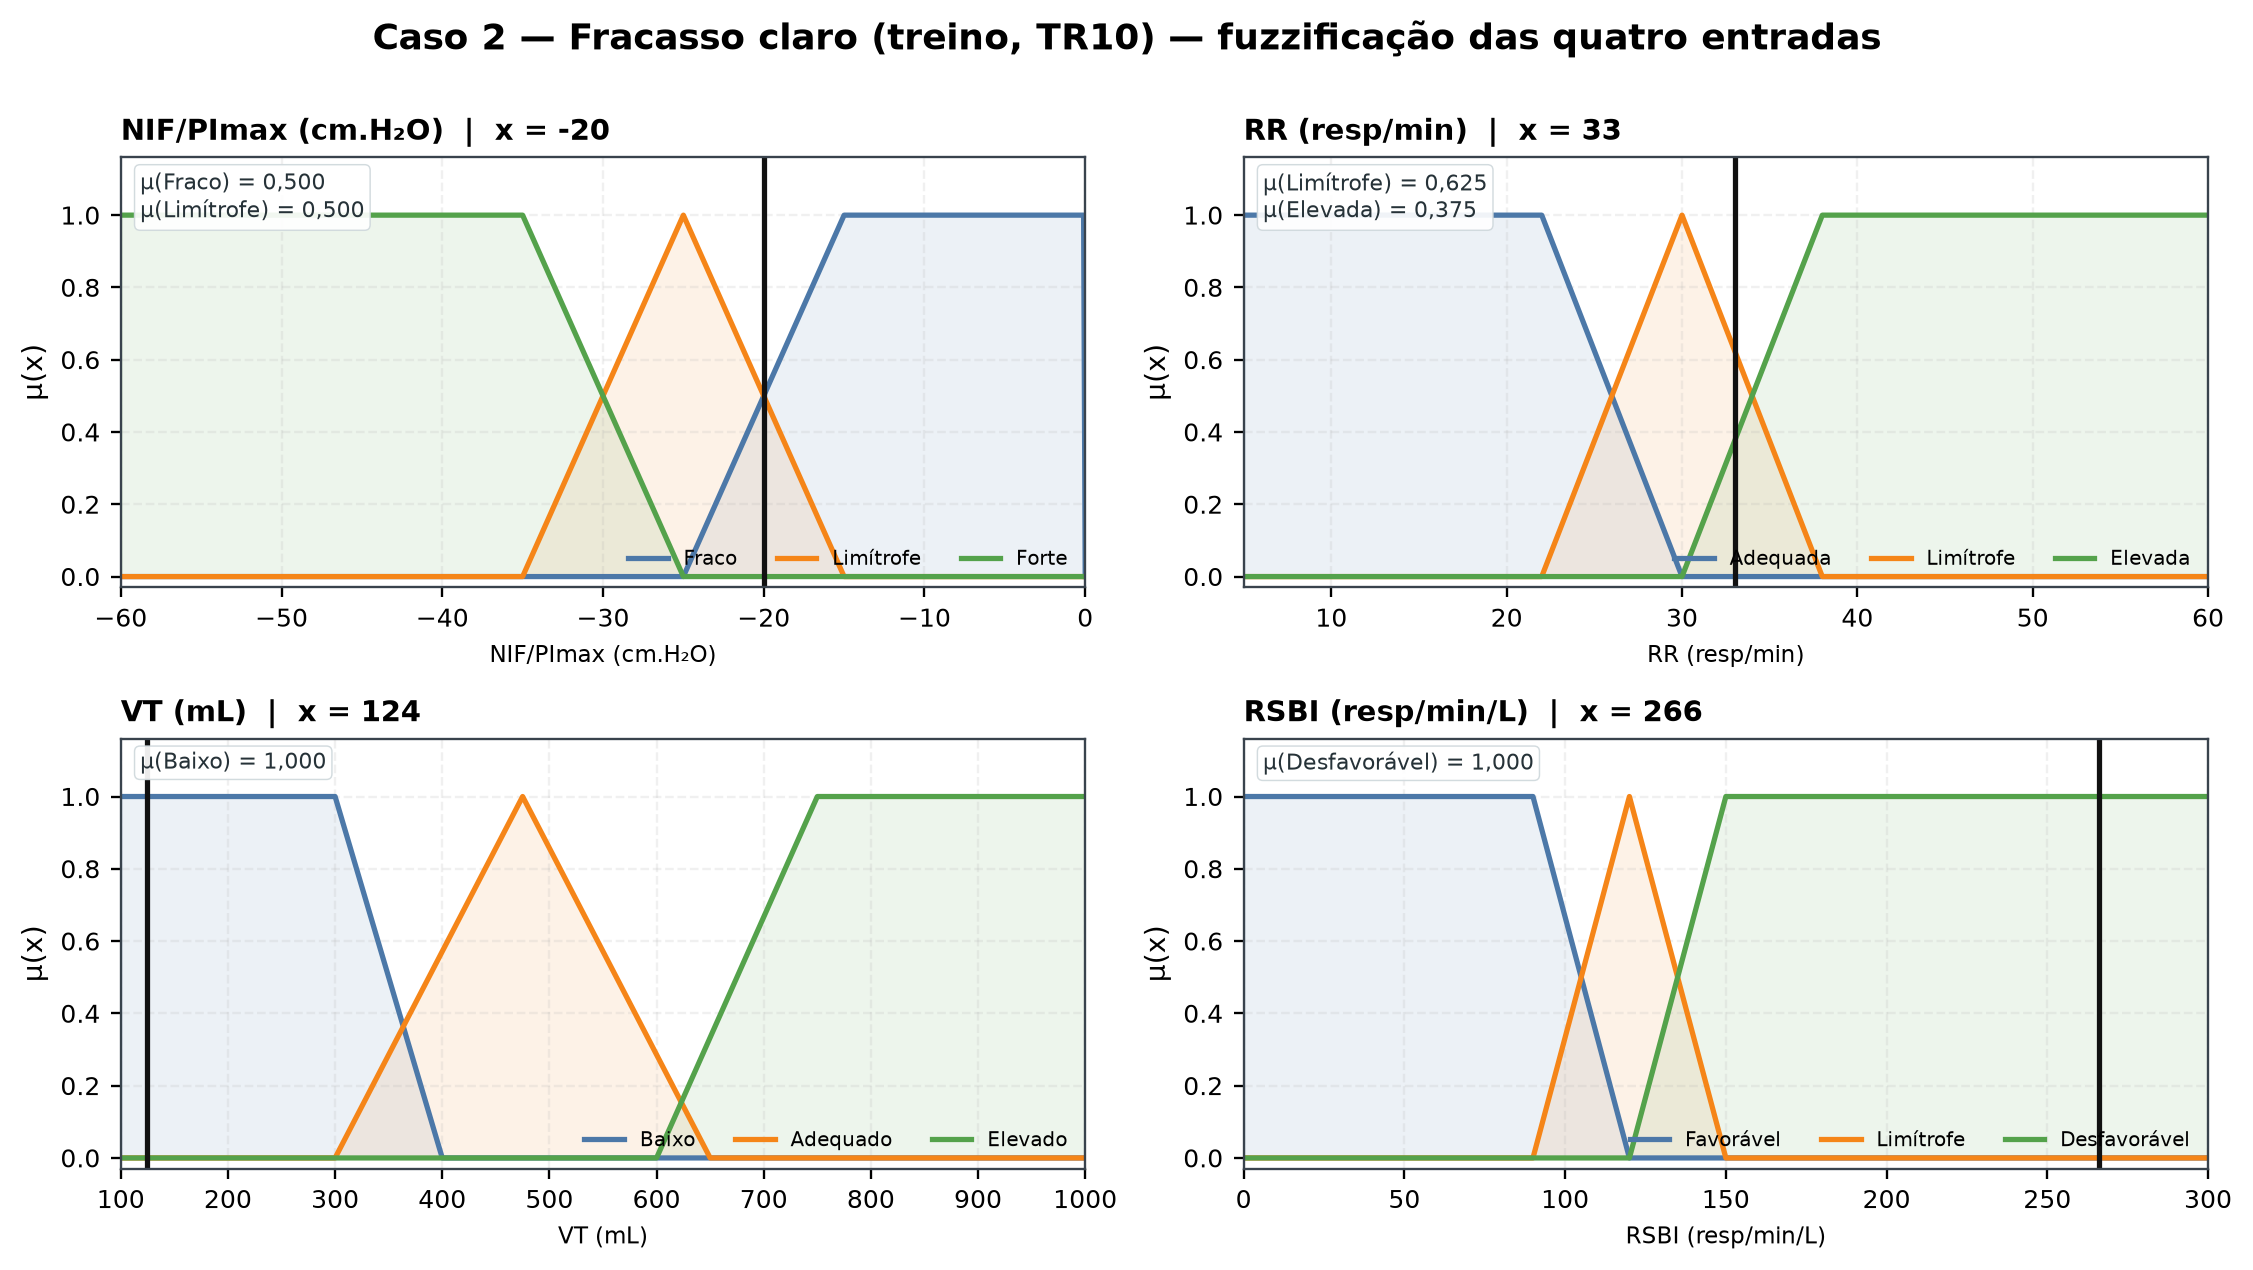

**Figura 16 — TR10: agregação Mamdani, região recortada e centroide.**

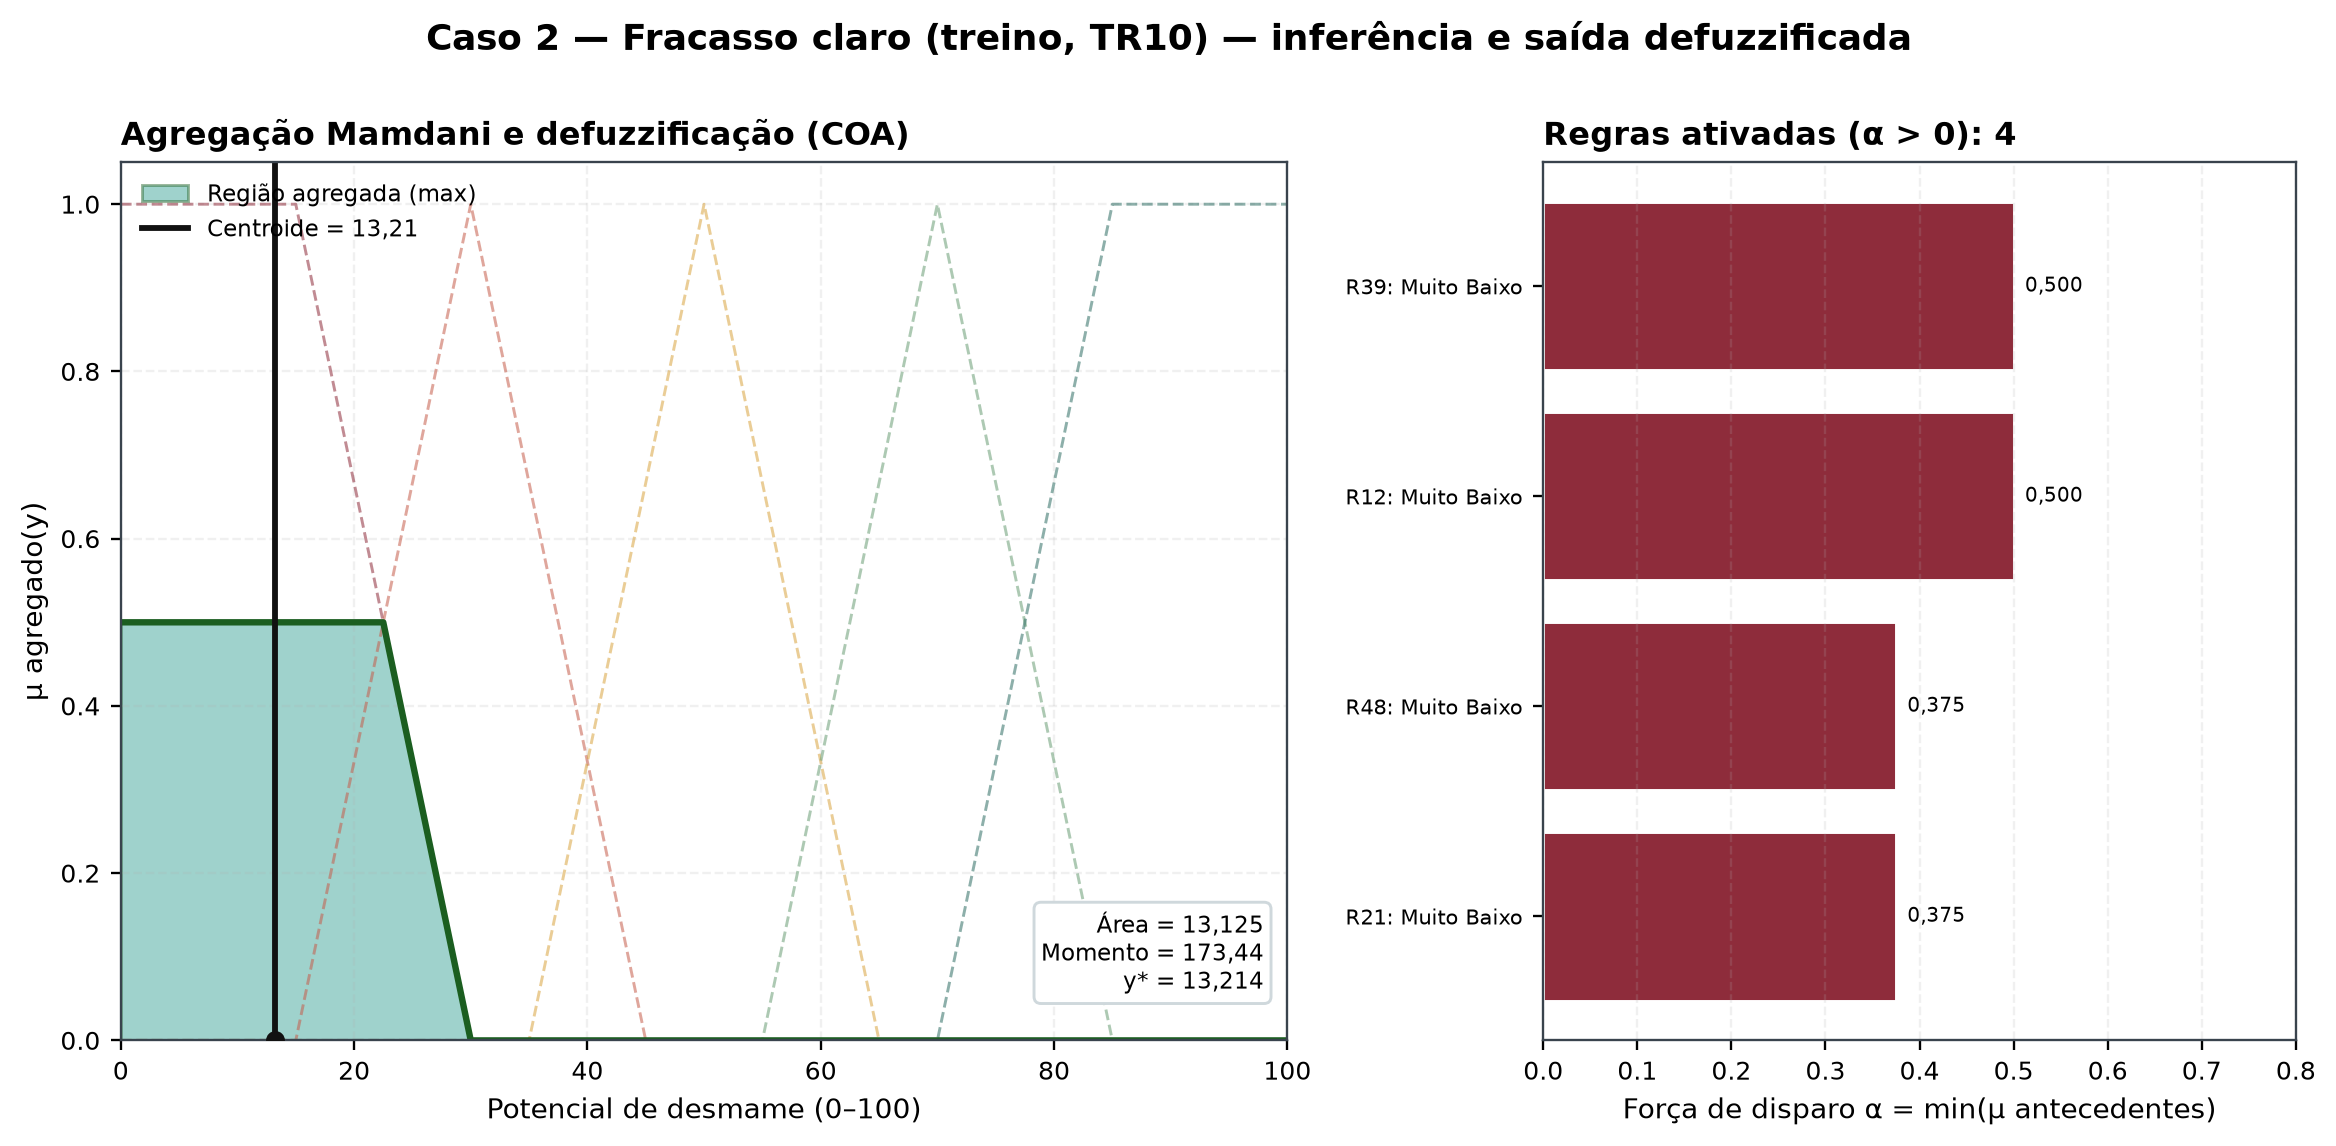

In [33]:
case = full.loc[full.ID == "TR10"].iloc[0]
x = {v: float(case[v]) for v in w.VARIABLES}
res = w.mamdani_evaluate(x)
display(Markdown(f"### Caso 2 — TR10 (real: **{case['Resultado']}**) — {x}"))
display(w.fuzzify_dataframe(res).round(4))
display(pd.DataFrame(res.activations)[["Regra","NIF","RR","VT","RSBI","mu_NIF","mu_RR","mu_VT","mu_RSBI","alpha","Consequente"]].round(4))
display(pd.DataFrame([w.defuzz_summary(res)]).round(4))
display(Markdown("**Figura 15 — TR10: fuzzificação das quatro entradas.**"))
display(Image(filename=str(FIG / "fig15_caso2_entradas.png"), width=1000))
display(Markdown("**Figura 16 — TR10: agregação Mamdani, região recortada e centroide.**"))
display(Image(filename=str(FIG / "fig16_caso2_saida.png"), width=1000))

**Caso 2 — interpretação.** NIF −20 divide-se igualmente entre fraco e limitrofe; RR 33 é 0,625 limitrofe e 0,375 elevada; VT 124 é totalmente baixo; RSBI 266 é totalmente desfavorável. As quatro regras ativadas têm consequente Muito Baixo; a maior força é 0,500. A região agregada é o trapézio Muito Baixo cortado em 0,5, e o centroide é **13,21**: recomendação de fracasso, coerente com o desfecho. As redes Naive Bayes também acertaram com probabilidades de sucesso de 1,0% e 1,8%.

### Caso 3 — TE3 (real: **Fracasso**) — {'NIF': -28.0, 'RR': 24.0, 'VT': 310.0, 'RSBI': 77.0}

,Variável,Valor,Termo,μ(x)
0,NIF,-28.000,Fraco,0.000
1,NIF,-28.000,Limítrofe,0.700
2,NIF,-28.000,Forte,0.300
3,RR,24.000,Adequada,0.750
4,RR,24.000,Limítrofe,0.250
5,RR,24.000,Elevada,0.000
6,VT,310.000,Baixo,0.900
7,VT,310.000,Adequado,0.057
8,VT,310.000,Elevado,0.000
9,RSBI,77.000,Favorável,1.000


,Regra,NIF,RR,VT,RSBI,mu_NIF,mu_RR,mu_VT,mu_RSBI,alpha,Consequente
0,28,NIF_Limitrofe,RR_Adequada,VT_Baixo,RSBI_Favoravel,0.700,0.750,0.900,1.000,0.700,M
1,31,NIF_Limitrofe,RR_Adequada,VT_Adequado,RSBI_Favoravel,0.700,0.750,0.057,1.000,0.057,A
2,37,NIF_Limitrofe,RR_Limitrofe,VT_Baixo,RSBI_Favoravel,0.700,0.250,0.900,1.000,0.250,B
3,40,NIF_Limitrofe,RR_Limitrofe,VT_Adequado,RSBI_Favoravel,0.700,0.250,0.057,1.000,0.057,M
4,55,NIF_Forte,RR_Adequada,VT_Baixo,RSBI_Favoravel,0.300,0.750,0.900,1.000,0.300,A
5,58,NIF_Forte,RR_Adequada,VT_Adequado,RSBI_Favoravel,0.300,0.750,0.057,1.000,0.057,MA
6,64,NIF_Forte,RR_Limitrofe,VT_Baixo,RSBI_Favoravel,0.300,0.250,0.900,1.000,0.250,M
7,67,NIF_Forte,RR_Limitrofe,VT_Adequado,RSBI_Favoravel,0.300,0.250,0.057,1.000,0.057,A


,Área agregada (∫μ dy),Momento (∫y·μ dy),Centroide y* = momento/área,Regras com α>0,Decisão conservadora
0,25.532,1334.735,52.278,8,Fracasso


**Figura 17 — TE3: fuzzificação das quatro entradas.**

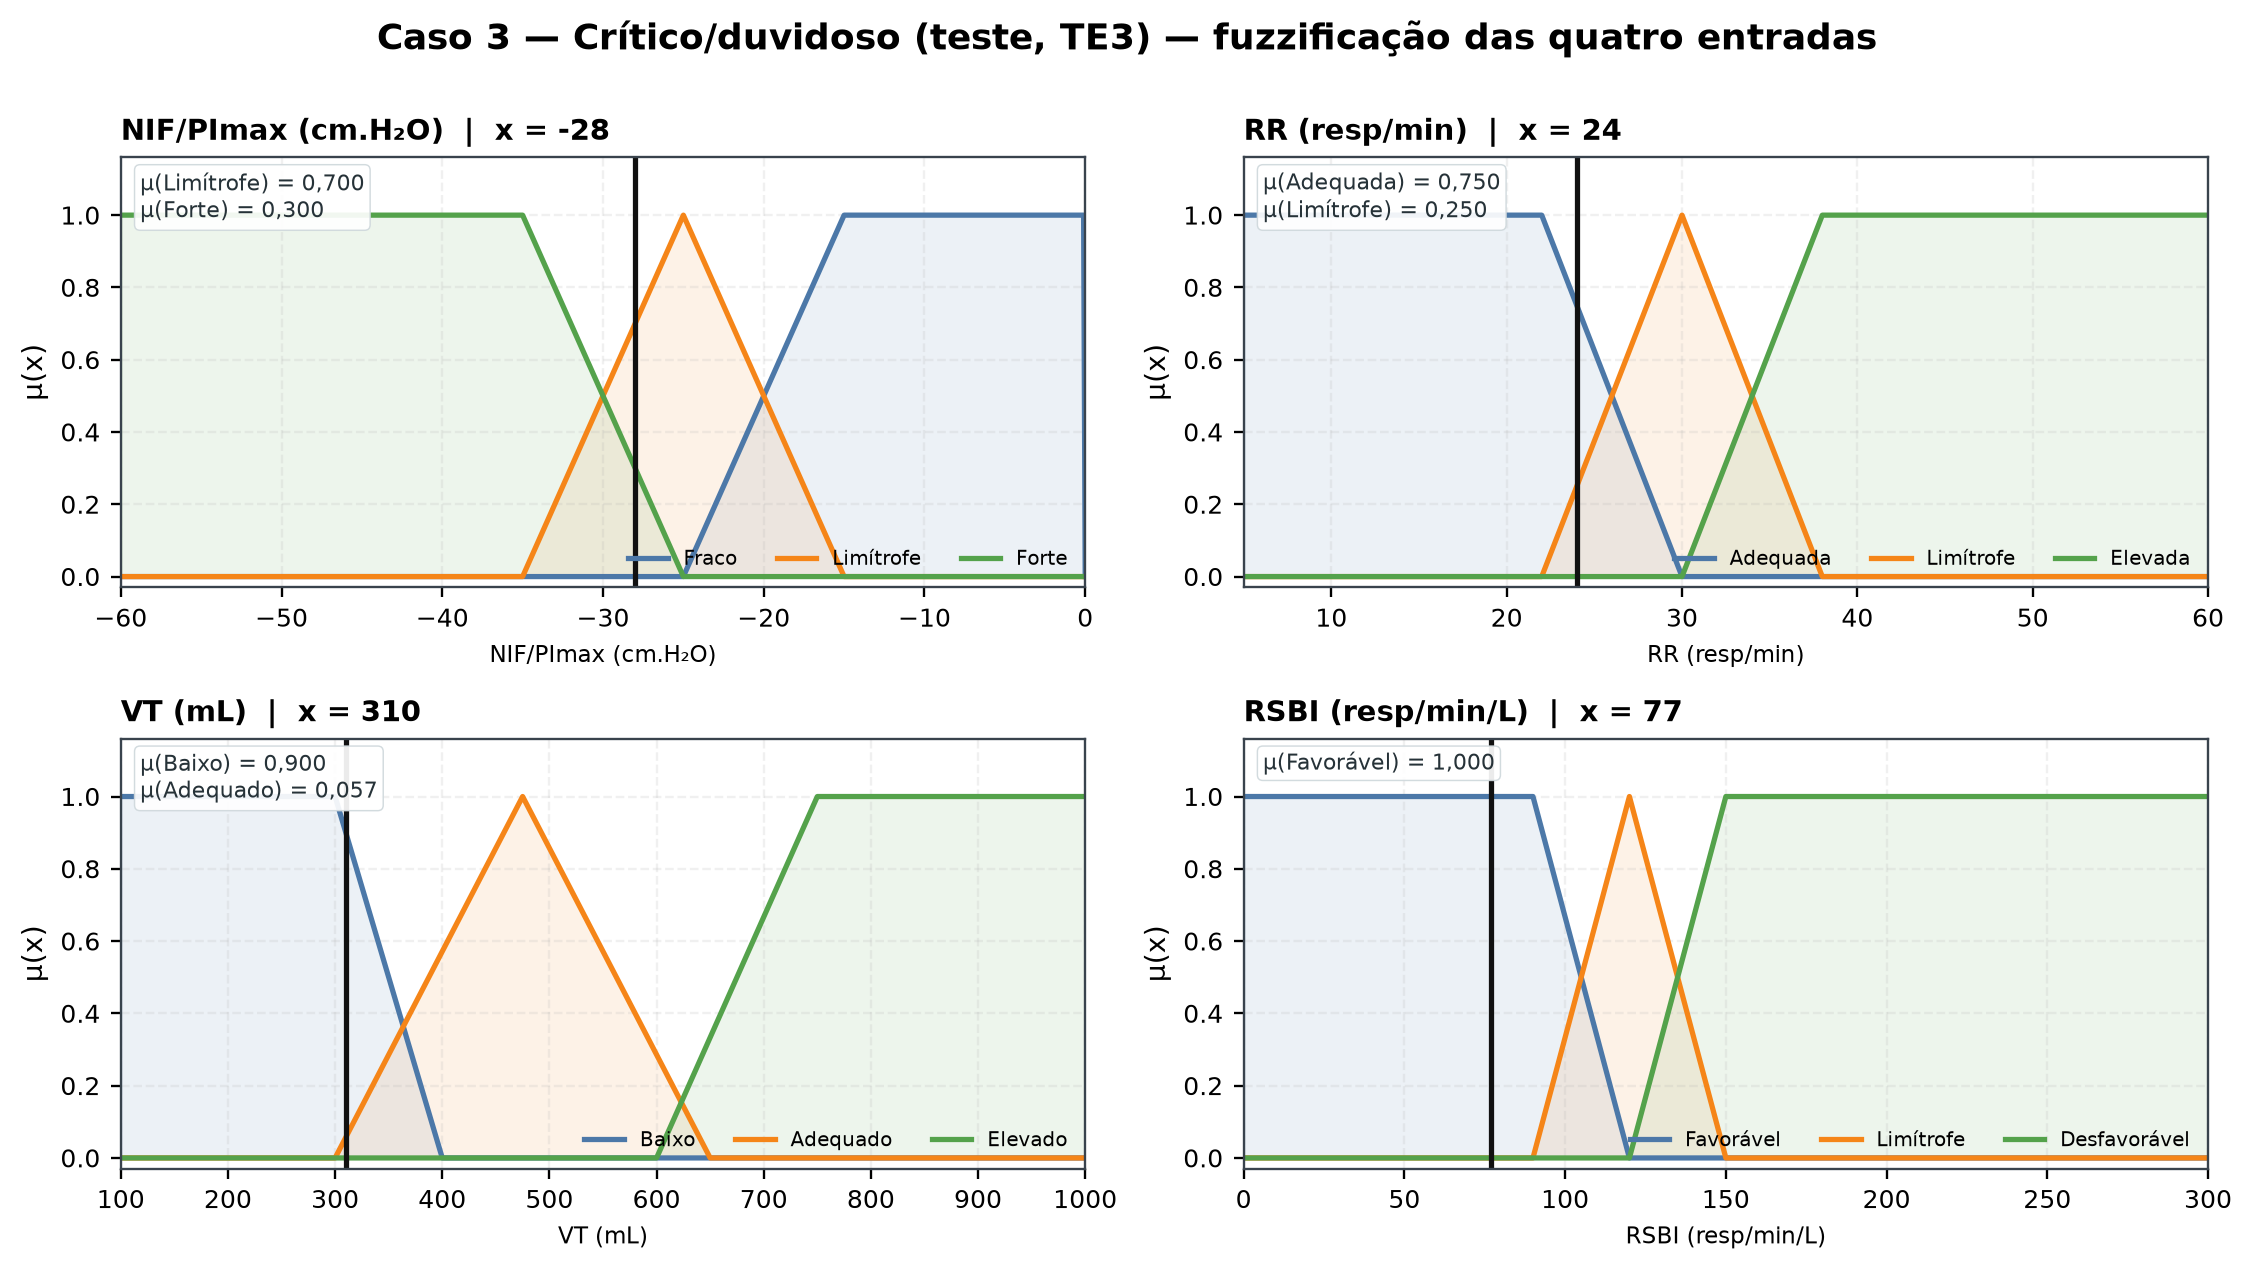

**Figura 18 — TE3: agregação Mamdani, região recortada e centroide.**

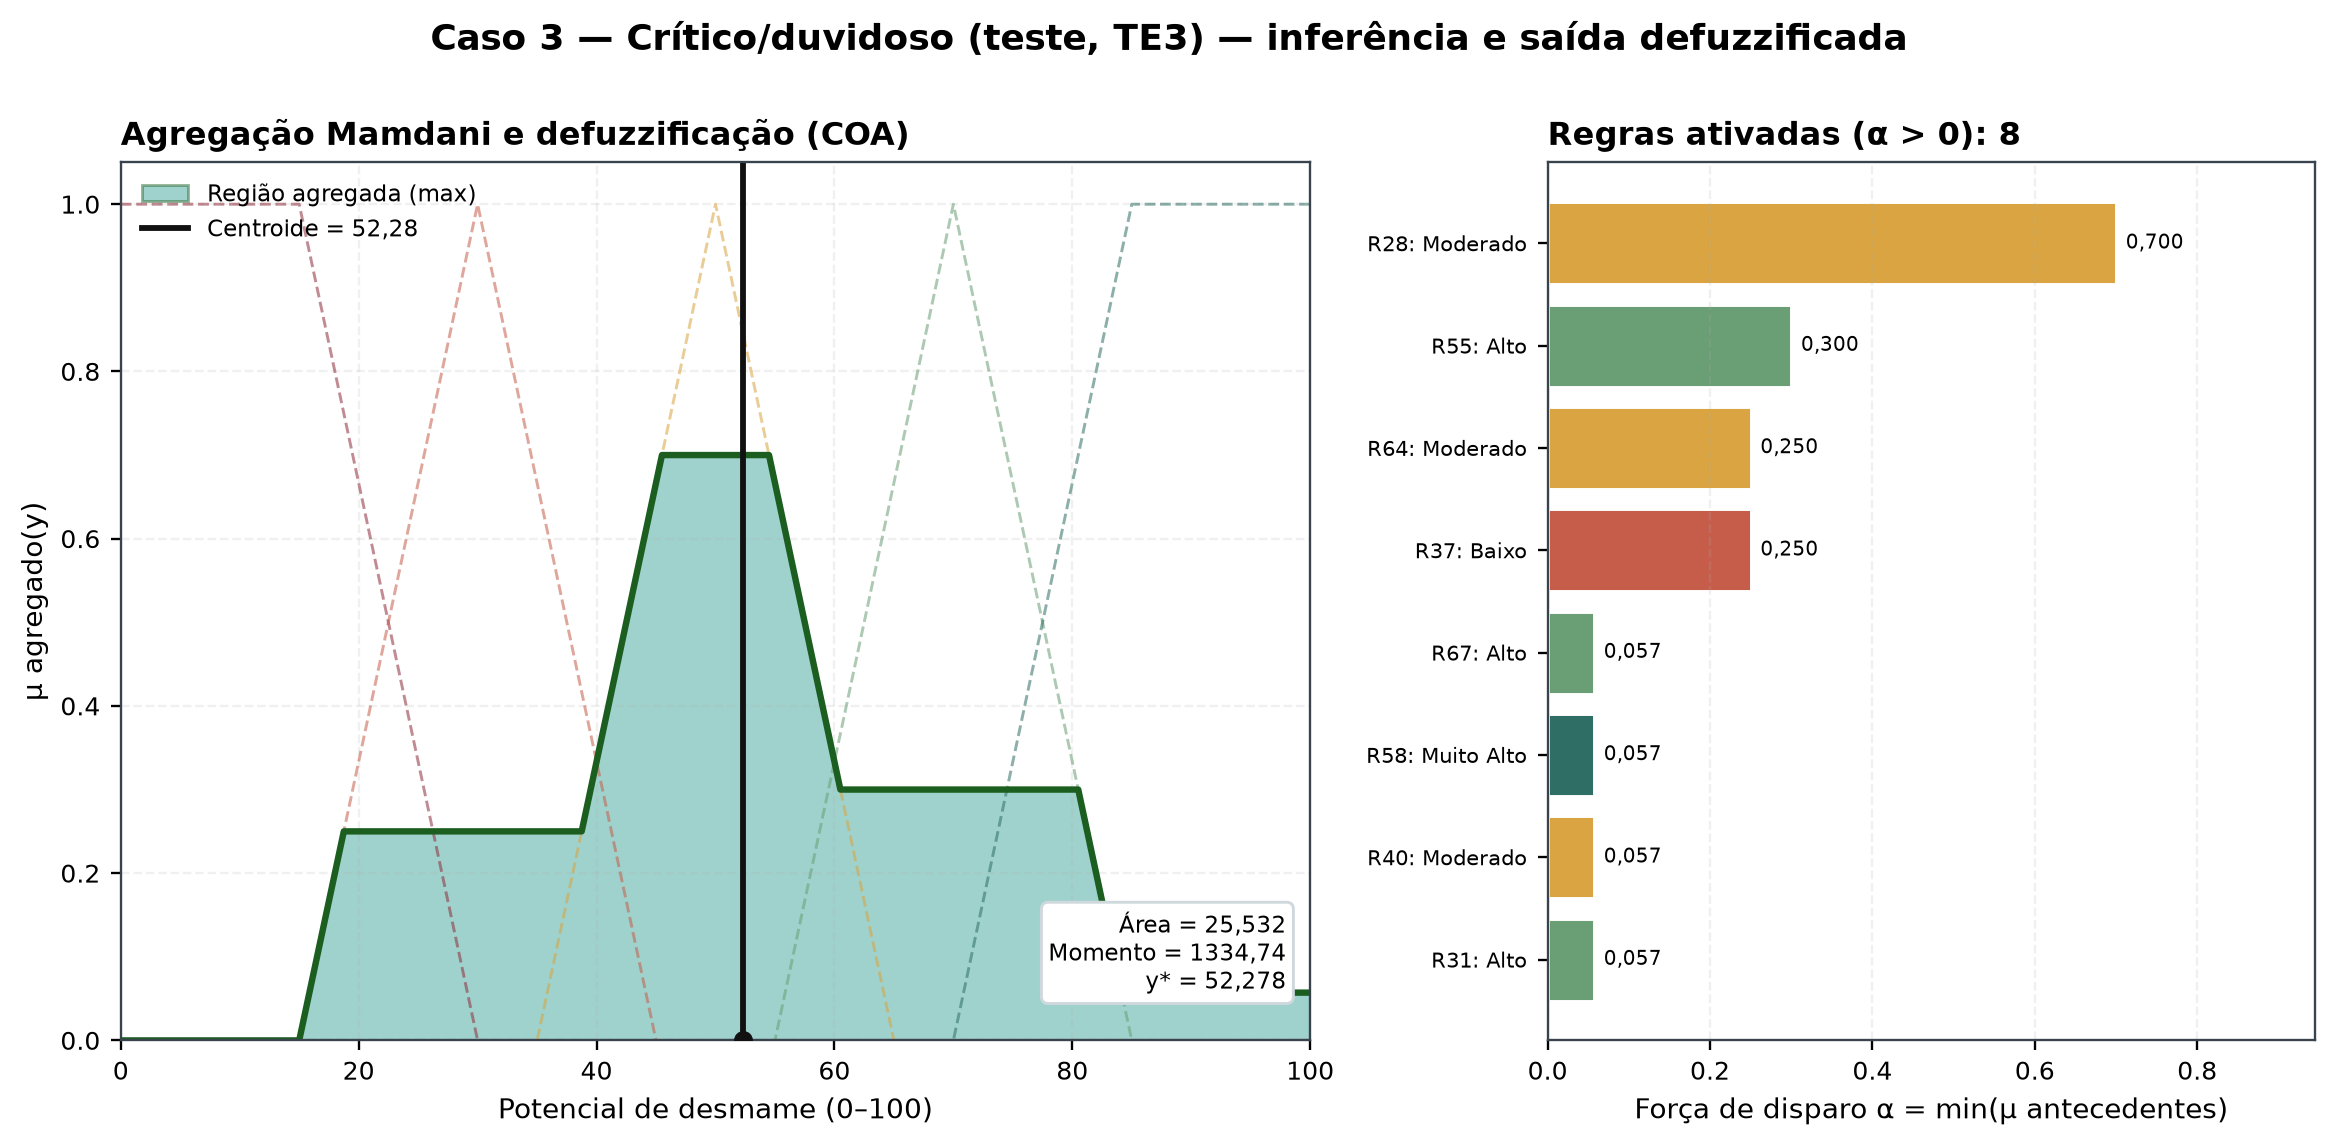

In [34]:
case = full.loc[full.ID == "TE3"].iloc[0]
x = {v: float(case[v]) for v in w.VARIABLES}
res = w.mamdani_evaluate(x)
display(Markdown(f"### Caso 3 — TE3 (real: **{case['Resultado']}**) — {x}"))
display(w.fuzzify_dataframe(res).round(4))
act = pd.DataFrame(res.activations)[["Regra","NIF","RR","VT","RSBI","mu_NIF","mu_RR","mu_VT","mu_RSBI","alpha","Consequente"]].round(4)
display(act)
display(pd.DataFrame([w.defuzz_summary(res)]).round(4))
display(Markdown("**Figura 17 — TE3: fuzzificação das quatro entradas.**"))
display(Image(filename=str(FIG / "fig17_caso3_entradas.png"), width=1000))
display(Markdown("**Figura 18 — TE3: agregação Mamdani, região recortada e centroide.**"))
display(Image(filename=str(FIG / "fig18_caso3_saida.png"), width=1000))

**Caso 3 — interpretação.** O paciente tem NIF −28 (0,700 limitrofe e 0,300 forte), RR 24 (0,750 adequada e 0,250 limitrofe), VT 310 (0,900 baixo e 0,057 adequado) e RSBI 77 (totalmente favorável). Há oito regras ativadas, com consequentes conflitantes: a regra 28 (Moderado) tem α=0,700, mas regras de Alto, Baixo e Muito Alto também disparam com forças menores. A agregação produz uma região multimodal; o centroide é **52,28**, dentro da faixa de cautela (40–60). A recomendação é **não liberar e reavaliar**. O desfecho real foi fracasso. A Rede 1 também prediz fracasso (44,2%), mas a Rede 2 prediz sucesso com 90,6% — uma divergência clinicamente perigosa que ilustra o risco da discretização excessivamente grosseira.

## 5. Comparação geral e conclusão

### 5.1 Desempenho na base completa

,Modelo,Acurácia,Sensibilidade,Especificidade,PPV,NPV,F1,TN,FP,FN,TP
0,Naive Bayes 1 (clínica),90.000,86.700,93.300,92.900,87.500,89.700,14,1,2,13
1,Naive Bayes 2 (Netica),83.300,86.700,80.000,81.200,85.700,83.900,12,3,2,13
2,Fuzzy Mamdani (≥60),86.700,80.000,93.300,92.300,82.400,85.700,14,1,3,12


**Figura 19 — comparação final dos três modelos na base completa.**

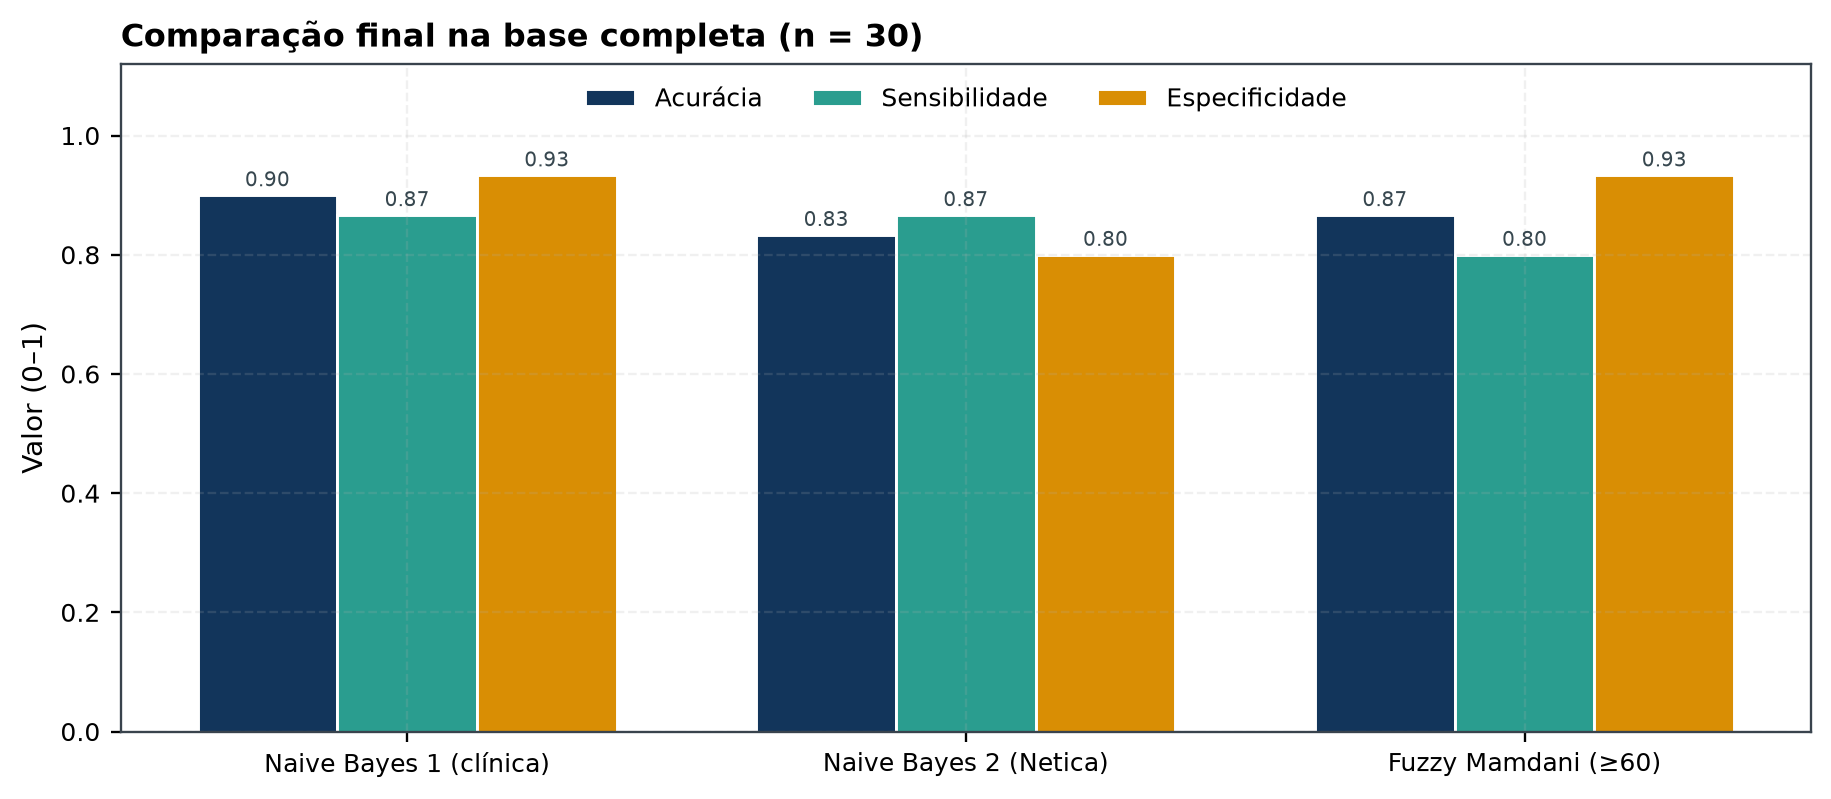

In [35]:
final = pd.read_csv(TAB / "20_comparacao_final.csv")
show = final.copy()
for c in ["Acurácia","Sensibilidade","Especificidade","PPV","NPV","F1"]:
    show[c] = (show[c] * 100).round(1)
display(show[["Modelo","Acurácia","Sensibilidade","Especificidade","PPV","NPV","F1","TN","FP","FN","TP"]])
display(Markdown("**Figura 19 — comparação final dos três modelos na base completa.**"))
display(Image(filename=str(FIG / "fig19_comparacao_final.png"), width=850))

### 5.2 Interpretação comparativa

| Critério | Naive Bayes 1 (clínica) | Naive Bayes 2 (Netica) | Fuzzy Mamdani |
|---|---|---|---|
| Acurácia (30) | **90,0%** | 83,3% | 86,7% |
| Sensibilidade | **86,7%** | **86,7%** | 80,0% |
| Especificidade | **93,3%** | 80,0% | **93,3%** |
| Calibração | Brier 0,078 | Brier 0,137 | não probabilístico |
| Transparência | CPTs e cortes | CPTs e 2 faixas | 81 regras linguísticas |
| Incerteza no limiar | posteriores extremas | posteriores extremas | saída graduada + cautela |
| Principal fragilidade | dupla contagem RR/VT/RSBI | perda de resolução | 81 regras, custo de projeto |

- **Desempenho:** a Rede 1 é a melhor na base completa e no teste; a Rede 2 é mais confiante e menos específica; o fuzzy é competitivo, com melhor especificidade e sensibilidade menor.
- **Interpretabilidade:** a Rede 1 permite ler diretamente “P(NIF forte | sucesso)” e explicar cada contribuição; o fuzzy permite frases como “SE NIF é forte E RR é adequada…”. A Rede 2 é mais simples, mas essa simplicidade custa informação clínica.
- **Incerteza:** as redes produzem probabilidades, mas com 21 casos e forte dependência entre preditores elas são pontiagudas demais. O fuzzy produz um potencial graduado, mas o limiar de 60 é uma escolha de política; a faixa 40–60 é uma forma explícita de dizer “não sei”.
- **Correlação:** o fuzzy não exige independência, mas ao usar RR, VT e RSBI também reforça o mesmo padrão. A diferença é que isso é uma decisão de modelagem visível, não uma hipótese probabilística implícita.
- **Risco clínico:** nenhum modelo deve liberar um paciente sozinho. A recomendação é usar a Rede 1 como triagem, o fuzzy como segunda opinião nos casos 40–60 e sempre integrar gasometria, consciência, secreção, tosse, estabilidade hemodinâmica e avaliação do fisioterapeuta/médico.

### 5.3 Limitações

1. Amostra pequena e histórica (1992), com apenas 30 tentativas e 9 no teste; os intervalos de confiança são largos.
2. Variáveis medidas em um único momento, sem tendência temporal.
3. Não há informações de sedação, balanço hídrico, comorbidades, força de tosse, PaO₂/FiO₂ ou modo ventilatório.
4. A definição de sucesso/fracasso e o protocolo de interrupção não são detalhados na base.
5. A Rede 2 foi discretizada pelo Netica 7.01 e aprendida pelo Netica C API 5.04; versões e opções diferentes podem alterar os resultados. O leave-one-out mantém os cortes fixos e não valida novamente a discretização em cada dobra.
6. O limiar fuzzy de 60 foi adotado por política conservadora; outros serviços podem adotar 50 ou 70, com trade-offs distintos.
7. Não foi feita validação externa nem análise de curvas de decisão.

### 5.4 Conclusão

As duas abordagens são complementares. A Rede 1, com cortes clínicos e suavização, obteve o melhor equilíbrio preditivo e a maior transparência probabilística. O sistema Mamdani entregou uma saída graduada, uma zona explícita de cautela e desempenho competitivo, mas com 81 regras e maior custo de especificação. A Rede 2 mostrou que a discretização automática em duas faixas é rápida e reproduzível, porém perde resolução clínica e pode produzir confiança excessiva em casos limítrofes.

Para uso real, a recomendação é um fluxo em duas camadas: (i) Rede 1 para estimar probabilidade e sinalizar casos claros; (ii) fuzzy para os casos de fronteira, com decisão humana obrigatória. O caso TE3 — sucesso previsto pela Rede 2, cautela pelo fuzzy e fracasso real — resume por que a decisão não pode ser terceirizada a um único modelo.

## 6. Reprodutibilidade

Arquivos principais:

- `src/weaning_lib.py` — dados, discretizações, Naive Bayes, Mamdani manual, métricas e validações.
- `src/plotting.py` — todas as figuras.
- `src/generate_artifacts.py` — gera tabelas, figuras e `report/resultados.json`.
- `src/export_models.py` — exporta redes Netica (`.dne`) e FIS (`.fis`, `.fcl`).
- `netica/README_NETICA.md` — instruções de uso no Netica.
- `fuzzy/weaning_mamdani.fis` e `fuzzy/weaning_mamdani.fcl` — modelo para MATLAB/Octave e fuzzylite.
- `report/Relatorio_Weaning_Bayes_Fuzzy.pdf` — relatório técnico.

Para reproduzir:

```bash
python src/generate_artifacts.py
python src/export_models.py
jupyter nbconvert --to notebook --execute notebooks/Weaning_Bayes_Fuzzy.ipynb --inplace
```

In [36]:
# Validações finais de consistência
print("Naive Bayes manual x sklearn (erro absoluto máximo):")
print("  Rede 1:", f"{w.nb_validation_against_sklearn(train, 'clinical'):.2e}")
print("  Rede 2:", f"{w.nb_validation_against_sklearn(train, 'netica'):.2e}")
print("Netica nativo x Python (ambas as redes, treino e teste):")
display(w.validate_against_netica())
print("Fuzzy manual x scikit-fuzzy:")
display(w.validate_fuzzy_against_skfuzzy(full, ["TE1", "TE3", "TR10"]).round(6))
print("Regras:", len(w.FUZZY_RULES), "| consequentes:", pd.Series([r['consequent'] for r in w.FUZZY_RULES]).value_counts().to_dict())

Naive Bayes manual x sklearn (erro absoluto máximo):


  Rede 1: 3.33e-16


  Rede 2: 3.33e-16
Netica nativo x Python (ambas as redes, treino e teste):


,Rede,Conjunto,Casos,Erro máximo |P(S) Netica − Python|,Classes concordantes,Tolerância
0,1,treino,21,0.000,21,0.000
1,1,teste,9,0.000,9,0.000
2,2,treino,21,0.000,21,0.000
3,2,teste,9,0.000,9,0.000


Fuzzy manual x scikit-fuzzy:


,Caso,Centroide manual,Centroide scikit-fuzzy,Diferença absoluta
0,TE1,41.841,41.841,0.000
1,TE3,52.278,52.278,0.000
2,TR10,13.214,13.214,0.000


Regras: 81 | consequentes: {'B': 39, 'MB': 18, 'M': 15, 'A': 7, 'MA': 2}


## 7. Checklist de conformidade com o trabalho

A tabela abaixo confronta o que foi pedido com o que está efetivamente entregue. Os status são: **cumprido**, **cumprido com ressalva** e **não se aplica**.

| Item do trabalho | Status | Onde está | Observação |
|---|---|---|---|
| Descrição do processo e riscos da interrupção prematura/tardia | **Cumprido** | Seção 1 e relatório | Contexto clínico e variáveis |
| Duas redes Naive Bayes | **Cumprido** | Seções 2.1–2.6 | Rede 1 clínica e Rede 2 Netica |
| Variáveis NIF, RR, VT e RSBI | **Cumprido** | Seções 1 e 2 | As quatro variáveis nas duas redes |
| Discretização da Rede 1 por conhecimento especialista | **Cumprido** | Seção 2.3 e Figura 6 | 12 faixas justificadas |
| Discretização automática da Rede 2 via Netica | **Cumprido** | Seção 2.4 e `netica/evidencias/` | Auto-Discretize Nodes executado no Netica 7.01 com 21 casos; rede nativa, capturas e hashes |
| Avaliação das redes no treino e no teste | **Cumprido** | Seções 2.6–2.7 | Tabelas caso a caso e matrizes |
| Probabilidades de sucesso e fracasso por caso | **Cumprido** | Seção 2.6 | Tabelas completas |
| Comparação entre as duas redes | **Cumprido** | Seções 2.7–2.10 e Figura 5 | Acurácia, sensibilidade, especificidade, Brier e certeza |
| Discussão da independência condicional com RR, VT e RSBI | **Cumprido** | Seção 2.2 e 2.10 | Correlação e leave-one-out |
| Sistema de inferência Mamdani | **Cumprido** | Seção 3 | min/min/max/centroide |
| Variáveis, termos linguísticos e funções de pertinência | **Cumprido** | Seções 3.2–3.3 e Figura 7 | Parâmetros exatos e justificativa |
| Base de regras completa e consistente | **Cumprido** | Seção 3.4 | 81 regras; uma por combinação |
| Avaliação do Fuzzy nos 30 casos | **Cumprido** | Seção 3.5 | Tabela, Figura 11, Figura 12 e métricas |
| Limiar de decisão justificado | **Cumprido** | Seções 3.5 e 5.3 | Limiar conservador 60; 50 como referência |
| Exemplo de sucesso | **Cumprido** | Seção 4.1 (TE5) | Figuras 13–14 |
| Exemplo de fracasso | **Cumprido** | Seção 4.2 (TR10) | Figuras 15–16 |
| Exemplo crítico/duvidoso | **Cumprido** | Seção 4.3 (TE3) | Figuras 17–18 |
| Fuzzificação, regras ativadas e defuzzificação dos exemplos | **Cumprido** | Seções 4.1–4.3 | Tabelas e polígono agregado |
| Relatório em PDF com gráficos e tabelas | **Cumprido** | `report/` | Regenerado com autoria e evidências Netica |
| Código-fonte e artefatos | **Cumprido** | `src/`, `netica/`, `fuzzy/`, `tables/`, `figures/` | Reproduzível por `run_all.sh` |
| Envio de PDF e arquivos por e-mail | **Pendente de envio** | Pacote de entrega | Disponibilidade dos arquivos não comprova envio |

### 7.1 Ressalvas que merecem transparência

1. **Netica:** a execução nativa está registrada. O Netica Application 7.01 produz os cortes e o Netica C API 5.04 aprende a Rede 2 e infere as probabilidades. O notebook verifica a concordância com o Python nos 30 casos de cada rede, com tolerância de 10⁻⁶.
2. **Vídeos:** o conteúdo clínico foi fundamentado na base de conhecimento, no artigo de Ashutosh et al. (1992), em Yang & Tobin (1991), no III Consenso, em Silva et al. (2015), Hess & Kacmarek e Dräger. Os vídeos indicados no enunciado não são citados um a um.
3. **Amostra:** o teste tem apenas 9 casos; os intervalos de confiança são largos e não há validação externa. O caso TR1 mostra que as quatro variáveis não explicam todos os desfechos.

### 7.2 Conclusão da conformidade

Os requisitos técnicos de modelagem, discretização via Netica, avaliação e documentação estão implementados e verificados. O envio por e-mail é uma etapa de entrega separada e permanece pendente. Os vídeos são materiais de contextualização; o enunciado não exige a citação individual de todos eles.

---

**Nota final.** Este notebook foi executado de ponta a ponta. As tabelas em CSV preservam os valores completos; as figuras em PNG estão em alta resolução. O relatório em PDF apresenta a mesma análise em formato técnico-científico, com apêndices de regras, CPTs e instruções de reprodução.